# HVIA Task 02 – El-Sharnouby Group

**Conventions used throughout**
- Fiscal year **FY** = October to September (FY24 = Oct 2023 to Sep 2024). The data covers exactly 3 full FYs.
- Money is in EGP. "Gross profit" = Net sales - estimated COGS (the only cost in the data).
- Every number quoted in a "Key takeaways" cell is **computed from the data** in that cell, never typed by hand.
- Where the data forces an assumption, it is stated in the cell and listed in the final assumptions table.



## 1) loading Data

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60, 'display.width', 200, 'display.max_colwidth', 120)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

DATA_DIR = 'sharnouby_data'   # change this path if your folder is somewhere else
if not os.path.exists(os.path.join(DATA_DIR, 'Sales_Transactions.csv')):
    DATA_DIR = next((p for p in ['./sharnouby_data', '/content/sharnouby_data', '.']
                     if os.path.exists(os.path.join(p, 'Sales_Transactions.csv'))), None)
assert DATA_DIR, 'Data folder not found. Make sure "sharnouby_data" is next to this notebook.'
CLEAN_DIR = 'clean'; os.makedirs(CLEAN_DIR, exist_ok=True)
print('DATA_DIR =', DATA_DIR)

DATA_DIR = sharnouby_data


In [ ]:
raw = {}
for f in sorted(glob.glob(os.path.join(DATA_DIR, '*.csv'))):
    name = os.path.splitext(os.path.basename(f))[0]
    raw[name] = pd.read_csv(f, keep_default_na=False, na_values=[''])
print(f'Loaded {len(raw)} files')

Loaded 20 files


## 2) Full inventory: table sizes, missing values, duplicates

In [3]:
inv = pd.DataFrame({
    'rows':      {k: len(v) for k, v in raw.items()},
    'columns':   {k: v.shape[1] for k, v in raw.items()},
    'null_cells':{k: int(v.isna().sum().sum()) for k, v in raw.items()},
    'dup_rows':  {k: int(v.duplicated().sum()) for k, v in raw.items()},
    'memory_MB': {k: round(v.memory_usage(deep=True).sum()/1e6, 2) for k, v in raw.items()},
}).sort_values('rows', ascending=False)
inv

,rows,columns,null_cells,dup_rows,memory_MB
Sales_Transactions,180000,30,171457,0,233.16
Customers,30000,9,0,0,17.02
Quality,9000,12,0,0,5.04
Customer_Service,6500,9,0,0,2.58
Inventory_History,6372,19,0,0,3.85
Purchase_Orders,3600,13,0,0,2.09
Machine_Downtime,2800,8,0,0,1.19
Production_Orders,2500,16,0,0,1.60
Printing_Batches,1900,15,0,0,1.09
Web_Traffic_Daily,1096,11,0,0,0.24


In [4]:
# Columns that really contain empty cells (problem, or expected?)
for name, df in raw.items():
    n = df.isna().sum(); n = n[n > 0]
    for col, cnt in n.items():
        print(f'{name:22s} {col:22s} {cnt:>7,}  ({cnt/len(df):.1%})')

Sales_Transactions     Return_Date            171,457  (95.3%)


## 3) The real requirements: Data Dictionary and Case Briefs

In [5]:
raw['Data_Dictionary']

,Table,Grain,Purpose,Real_vs_Modeled
0,Product_Master.csv,1 row per public product,Public product catalog master and public retail price,Public/verified master data
1,Business_Units.csv,1 row per company business unit,Group structure and public capacity facts,Public/verified facts
2,Locations.csv,1 row per channel / operating location,"Retail, online, wholesale, HQ and factory context",Public facts where available; exact factory address not asserted
3,Customers.csv,1 row per anonymized customer ID,Customer segmentation / retention / RFM,Modeled/anonymized training data
4,Sales_Transactions.csv,1 row per invoice line,"Sales, margin, returns, channel and product analysis",Modeled transactions anchored to public products/prices
5,Inventory_History.csv,month x location x product,"Inventory turns, stockouts, replenishment and demand planning",Modeled; intentionally contains NO forecast outputs
6,Marketing.csv,1 row per campaign,ROAS/CAC/conversion/attribution analysis,Modeled
7,Web_Traffic_Daily.csv,1 row per day,Digital funnel and conversion analysis,Modeled
8,Materials.csv,1 row per material,Material master,Modeled generic operational master
9,Product_BOM.csv,product x material,BOM / material requirements,Modeled


In [6]:
cb = raw['Case_Briefs']
for _, r in cb.iterrows():
    print(f"Card {int(r.Card_No):02d} | {r.Title}")
    print('   Problem    :', r.Business_Problem)
    print('   Deliverable:', r.Expected_Deliverable)
    print()

Card 01 | Executive Sales & Profitability
   Problem    : Revenue is growing, but management is unsure whether growth is converting into healthy gross profit across products and channels.
   Deliverable: Build an executive view of revenue, units, gross profit, margin, YoY/MoM growth, seasonality, product contribution, discount impact and clear management actions.

Card 02 | Customer 360 & Retention
   Problem    : The business has a growing customer base, but repeat behavior, customer value and retention quality are unclear.
   Deliverable: Create customer segments using RFM/cohorts, repeat rate, retention, AOV, purchase frequency, high-value customer profiles and churn/retention opportunities.

Card 03 | Branch & Channel Performance
   Problem    : Retail, online and wholesale operate differently; the company needs to know which channel creates value, not just sales volume.
   Deliverable: Compare channel growth, margin, returns, basket size, geographic demand and contribution. Identi

In [7]:
raw['Business_Units'][['Business_Unit', 'Function', 'Public_Capacity']]

,Business_Unit,Function,Public_Capacity
0,LEO DESIGN,"Fashion design, pattern making, 3D visualization",Not publicly stated
1,LEO TEX,Woven fabric manufacturing,Integrated textile manufacturing; exact capacity not consistently stated
2,LEO PRODUCTION HUB,Garment manufacturing,"Up to 5,000 pieces/day"
3,LEO PRINT,Textile and garment printing,"Up to 20,000 garments/day and 6,000 fabric meters/day on services page"
4,LEO MODA,"Retail, online and wholesale apparel brand",Delivery across Egypt; retail + wholesale channels


## 4) Cleaning


In [108]:
clean = {k: v.copy() for k, v in raw.items()}

# 4.1 Text cleanup
for name, df in clean.items():
    for c in df.select_dtypes(include=['object', 'string']).columns:
        df[c] = df[c].astype('string').str.strip()

# 4.2 Meaning of "None"
NONE_FIX = {('Quality', 'Defect_Type'): 'No Defect',
            ('Printing_Batches', 'Defect_Type'): 'No Defect',
            ('Production_Orders', 'Primary_Bottleneck'): 'No Bottleneck'}
for (t, c), label in NONE_FIX.items():
    clean[t][c] = clean[t][c].replace({'None': label})
    print(f'{t}.{c}: {(clean[t][c] == label).sum():,} rows = {label}')

# 4.3 Dates
DATE_COLS = {
    'Sales_Transactions': ['Order_Date', 'Return_Date'], 'Customers': ['Join_Date'],
    'Inventory_History': ['Snapshot_Month'], 'Group_Operations': ['Month'],
    'Machine_Downtime': ['Date'], 'Marketing': ['Start_Date', 'End_Date'],
    'Printing_Batches': ['Print_Date'], 'Production_Orders': ['Start_Date', 'Due_Date', 'Completion_Date'],
    'Purchase_Orders': ['Order_Date', 'Promised_Date', 'Actual_Receipt_Date'],
    'Quality': ['Inspection_Date'], 'Web_Traffic_Daily': ['Date'], 'Customer_Service': ['Open_Date'],
}
bad = []
for t, cols in DATE_COLS.items():
    for c in cols:
        before = clean[t][c].isna().sum()
        clean[t][c] = pd.to_datetime(clean[t][c], errors='coerce')
        failed = clean[t][c].isna().sum() - before
        bad.append((t, c, int(failed)))
print('\nDate conversions that failed:', [b for b in bad if b[2] > 0] or 'none')

# 4.4 Helper columns
s = clean['Sales_Transactions']
s['Month']      = s['Order_Date'].dt.to_period('M').dt.to_timestamp()
s['Year']       = s['Order_Date'].dt.year
s['Is_Returned']= (s['Returned'] == 'Yes').astype(int)
s['Is_Quality_Return'] = (s['Quality_Related_Return'] == 'Yes').astype(int)
clean['Machine_Downtime']['Is_Planned'] = (clean['Machine_Downtime']['Planned'] == 'Yes').astype(int)
print('Done.')

Quality.Defect_Type: 1,972 rows = No Defect
Printing_Batches.Defect_Type: 381 rows = No Defect
Production_Orders.Primary_Bottleneck: 2,093 rows = No Bottleneck

Date conversions that failed: none
Done.


## 5) Data model: how the tables connect
Tables fall into **Facts** (repeating events: sales, production, purchasing...) and **Dimensions** (stable entities: products, customers, suppliers...).
The table below is the map we will follow in every later phase.

In [9]:
RELATIONSHIPS = [
 # (fact table, fact key, dimension table, dimension key)
 ('Sales_Transactions', 'Customer_ID', 'Customers',      'Customer_ID'),
 ('Sales_Transactions', 'Product_ID',  'Product_Master', 'Product_ID'),
 ('Sales_Transactions', 'Location_ID', 'Locations',      'Location_ID'),
 ('Inventory_History',  'Product_ID',  'Product_Master', 'Product_ID'),
 ('Inventory_History',  'Location_ID', 'Locations',      'Location_ID'),
 ('Marketing',          'Product_ID',  'Product_Master', 'Product_ID'),
 ('Production_Orders',  'Product_ID',  'Product_Master', 'Product_ID'),
 ('Printing_Batches',   'Product_ID',  'Product_Master', 'Product_ID'),
 ('Quality',            'Product_ID',  'Product_Master', 'Product_ID'),
 ('Product_BOM',        'Product_ID',  'Product_Master', 'Product_ID'),
 ('Product_BOM',        'Material_ID', 'Materials',      'Material_ID'),
 ('Purchase_Orders',    'Material_ID', 'Materials',      'Material_ID'),
 ('Purchase_Orders',    'Supplier_ID', 'Suppliers',      'Supplier_ID'),
]
rows = []
for ft, fk, dt, dk in RELATIONSHIPS:
    f, d = clean[ft][fk], clean[dt][dk]
    orphans = (~f.isin(d)).sum()
    rows.append({'fact': ft, 'key': fk, 'dimension': dt,
                 'fact_rows': len(f), 'orphan_rows': int(orphans),
                 'dim_unique': bool(d.is_unique),
                 'dim_coverage': f'{d.isin(f).mean():.0%}',
                 'status': '✔' if orphans == 0 and d.is_unique else '✘ review'})
rel = pd.DataFrame(rows); rel

,fact,key,dimension,fact_rows,orphan_rows,dim_unique,dim_coverage,status
0,Sales_Transactions,Customer_ID,Customers,180000,0,True,85%,✔
1,Sales_Transactions,Product_ID,Product_Master,180000,0,True,100%,✔
2,Sales_Transactions,Location_ID,Locations,180000,0,True,60%,✔
3,Inventory_History,Product_ID,Product_Master,6372,0,True,100%,✔
4,Inventory_History,Location_ID,Locations,6372,0,True,60%,✔
5,Marketing,Product_ID,Product_Master,420,0,True,98%,✔
6,Production_Orders,Product_ID,Product_Master,2500,0,True,100%,✔
7,Printing_Batches,Product_ID,Product_Master,1900,0,True,100%,✔
8,Quality,Product_ID,Product_Master,9000,0,True,100%,✔
9,Product_BOM,Product_ID,Product_Master,337,0,True,100%,✔


**How to read the table:** `orphan_rows = 0` means every fact row has a match in its dimension (no broken keys).
`dim_coverage` is the share of dimension members (e.g. products) that actually appear in the fact table.

**Observations:**
- Only **85% of customers** actually purchased (the rest are registered but never bought): an opportunity for Card 02.
- Only **60% of locations** have sales (3 of 5): HQ and the factory have none, which is expected.
- Only **83% of materials** are used in the BOM: two materials are not in any product, to be reviewed in Card 09.

In [10]:
# Links that have no direct key:
print('Quality / Production / Printing  -> linked through Product_ID, not directly to sales')
print('Machine_Downtime                 -> linked through Machine_ID + Business_Area (no machine dimension)')
print('Web_Traffic_Daily / Customer_Service / Group_Operations -> linked by date only (Date Table)')
print('Printing_Batches.Machine_ID vs Machine_Downtime.Machine_ID:')
pm = set(clean['Printing_Batches'].Machine_ID); dm = set(clean['Machine_Downtime'].Machine_ID)
print('   shared:', sorted(pm & dm)[:10], '| printing only:', len(pm - dm), '| downtime only:', len(dm - pm))

Quality / Production / Printing  -> linked through Product_ID, not directly to sales
Machine_Downtime                 -> linked through Machine_ID + Business_Area (no machine dimension)
Web_Traffic_Daily / Customer_Service / Group_Operations -> linked by date only (Date Table)
Printing_Batches.Machine_ID vs Machine_Downtime.Machine_ID:
   shared: ['PR-M01', 'PR-M02', 'PR-M03', 'PR-M04', 'PR-M05'] | printing only: 0 | downtime only: 7


## 6) Reconciliation tests
Instead of assuming the numbers are right, we test them. Any failed test is documented as an **insight or an assumption**, never hidden.

In [11]:
def chk(name, ok_mask, note=''):
    bad = int((~ok_mask).sum())
    return {'check': name, 'rows': len(ok_mask), 'violations': bad, 'violation_%': round(bad/len(ok_mask)*100, 2), 'note': note}

s, inv_h = clean['Sales_Transactions'], clean['Inventory_History']
po, pr, pb, q = (clean[k] for k in ['Purchase_Orders', 'Production_Orders', 'Printing_Batches', 'Quality'])
tol = 0.02
tests = [
 chk('Net = Gross x (1 - Discount)',              (s.Gross_Sales_EGP*(1-s.Discount_Pct) - s.Net_Sales_EGP).abs() <= tol),
 chk('Gross Profit = Net - COGS',                 (s.Net_Sales_EGP - s.Estimated_COGS_EGP - s.Gross_Profit_EGP).abs() <= tol),
 chk('Quantity > 0',                              s.Quantity > 0),
 chk('Discount between 0 and 100%',               s.Discount_Pct.between(0, 1)),
 chk('Gross Profit >= 0',                         s.Gross_Profit_EGP >= 0, 'Loss-making sale: business insight, not a data error'),
 chk('Return_Date on/after Order_Date',           (s.Return_Date.isna()) | (s.Return_Date >= s.Order_Date)),
 chk('Returned = Yes <=> has Return_Date',        (s.Returned == 'Yes') == s.Return_Date.notna()),
 chk('Closing = Open + Recv - Sold + Ret - Dmg',  inv_h.Closing_Stock == inv_h.Opening_Stock + inv_h.Received_Qty - inv_h.Sold_Qty + inv_h.Returned_Qty - inv_h.Damaged_Qty),
 chk('Production: Good + Rejected = Produced',    pr.Good_Qty + pr.Rejected_Qty == pr.Produced_Qty),
 chk('Production: Completion >= Start',           pr.Completion_Date >= pr.Start_Date),
 chk('Production: Delay_Days = Completion - Due', (pr.Completion_Date - pr.Due_Date).dt.days.clip(lower=0) == pr.Delay_Days.clip(lower=0), 'If it fails, use Delay_Days as given'),
 chk('Printing: Good + Rejected = Printed',       pb.Good_Qty + pb.Rejected_Qty == pb.Printed_Qty),
 chk('Purchase: Accepted + Rejected = Ordered',   po.Accepted_Qty + po.Rejected_Qty == po.Ordered_Qty),
 chk('Purchase: Receipt >= Order date',           po.Actual_Receipt_Date >= po.Order_Date),
 chk('Quality: Passed + Rejected = Inspected',    q.Passed_Qty + q.Rejected_Qty == q.Inspected_Qty),
]
tests = pd.DataFrame(tests)
tests['verdict'] = np.where(tests.violations == 0, '✔ OK', '⚠ review')
tests

,check,rows,violations,violation_%,note,verdict
0,Net = Gross x (1 - Discount),180000,0,0.00,,✔ OK
1,Gross Profit = Net - COGS,180000,0,0.00,,✔ OK
2,Quantity > 0,180000,0,0.00,,✔ OK
3,Discount between 0 and 100%,180000,0,0.00,,✔ OK
4,Gross Profit >= 0,180000,4876,2.71,"Loss-making sale: business insight, not a data error",⚠ review
5,Return_Date on/after Order_Date,180000,0,0.00,,✔ OK
6,Returned = Yes <=> has Return_Date,180000,0,0.00,,✔ OK
7,Closing = Open + Recv - Sold + Ret - Dmg,6372,147,2.31,,⚠ review
8,Production: Good + Rejected = Produced,2500,0,0.00,,✔ OK
9,Production: Completion >= Start,2500,0,0.00,,✔ OK


In [12]:
# Detail on the two violations, because they affect later analysis
neg = s[s.Gross_Profit_EGP < 0]
print(f'1) Loss-making sales: {len(neg):,} lines ({len(neg)/len(s):.1%}) | total loss = {neg.Gross_Profit_EGP.sum():,.0f} EGP')
print(neg.groupby('Channel').agg(lines=('Row_ID', 'count'), loss=('Gross_Profit_EGP', 'sum'), avg_discount=('Discount_Pct', 'mean')).round(3))

bad_inv = inv_h[inv_h.Closing_Stock != inv_h.Opening_Stock + inv_h.Received_Qty - inv_h.Sold_Qty + inv_h.Returned_Qty - inv_h.Damaged_Qty].copy()
bad_inv['gap'] = bad_inv.Closing_Stock - (bad_inv.Opening_Stock + bad_inv.Received_Qty - bad_inv.Sold_Qty + bad_inv.Returned_Qty - bad_inv.Damaged_Qty)
print(f'\n2) Inventory rows that do not reconcile: {len(bad_inv):,}. Distribution of the gap:')
print(bad_inv.gap.describe().round(1))
print('Likely cause: Closing_Stock is floored at zero (stock cannot go negative).',
      f'{(bad_inv.Closing_Stock == 0).mean():.0%} of the violating rows have Closing_Stock = 0')

1) Loss-making sales: 4,876 lines (2.7%) | total loss = -1,374,656 EGP
           lines        loss  avg_discount
Channel                                   
Wholesale   4876 -1374655.95         0.366

2) Inventory rows that do not reconcile: 147. Distribution of the gap:
count     147.0
mean      106.8
std       242.3
min         1.0
25%        18.0
50%        47.0
75%        97.5
max      2108.0
Name: gap, dtype: float64
Likely cause: Closing_Stock is floored at zero (stock cannot go negative). 100% of the violating rows have Closing_Stock = 0


## 7) Date Table: one calendar for everything

In [13]:
date_ranges = []
for t, cols in DATE_COLS.items():
    for c in cols:
        col = clean[t][c].dropna()
        date_ranges.append({'table': t, 'column': c, 'min': col.min().date(), 'max': col.max().date(), 'distinct_days': col.nunique()})
dr = pd.DataFrame(date_ranges); dr

,table,column,min,max,distinct_days
0,Sales_Transactions,Order_Date,2023-10-01,2026-09-30,1096
1,Sales_Transactions,Return_Date,2023-10-04,2026-09-30,1091
2,Customers,Join_Date,2023-10-01,2026-09-30,1096
3,Inventory_History,Snapshot_Month,2023-10-01,2026-09-01,36
4,Group_Operations,Month,2023-10-01,2026-09-01,36
5,Machine_Downtime,Date,2023-10-02,2026-09-30,1011
6,Marketing,Start_Date,2023-10-08,2026-09-18,350
7,Marketing,End_Date,2023-10-22,2026-09-30,359
8,Printing_Batches,Print_Date,2023-10-01,2026-09-30,887
9,Production_Orders,Start_Date,2023-10-01,2026-09-10,967


In [14]:
start = pd.Timestamp('2023-10-01'); end = pd.Timestamp('2026-10-31')   # data spans 36 months (to Sep 2026) + 1 extra month for due/promised dates
dim_date = pd.DataFrame({'Date': pd.date_range(start, end, freq='D')})
d = dim_date.Date
dim_date['Year'] = d.dt.year
dim_date['Quarter'] = 'Q' + d.dt.quarter.astype(str)
dim_date['Month_Num'] = d.dt.month
dim_date['Month_Name'] = d.dt.strftime('%b')
dim_date['Year_Month'] = d.dt.to_period('M').astype(str)
dim_date['Month_Start'] = d.dt.to_period('M').dt.to_timestamp()
dim_date['Week_Of_Year'] = d.dt.isocalendar().week.astype(int)
dim_date['Day_Name'] = d.dt.day_name()
dim_date['Is_Weekend'] = d.dt.dayofweek.isin([4, 5])      # assumption: Friday and Saturday (Egypt)
dim_date['Is_Month_End'] = d.dt.is_month_end
print('days:', len(dim_date), '| months:', dim_date.Year_Month.nunique())

# Does any fact table have dates outside the calendar?
outside = [(t, c) for t, cols in DATE_COLS.items() for c in cols
           if not clean[t][c].dropna().between(start, end).all()]
print('Dates outside the calendar:', outside or 'none ✔')
dim_date.head(3)

days: 1127 | months: 37
Dates outside the calendar: none ✔


,Date,Year,Quarter,Month_Num,Month_Name,Year_Month,Month_Start,Week_Of_Year,Day_Name,Is_Weekend,Is_Month_End
0,2023-10-01,2023,Q4,10,Oct,2023-10,2023-10-01,39,Sunday,False,False
1,2023-10-02,2023,Q4,10,Oct,2023-10,2023-10-01,40,Monday,False,False
2,2023-10-03,2023,Q4,10,Oct,2023-10,2023-10-01,40,Tuesday,False,False


> **Note:** the calendar extends to the end of October 2026 because `Due_Date` (production orders) and `Promised_Date` (purchase orders)
> reach early October. These are **planned** dates for orders that started inside the range, so this is expected, not an error.
> In Power BI the same table is built with `CALENDAR()` and related to `Order_Date`, `Start_Date`, `Date`, etc.

## 8) First sanity check: channels

,net_sales,gross_profit,units,invoices,margin_%,share_of_sales_%,share_of_profit_%
Channel,,,,,,,
Online,3.262957e+07,11384070.74,99339,71559,34.9,7.7,17.5
Retail,2.934769e+07,10869176.78,86174,61769,37.0,7.0,16.8
Wholesale,3.593611e+08,42635042.38,1475076,46672,11.9,85.3,65.7


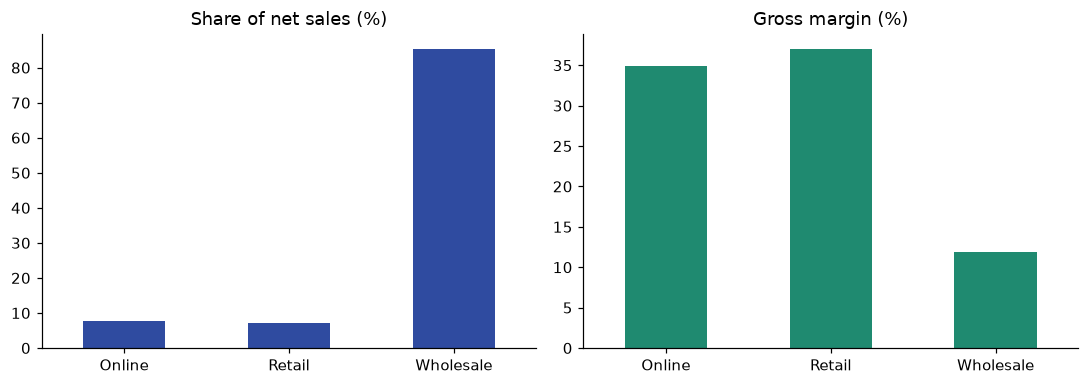

In [15]:
s = clean['Sales_Transactions']
ch = s.groupby('Channel').agg(net_sales=('Net_Sales_EGP', 'sum'), gross_profit=('Gross_Profit_EGP', 'sum'),
                              units=('Quantity', 'sum'), invoices=('Invoice_ID', 'nunique'))
ch['margin_%'] = (ch.gross_profit / ch.net_sales * 100).round(1)
ch['share_of_sales_%'] = (ch.net_sales / ch.net_sales.sum() * 100).round(1)
ch['share_of_profit_%'] = (ch.gross_profit / ch.gross_profit.sum() * 100).round(1)
display(ch)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ch['share_of_sales_%'].plot.bar(ax=ax[0], color='#2f4ba0'); ax[0].set_title('Share of net sales (%)'); ax[0].set_xlabel('')
ch['margin_%'].plot.bar(ax=ax[1], color='#1f8a70'); ax[1].set_title('Gross margin (%)'); ax[1].set_xlabel('')
for a in ax: a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**First insight (continued in Phase 1):** Wholesale makes up the vast majority of sales, but its margin is far below Retail and Online.
This is exactly Card 01's question: *"Revenue is growing, but is it converting into healthy gross profit?"*

## 9) Save the clean data

In [16]:
for name, df in clean.items():
    df.to_pickle(os.path.join(CLEAN_DIR, f'{name}.pkl'))
dim_date.to_pickle(os.path.join(CLEAN_DIR, 'Dim_Date.pkl'))
print(f'Saved {len(clean)+1} tables to "{CLEAN_DIR}/"')

Saved 21 tables to "clean/"


## 10) Data Quality & Assumptions (delivered with the project)

In [17]:
dq = pd.DataFrame([
 ['Data source',        'Data_Class shows most tables are Modeled (synthetic, for training), anchored to public products and prices. The numbers are not real company financials.'],
 ['Time span',          'October 2023 to September 2026 (36 months).'],
 ['The word "None"',    'Means "no defect / no bottleneck", not missing data. Converted to No Defect and No Bottleneck.'],
 ['Empty cells',        'The only empty cells are Return_Date on invoices that were not returned (expected).'],
 ['Relationships',      'All foreign keys are valid (no orphans). See the table in section 5.'],
 ['Loss-making sales',  'Some wholesale lines have negative gross profit. This is a business insight to analyze in Card 01, not a data error. Not removed.'],
 ['Inventory mismatch', 'A small share of inventory rows do not satisfy the stock balance equation (closing stock is floored at zero). Closing_Stock is used as given.'],
 ['Branches',           'One retail branch (Sidi Bishr) + Online + Wholesale. There are no Cairo/Mansoura branches as shown in the PDF images.'],
 ['PDF mockup figures', 'The numbers in the PDF images (e.g. +28%) are illustrative and not from the data. None were used.'],
 ['Weekend',            'Friday and Saturday assumed in Dim_Date.'],
], columns=['Item', 'Decision / Assumption'])
dq

,Item,Decision / Assumption
0,Data source,"Data_Class shows most tables are Modeled (synthetic, for training), anchored to public products and prices. The numb..."
1,Time span,October 2023 to September 2026 (36 months).
2,"The word ""None""","Means ""no defect / no bottleneck"", not missing data. Converted to No Defect and No Bottleneck."
3,Empty cells,The only empty cells are Return_Date on invoices that were not returned (expected).
4,Relationships,All foreign keys are valid (no orphans). See the table in section 5.
5,Loss-making sales,"Some wholesale lines have negative gross profit. This is a business insight to analyze in Card 01, not a data error...."
6,Inventory mismatch,A small share of inventory rows do not satisfy the stock balance equation (closing stock is floored at zero). Closin...
7,Branches,One retail branch (Sidi Bishr) + Online + Wholesale. There are no Cairo/Mansoura branches as shown in the PDF images.
8,PDF mockup figures,The numbers in the PDF images (e.g. +28%) are illustrative and not from the data. None were used.
9,Weekend,Friday and Saturday assumed in Dim_Date.


---
# THE 10 CASE CARDS

In [18]:
# ---------- Shared setup for Phase 1 ----------
from matplotlib.ticker import FuncFormatter
import matplotlib.dates as mdates

BLUE, GREEN, RED, AMBER, GREY = '#2f4ba0', '#1f8a70', '#c0392b', '#d98e04', '#8a93a6'
mill = FuncFormatter(lambda x, _: f'{x/1e6:,.0f}M' if abs(x) >= 1e6 else f'{x/1e3:,.0f}K' if abs(x) >= 1e3 else f'{x:,.0f}')
pct_fmt = FuncFormatter(lambda x, _: f'{x:.0f}%')
M  = lambda x: f'{x/1e6:,.2f}M'
EG = lambda x: f'{x:,.0f} EGP'
OUT_DIR = 'deliverables'; os.makedirs(OUT_DIR, exist_ok=True)

def fy_label(dates):
    # fiscal year = October to September, e.g. Oct 2023 .. Sep 2024 -> 'FY24'
    y = dates.dt.year + (dates.dt.month >= 10).astype(int)
    return 'FY' + (y % 100).astype(str)

s = clean['Sales_Transactions'].copy()
s['FY'] = fy_label(s.Order_Date)
FYS = sorted(s.FY.unique()); LAST_FY, PREV_FY = FYS[-1], FYS[-2]
DATA_END = s.Order_Date.max()
print('Fiscal years:', FYS, '| last day of data:', DATA_END.date())

# Product attributes joined once
pm = clean['Product_Master'].set_index('Product_ID')
s['Audience'] = s.Product_ID.map(pm.Audience)
unit_econ = s.groupby('Product_ID').agg(net=('Net_Sales_EGP', 'sum'), cogs=('Estimated_COGS_EGP', 'sum'), q=('Quantity', 'sum'))
unit_econ['net_per_unit'] = unit_econ.net / unit_econ.q
unit_econ['cogs_per_unit'] = unit_econ.cogs / unit_econ.q
unit_econ['gp_per_unit'] = unit_econ.net_per_unit - unit_econ.cogs_per_unit
unit_econ['margin'] = 1 - unit_econ.cogs / unit_econ.net
fam = pm.Product_Family

Fiscal years: ['FY24', 'FY25', 'FY26'] | last day of data: 2026-09-30


## Card 01: Executive Sales & Profitability
**Question:** Revenue is growing, but is the growth converting into healthy gross profit across products and channels?

**Approach:** annual KPIs → monthly trend with MoM/YoY → seasonality → product contribution → channel x family margin → discount impact → loss-making sales → a quantified wholesale discount-cap scenario.

In [19]:
# 1.1 Annual KPIs (fiscal years)
fy = s.groupby('FY').agg(net_sales=('Net_Sales_EGP', 'sum'), gross_sales=('Gross_Sales_EGP', 'sum'),
                         units=('Quantity', 'sum'), gross_profit=('Gross_Profit_EGP', 'sum'), customers=('Customer_ID', 'nunique'))
fy['margin_%'] = fy.gross_profit / fy.net_sales * 100
fy['avg_discount_%'] = (1 - fy.net_sales / fy.gross_sales) * 100
fy['net_price_per_unit'] = fy.net_sales / fy.units
fy['sales_growth_%'] = fy.net_sales.pct_change() * 100
fy['units_growth_%'] = fy.units.pct_change() * 100
fy['gp_growth_%'] = fy.gross_profit.pct_change() * 100
fy.round(1)

,net_sales,gross_sales,units,gross_profit,customers,margin_%,avg_discount_%,net_price_per_unit,sales_growth_%,units_growth_%,gp_growth_%
FY,,,,,,,,,,,
FY24,129524345.2,184728652,510545,19805835.8,8225,15.3,29.9,253.7,NaN,NaN,NaN
FY25,143508088.7,204554786,565872,22018781.2,16515,15.3,29.8,253.6,10.8,10.8,11.2
FY26,148305943.7,210808623,584172,23063672.8,23736,15.6,29.6,253.9,3.3,3.2,4.7


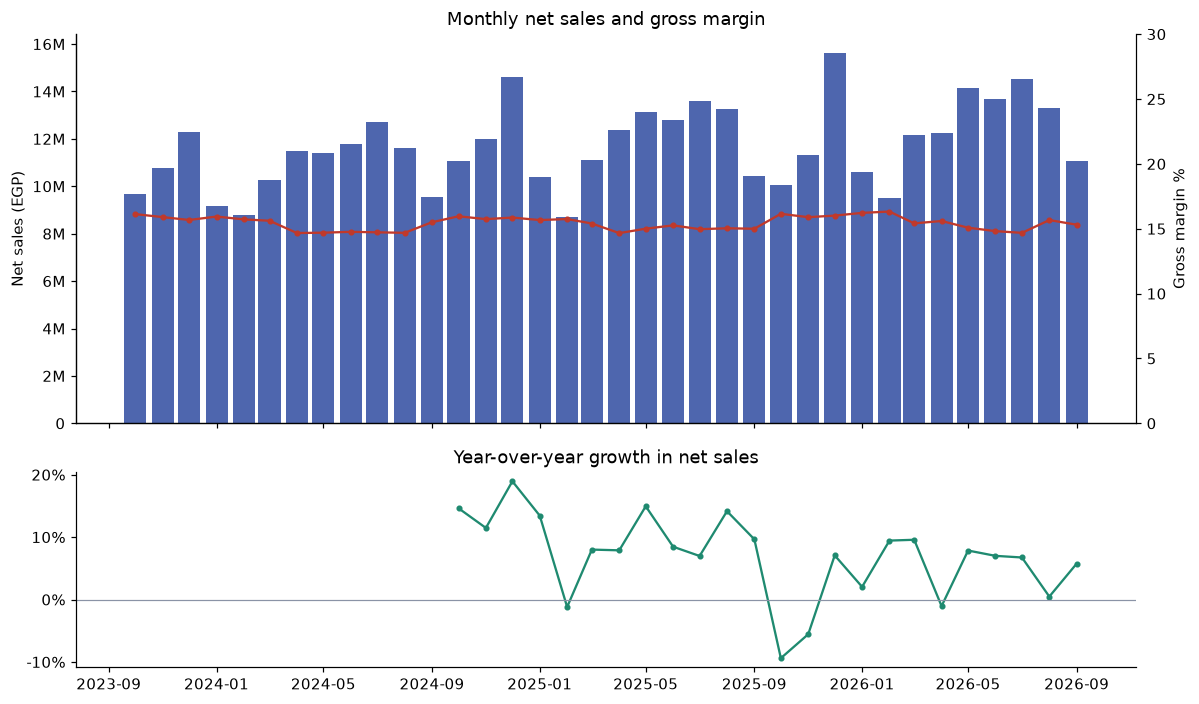

,net_sales,units,gross_profit,gross_sales,margin_%,MoM_%,YoY_%
Month,,,,,,,
2026-04-01,12262286.0,50135,1912359.1,17356456,15.6,0.8,-1.1
2026-05-01,14158935.2,57685,2135185.4,20135170,15.1,15.5,7.9
2026-06-01,13686003.2,56301,2027719.6,19491484,14.8,-3.3,7.0
2026-07-01,14523747.1,59539,2132404.4,20707626,14.7,6.1,6.7
2026-08-01,13312040.6,54091,2085752.3,18845139,15.7,-8.3,0.5
2026-09-01,11055736.6,44198,1692707.4,15696483,15.3,-16.9,5.8


In [20]:
# 1.2 Monthly trend with MoM and YoY
m = s.groupby('Month').agg(net_sales=('Net_Sales_EGP', 'sum'), units=('Quantity', 'sum'),
                           gross_profit=('Gross_Profit_EGP', 'sum'), gross_sales=('Gross_Sales_EGP', 'sum'))
m['margin_%'] = m.gross_profit / m.net_sales * 100
m['MoM_%'] = m.net_sales.pct_change() * 100
m['YoY_%'] = m.net_sales.pct_change(12) * 100

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax[0].bar(m.index, m.net_sales, width=25, color=BLUE, alpha=.85, label='Net sales')
ax[0].yaxis.set_major_formatter(mill); ax[0].set_ylabel('Net sales (EGP)')
a2 = ax[0].twinx(); a2.plot(m.index, m['margin_%'], color=RED, marker='o', ms=3, label='Gross margin %')
a2.set_ylabel('Gross margin %'); a2.spines['right'].set_visible(True); a2.set_ylim(0, 30)
ax[0].set_title('Monthly net sales and gross margin')
ax[1].plot(m.index, m['YoY_%'], color=GREEN, marker='o', ms=3); ax[1].axhline(0, color=GREY, lw=.8)
ax[1].yaxis.set_major_formatter(pct_fmt); ax[1].set_title('Year-over-year growth in net sales')
plt.tight_layout(); plt.show()
m.tail(6).round(1)

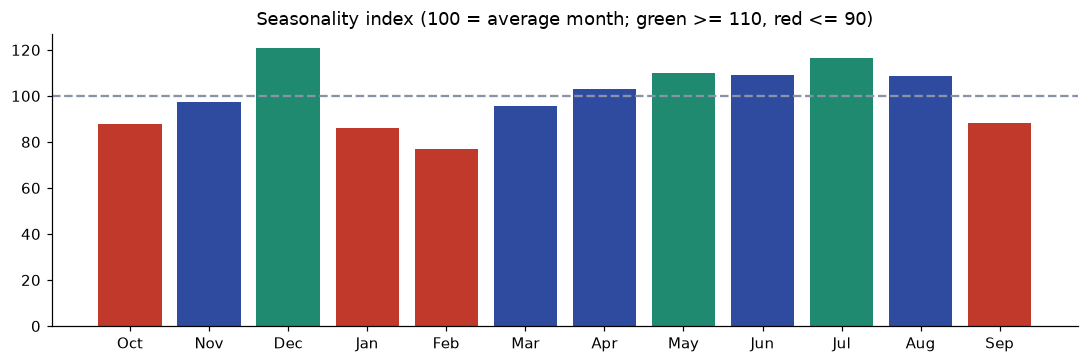

Peak months: Dec (121), Jul (116), May (110)
Low months : Feb (77), Jan (86), Oct (88)


In [21]:
# 1.3 Seasonality index: each month's sales relative to its own fiscal-year monthly average (100 = average month)
sm = m.copy(); sm['FY'] = np.where(sm.index.month >= 10, sm.index.year + 1, sm.index.year); sm['mo'] = sm.index.month
sm['idx'] = sm.net_sales / sm.groupby('FY').net_sales.transform('mean') * 100
season = sm.groupby('mo').idx.mean().reindex([10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9])
names = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar([names[i] for i in season.index], season.values, color=[GREEN if v >= 110 else RED if v <= 90 else BLUE for v in season.values])
ax.axhline(100, color=GREY, ls='--'); ax.set_title('Seasonality index (100 = average month; green >= 110, red <= 90)')
plt.tight_layout(); plt.show()
peak = season.sort_values(ascending=False).head(3); low = season.sort_values().head(3)
print('Peak months:', ', '.join(f'{names[i]} ({v:.0f})' for i, v in peak.items()))
print('Low months :', ', '.join(f'{names[i]} ({v:.0f})' for i, v in low.items()))

,net_sales,units,gross_profit,margin_%,sales_share_%,profit_share_%,growth_last_FY_%
Product_Family,,,,,,,
Pajamas/Homewear,272328992.8,1176405,41184401.9,15.1,64.6,63.5,6.2
Sweatshirts,76583518.1,198807,13725982.8,17.9,18.2,21.2,-0.6
Kids Sets,36453088.0,129980,5274356.8,14.5,8.7,8.1,-0.3
T-Shirts,35972778.6,155397,4703548.4,13.1,8.5,7.2,-5.2


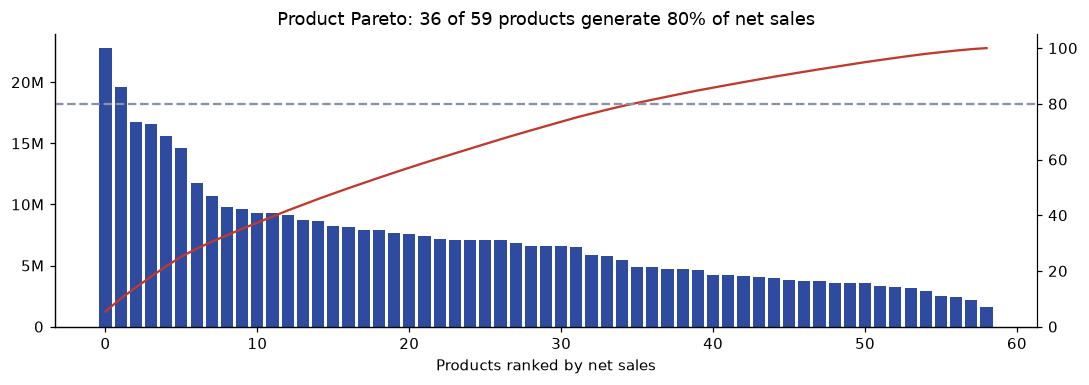

In [22]:
# 1.4 Product contribution: families, then the Pareto of products
pf = s.groupby('Product_Family').agg(net_sales=('Net_Sales_EGP', 'sum'), units=('Quantity', 'sum'), gross_profit=('Gross_Profit_EGP', 'sum'))
pf['margin_%'] = pf.gross_profit / pf.net_sales * 100
pf['sales_share_%'] = pf.net_sales / pf.net_sales.sum() * 100
pf['profit_share_%'] = pf.gross_profit / pf.gross_profit.sum() * 100
# growth FY over FY by family
g = s.pivot_table(index='Product_Family', columns='FY', values='Net_Sales_EGP', aggfunc='sum')
pf['growth_last_FY_%'] = (g[LAST_FY] / g[PREV_FY] - 1) * 100
display(pf.sort_values('net_sales', ascending=False).round(1))

pp = s.groupby(['Product_ID', 'Product_Name']).agg(net_sales=('Net_Sales_EGP', 'sum'), gross_profit=('Gross_Profit_EGP', 'sum')).reset_index()
pp = pp.sort_values('net_sales', ascending=False); pp['cum_share_%'] = pp.net_sales.cumsum() / pp.net_sales.sum() * 100
pp['margin_%'] = pp.gross_profit / pp.net_sales * 100
n80 = int((pp['cum_share_%'] <= 80).sum()) + 1
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(range(len(pp)), pp.net_sales, color=BLUE); ax.yaxis.set_major_formatter(mill)
a2 = ax.twinx(); a2.plot(range(len(pp)), pp['cum_share_%'], color=RED); a2.axhline(80, color=GREY, ls='--'); a2.set_ylim(0, 105); a2.spines['right'].set_visible(True)
ax.set_title(f'Product Pareto: {n80} of {len(pp)} products generate 80% of net sales'); ax.set_xlabel('Products ranked by net sales')
plt.tight_layout(); plt.show()

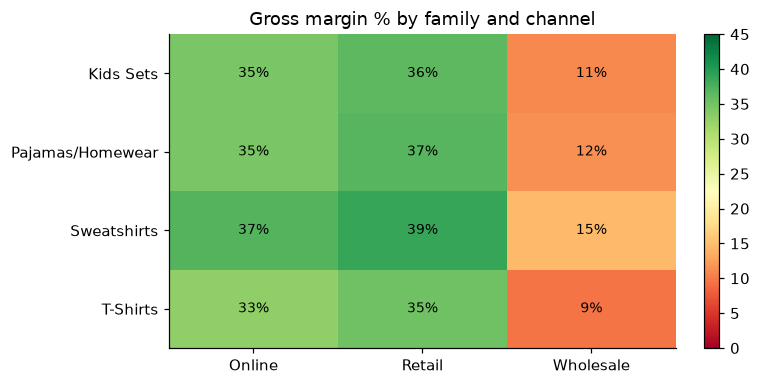

In [23]:
# 1.5 Where is margin made? Channel x Product family gross margin (%)
hm = s.groupby(['Product_Family', 'Channel']).apply(lambda d: d.Gross_Profit_EGP.sum() / d.Net_Sales_EGP.sum() * 100).unstack()
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(hm.values, cmap='RdYlGn', aspect='auto', vmin=0, vmax=45)
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns); ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): ax.text(j, i, f'{hm.values[i, j]:.0f}%', ha='center', va='center', fontsize=9)
ax.set_title('Gross margin % by family and channel'); plt.colorbar(im, ax=ax, fraction=.04); plt.tight_layout(); plt.show()

,Channel,band,lines,net_sales,gp,avg_qty,margin_%,share_of_channel_sales_%
0,Online,0%,23613,11795279.0,4792630.2,1.4,40.6,36.1
1,Online,1-10%,24913,11480364.9,4083452.7,1.4,35.6,35.2
2,Online,11-20%,18745,7739670.3,2171981.4,1.4,28.1,23.7
3,Online,21-30%,4288,1614260.2,336006.4,1.4,20.8,4.9
4,Retail,0%,30249,15197316.0,6165441.4,1.4,40.6,51.8
5,Retail,1-10%,20357,9455351.8,3368225.2,1.4,35.6,32.2
6,Retail,11-20%,11163,4695019.6,1335510.2,1.4,28.4,16.0
7,Wholesale,21-30%,18594,150424327.1,24696010.4,31.5,16.4,41.9
8,Wholesale,31-40%,28078,208936788.6,17939032.0,31.7,8.6,58.1


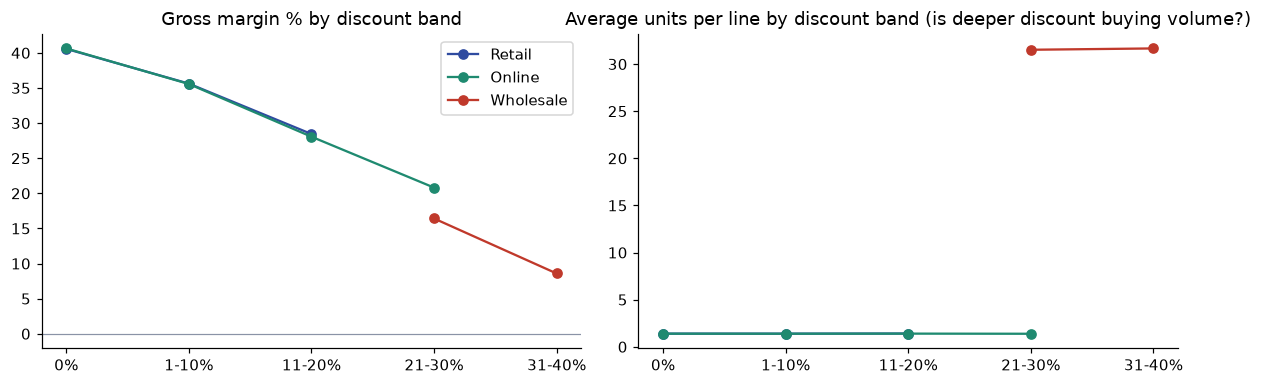

In [24]:
# 1.6 Discount impact
bands = pd.cut(s.Discount_Pct, [-0.001, 0, 0.10, 0.20, 0.30, 0.40], labels=['0%', '1-10%', '11-20%', '21-30%', '31-40%'])
d = s.assign(band=bands).groupby(['Channel', 'band']).agg(lines=('Row_ID', 'count'), net_sales=('Net_Sales_EGP', 'sum'),
        gp=('Gross_Profit_EGP', 'sum'), avg_qty=('Quantity', 'mean')).reset_index()
d['margin_%'] = d.gp / d.net_sales * 100
d['share_of_channel_sales_%'] = d.net_sales / d.groupby('Channel').net_sales.transform('sum') * 100
display(d.round(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for ch, c in zip(['Retail', 'Online', 'Wholesale'], [BLUE, GREEN, RED]):
    x = d[d.Channel == ch]; ax[0].plot(x.band.astype(str), x['margin_%'], marker='o', color=c, label=ch); ax[1].plot(x.band.astype(str), x.avg_qty, marker='o', color=c, label=ch)
ax[0].axhline(0, color=GREY, lw=.8); ax[0].set_title('Gross margin % by discount band'); ax[0].legend()
ax[1].set_title('Average units per line by discount band (is deeper discount buying volume?)')
plt.tight_layout(); plt.show()

In [25]:
# 1.7 Loss-making sales (gross profit < 0)
neg = s[s.Gross_Profit_EGP < 0]
loss_tbl = neg.groupby('Channel').agg(lines=('Row_ID', 'count'), loss_EGP=('Gross_Profit_EGP', 'sum'), avg_discount=('Discount_Pct', 'mean'), net_sales=('Net_Sales_EGP', 'sum')).round(3)
display(loss_tbl)
top_loss = neg.groupby('Product_Name').Gross_Profit_EGP.sum().sort_values().head(8)
print('Top 8 products by loss-making sales:'); display(top_loss.round(0).to_frame('loss_EGP'))
print('Discount at which wholesale lines turn loss-making (share of lines with GP<0 by band):')
w = s[s.Channel == 'Wholesale'].assign(band=bands)
display((w.groupby('band').apply(lambda x: (x.Gross_Profit_EGP < 0).mean() * 100)).round(1).to_frame('% lines loss-making'))

,lines,loss_EGP,avg_discount,net_sales
Channel,,,,
Wholesale,4876,-1374655.95,0.366,35189651.4


Top 8 products by loss-making sales:


,loss_EGP
Product_Name,
Semon - طقم تيشيرت وشورت اطفال صيفي,-418271.0
Boys' summer t-shirt-Beige,-269743.0
Girls' autumn pajamas-Stitch,-180179.0
Boys' sweatshirt-blue,-153830.0
PINK panther - بيجامة حريمي صيفي2024,-88201.0
Positive vibes - 2024بيجامة حريمي صيفي,-54804.0
Summer children's boys-SpongeBob,-31711.0
Boys' summer t-shirt-olive,-29568.0


Discount at which wholesale lines turn loss-making (share of lines with GP<0 by band):


,% lines loss-making
band,
21-30%,0.7
31-40%,16.9


In [26]:
# 1.8 Scenario: cap wholesale discounts. Rows above the cap are re-priced; a retention rate says how much volume survives the higher price.
wh = s[s.Channel == 'Wholesale'].copy()
def cap_scenario(cap, retention):
    over = wh.Discount_Pct > cap
    new_net = wh.Gross_Sales_EGP * (1 - np.minimum(wh.Discount_Pct, cap))
    new_gp = np.where(over, retention * (new_net - wh.Estimated_COGS_EGP), wh.Gross_Profit_EGP)
    return new_gp.sum() - wh.Gross_Profit_EGP.sum(), (over.mean() * 100)
rows = []
for cap in [0.35, 0.30, 0.25, 0.20]:
    for ret in [1.0, 0.9, 0.8, 0.7]:
        dgp, share = cap_scenario(cap, ret); rows.append({'discount_cap': f'{cap:.0%}', 'retention_of_capped_volume': f'{ret:.0%}', 'lines_affected_%': round(share, 1), 'delta_gross_profit_EGP': round(dgp)})
scen = pd.DataFrame(rows).pivot(index='discount_cap', columns='retention_of_capped_volume', values='delta_gross_profit_EGP')
display(scen.style.format('{:,.0f}').background_gradient(cmap='RdYlGn', axis=None))
# Break-even retention for the 30% cap: below this share of volume kept, the cap destroys profit
over = wh.Discount_Pct > 0.30
new_gp_full = (wh.Gross_Sales_EGP * (1 - 0.30) - wh.Estimated_COGS_EGP)[over].sum(); old_gp = wh.Gross_Profit_EGP[over].sum()
be_ret = old_gp / new_gp_full if new_gp_full > 0 else np.nan
print(f'Break-even retention for a 30% cap: {be_ret:.0%} (the cap pays off as long as more than this share of the affected volume is kept)')

retention_of_capped_volume,100%,70%,80%,90%
discount_cap,,,,
20%,"67,223,683","34,266,065","45,251,938","56,237,810"
25%,"40,562,133","15,602,980","23,922,698","32,242,415"
30%,"16,044,166","5,849,207","9,247,527","12,645,846"
35%,"3,200,603","1,415,378","2,010,453","2,605,528"


Break-even retention for a 30% cap: 53% (the cap pays off as long as more than this share of the affected volume is kept)


In [27]:
# 1.9 KEY TAKEAWAYS (all numbers computed)
tot = s.Net_Sales_EGP.sum(); gp = s.Gross_Profit_EGP.sum()
ch = s.groupby('Channel').agg(n=('Net_Sales_EGP', 'sum'), g=('Gross_Profit_EGP', 'sum'))
last, prev = fy.loc[LAST_FY], fy.loc[PREV_FY]
dgp30_90, _ = cap_scenario(0.30, 0.9); dgp30_100, _ = cap_scenario(0.30, 1.0)
print(f'1. Growth: net sales {LAST_FY} = {M(last.net_sales)} EGP ({last["sales_growth_%"]:+.1f}% vs {PREV_FY}); gross profit {last["gp_growth_%"]:+.1f}%; margin {last["margin_%"]:.1f}% vs {prev["margin_%"]:.1f}%.')
print(f'2. Mix: Wholesale = {ch.loc["Wholesale","n"]/tot:.0%} of sales but {ch.loc["Wholesale","g"]/gp:.0%} of gross profit (margin {ch.loc["Wholesale","g"]/ch.loc["Wholesale","n"]:.1%} vs Retail {ch.loc["Retail","g"]/ch.loc["Retail","n"]:.1%}, Online {ch.loc["Online","g"]/ch.loc["Online","n"]:.1%}).')
print(f'3. Concentration: {n80} of {len(pp)} products make 80% of sales; top family = {pf.net_sales.idxmax()} ({pf.net_sales.max()/pf.net_sales.sum():.0%}).')
print(f'4. Leakage: {len(neg):,} loss-making lines ({len(neg)/len(s):.1%}) lose {EG(-neg.Gross_Profit_EGP.sum())}, {neg.Channel.value_counts(normalize=True).iloc[0]:.0%} of them in {neg.Channel.value_counts().index[0]}.')
print(f'5. Action: a 30% wholesale discount cap adds {EG(dgp30_100)} gross profit if all volume stays, {EG(dgp30_90)} at 90% retention; break-even retention is {be_ret:.0%}.')

1. Growth: net sales FY26 = 148.31M EGP (+3.3% vs FY25); gross profit +4.7%; margin 15.6% vs 15.3%.
2. Mix: Wholesale = 85% of sales but 66% of gross profit (margin 11.9% vs Retail 37.0%, Online 34.9%).
3. Concentration: 36 of 59 products make 80% of sales; top family = Pajamas/Homewear (65%).
4. Leakage: 4,876 loss-making lines (2.7%) lose 1,374,656 EGP, 100% of them in Wholesale.
5. Action: a 30% wholesale discount cap adds 16,044,166 EGP gross profit if all volume stays, 12,645,846 EGP at 90% retention; break-even retention is 53%.


## Card 02: Customer 360 & Retention
**Question:** The customer base is growing, but repeat behavior, customer value and retention quality are unclear.

**Approach:** one row per customer → value metrics (AOV, frequency, repeat rate) → RFM segmentation → acquisition cohorts and retention → churn/lapse sizing → high-value profile → a ready-to-use win-back list.


In [28]:
# 2.1 Customer-level table
snap = DATA_END + pd.Timedelta(days=1)
cust = s.groupby('Customer_ID').agg(first_order=('Order_Date', 'min'), last_order=('Order_Date', 'max'), orders=('Invoice_ID', 'nunique'),
        units=('Quantity', 'sum'), net_sales=('Net_Sales_EGP', 'sum'), gp=('Gross_Profit_EGP', 'sum'),
        returns=('Is_Returned', 'sum'), n_channels=('Channel', 'nunique'), main_channel=('Channel', lambda x: x.mode().iat[0]))
cust = cust.join(clean['Customers'].set_index('Customer_ID')[['Customer_Type', 'Governorate', 'Age_Band', 'Gender', 'Join_Date', 'Acquisition_Channel', 'Consent_Status']])
cust['recency_days'] = (snap - cust.last_order).dt.days
cust['AOV'] = cust.net_sales / cust.orders
cust['tenure_days'] = (cust.last_order - cust.first_order).dt.days
cust['is_repeat'] = cust.orders >= 2
print(f'Registered customers: {len(clean["Customers"]):,} | customers with at least one purchase: {len(cust):,} ({len(cust)/len(clean["Customers"]):.0%})')
summary = cust.groupby('Customer_Type').agg(customers=('orders', 'size'), net_sales=('net_sales', 'sum'), orders=('orders', 'sum'),
        avg_orders=('orders', 'mean'), median_orders=('orders', 'median'), repeat_rate=('is_repeat', 'mean'), AOV=('AOV', 'mean'),
        avg_recency=('recency_days', 'mean'))
summary['repeat_rate'] = summary.repeat_rate * 100
summary['sales_per_customer'] = summary.net_sales / summary.customers
display(summary.round(1))
rc = cust[cust.Customer_Type == 'Retail'].copy()      # B2C customers: used for RFM, cohorts, churn, profile
wc = cust[cust.Customer_Type == 'Wholesale'].copy()   # B2B accounts: analysed separately (they buy ~28x per year and would distort B2C metrics)
print(f'B2C customers: {len(rc):,} | B2B accounts: {len(wc):,}')

Registered customers: 30,000 | customers with at least one purchase: 25,634 (85%)


,customers,net_sales,orders,avg_orders,median_orders,repeat_rate,AOV,avg_recency,sales_per_customer
Customer_Type,,,,,,,,,
Retail,24035,77367845.9,135053,5.6,4.0,83.5,495.6,143.5,3219.0
Wholesale,1599,343970531.6,44947,28.1,21.0,96.1,7654.5,35.1,215116.0


B2C customers: 24,035 | B2B accounts: 1,599


In [29]:
# 2.2 Do some acquisition sources bring better customers? (B2C only)
acq = rc.groupby('Acquisition_Channel').agg(customers=('orders', 'size'), repeat_rate=('is_repeat', 'mean'), avg_orders=('orders', 'mean'),
        sales_per_customer=('net_sales', lambda x: x.mean()), gp_per_customer=('gp', 'mean'), avg_recency=('recency_days', 'mean'))
acq['repeat_rate'] *= 100
display(acq.sort_values('gp_per_customer', ascending=False).round(1))
retail_only = rc
print('Retail customers only: share with 1 order / 2-3 orders / 4+ orders')
print(pd.cut(retail_only.orders, [0, 1, 3, 10_000], labels=['1 order', '2-3 orders', '4+ orders']).value_counts(normalize=True).sort_index().mul(100).round(1).to_string())

,customers,repeat_rate,avg_orders,sales_per_customer,gp_per_customer,avg_recency
Acquisition_Channel,,,,,,
Referral,2149,84.0,5.7,3247.8,1013.9,147.3
Direct / WhatsApp,5349,83.3,5.6,3248.6,1008.7,142.1
Organic Social,4796,83.8,5.7,3255.4,1007.7,146.6
Paid Social,4374,83.7,5.7,3181.4,1003.6,142.2
Store Walk-in,4477,83.6,5.6,3193.6,999.8,140.7
Google Search,2890,82.5,5.5,3178.3,991.3,144.8


Retail customers only: share with 1 order / 2-3 orders / 4+ orders
orders
1 order       16.5
2-3 orders    26.1
4+ orders     57.4


,customers,net_sales,gp,avg_orders,avg_recency,AOV,customer_share_%,sales_share_%
segment,,,,,,,,
"Cannot Lose (high value, lapsing)",3726,24456981.0,7141626.8,10.1,265.9,575.5,15.5,31.6
Champions,3991,23826007.6,7274869.3,10.1,39.4,533.8,16.6,30.8
Loyal,1897,11627522.1,3505714.6,10.1,104.3,547.1,7.9,15.0
Potential Loyalists,2902,5690048.2,2025942.6,4.2,61.1,464.1,12.1,7.4
At Risk,1905,3797984.6,1361162.9,4.2,264.4,473.4,7.9,4.9
Hibernating,3983,3344863.4,1198106.7,1.8,268.7,463.9,16.6,4.3
New / Promising,3680,3042400.0,1079390.2,1.8,40.3,446.5,15.3,3.9
Need Attention,1951,1582039.0,551404.5,1.8,104.8,440.3,8.1,2.0


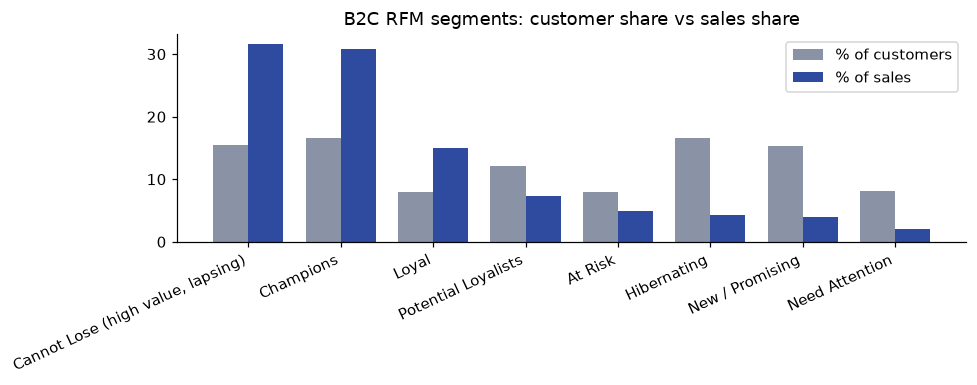

In [30]:
# 2.3 RFM segmentation of B2C customers (quintile scores; ranks used to handle ties)
def score(series, ascending=True):
    r = series.rank(method='first', ascending=ascending)
    return pd.qcut(r, 5, labels=[1, 2, 3, 4, 5]).astype(int)
rc['R'] = score(rc.recency_days, ascending=False)     # recent = high score
rc['F'] = score(rc.orders)
rc['Mon'] = score(rc.net_sales)
def segment(r):
    if r.R >= 4 and r.F >= 4: return 'Champions'
    if r.R >= 3 and r.F >= 4: return 'Loyal'
    if r.R >= 4 and r.F <= 2: return 'New / Promising'
    if r.R >= 3 and r.F == 3: return 'Potential Loyalists'
    if r.R <= 2 and r.F >= 4: return 'Cannot Lose (high value, lapsing)'
    if r.R <= 2 and r.F == 3: return 'At Risk'
    if r.R <= 2: return 'Hibernating'
    return 'Need Attention'
rc['segment'] = rc.apply(segment, axis=1)
seg = rc.groupby('segment').agg(customers=('orders', 'size'), net_sales=('net_sales', 'sum'), gp=('gp', 'sum'), avg_orders=('orders', 'mean'), avg_recency=('recency_days', 'mean'), AOV=('AOV', 'mean'))
seg['customer_share_%'] = seg.customers / seg.customers.sum() * 100
seg['sales_share_%'] = seg.net_sales / seg.net_sales.sum() * 100
seg = seg.sort_values('net_sales', ascending=False)
display(seg.round(1))
fig, ax = plt.subplots(figsize=(9, 3.6)); x = np.arange(len(seg)); w = .38
ax.bar(x - w/2, seg['customer_share_%'], w, color=GREY, label='% of customers'); ax.bar(x + w/2, seg['sales_share_%'], w, color=BLUE, label='% of sales')
ax.set_xticks(x); ax.set_xticklabels(seg.index, rotation=25, ha='right'); ax.legend(); ax.set_title('B2C RFM segments: customer share vs sales share'); plt.tight_layout(); plt.show()

In [31]:
# 2.3b B2B wholesale accounts: concentration and silence
wc = wc.sort_values('net_sales', ascending=False)
wc['cum_share_%'] = wc.net_sales.cumsum() / wc.net_sales.sum() * 100
print(f'Top 10 accounts = {wc.net_sales.head(10).sum()/wc.net_sales.sum():.1%} of wholesale sales | top 100 = {wc.net_sales.head(100).sum()/wc.net_sales.sum():.1%} | accounts needed for 50% of sales: {(wc["cum_share_%"] <= 50).sum() + 1}')
print(f'Account GP margin range (middle 80% of accounts): {(wc.gp/wc.net_sales).quantile(.1):.1%} to {(wc.gp/wc.net_sales).quantile(.9):.1%}')
wc['silent_60d'] = wc.recency_days > 60
print(f'Accounts silent for more than 60 days: {wc.silent_60d.sum()} ({wc.silent_60d.mean():.1%}) | their historical annual sales: {EG(wc[wc.silent_60d].net_sales.sum() / ((DATA_END - s.Order_Date.min()).days / 365))}')
display(wc[['Governorate', 'orders', 'net_sales', 'gp', 'recency_days']].head(8).round(0))

Top 10 accounts = 2.5% of wholesale sales | top 100 = 19.9% | accounts needed for 50% of sales: 335
Account GP margin range (middle 80% of accounts): 8.6% to 14.9%
Accounts silent for more than 60 days: 279 (17.4%) | their historical annual sales: 18,682,512 EGP


,Governorate,orders,net_sales,gp,recency_days
Customer_ID,,,,,
C13551,Sharqia,106,876177.0,111754.0,43
C00582,Alexandria,108,873820.0,108334.0,79
C29367,Alexandria,114,869903.0,102199.0,56
C05154,Port Said,106,848698.0,106685.0,91
C14068,Kafr El Sheikh,120,838875.0,95869.0,1
C15641,Kafr El Sheikh,103,834198.0,105680.0,5
C12699,Dakahlia,113,833133.0,104147.0,24
C04044,Beheira,120,831137.0,107381.0,49


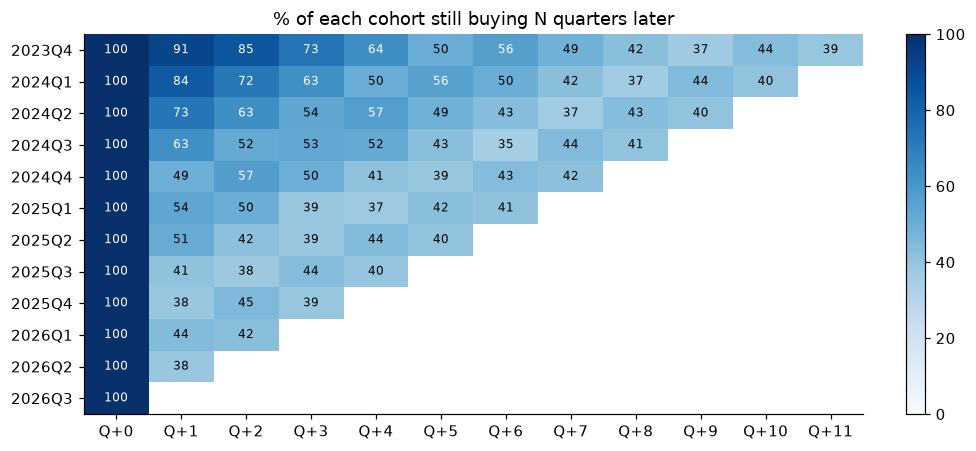

cohort,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
new_customers,2006.0,1779.0,2080.0,1835.0,1963.0,1771.0,2337.0,1994.0,1925.0,1850.0,2342.0,2153.0
share_of_all_%,8.3,7.4,8.7,7.6,8.2,7.4,9.7,8.3,8.0,7.7,9.7,9.0


Note: the first cohort (Q4 2023) includes customers who already existed before the data starts, so its size is inflated.


In [32]:
# 2.4 B2C acquisition cohorts and quarterly retention (cohort = quarter of FIRST purchase)
q = s[s.Customer_ID.isin(rc.index)][['Customer_ID', 'Order_Date']].copy(); q['qtr'] = q.Order_Date.dt.to_period('Q')
active = q.drop_duplicates(['Customer_ID', 'qtr'])
cohort = rc.first_order.dt.to_period('Q').rename('cohort')
active = active.join(cohort, on='Customer_ID'); active['offset'] = (active.qtr - active.cohort).apply(lambda x: x.n)
cnt = active.groupby(['cohort', 'offset']).Customer_ID.nunique().unstack()
ret = cnt.div(cnt[0], axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(ret.values, cmap='Blues', aspect='auto', vmin=0, vmax=100)
ax.set_xticks(range(ret.shape[1])); ax.set_xticklabels([f'Q+{c}' for c in ret.columns]); ax.set_yticks(range(len(ret))); ax.set_yticklabels(ret.index.astype(str))
for i in range(ret.shape[0]):
    for j in range(ret.shape[1]):
        if not np.isnan(ret.values[i, j]): ax.text(j, i, f'{ret.values[i, j]:.0f}', ha='center', va='center', fontsize=8, color='white' if ret.values[i, j] > 55 else 'black')
ax.set_title('% of each cohort still buying N quarters later'); plt.colorbar(im, ax=ax, fraction=.04); plt.tight_layout(); plt.show()
cs = cnt[0].to_frame('new_customers'); cs['share_of_all_%'] = cs.new_customers / cs.new_customers.sum() * 100; display(cs.round(1).T)
print('Note: the first cohort (Q4 2023) includes customers who already existed before the data starts, so its size is inflated.')

segment,At Risk,"Cannot Lose (high value, lapsing)",Champions,Hibernating,Loyal,Need Attention,New / Promising,Potential Loyalists
customers,1905.0,3726.0,3991.0,3983.0,1897.0,1951.0,3680.0,2902.0
lapsed_pct,71.1,69.7,0.0,68.4,0.0,0.0,0.0,0.0


Median gap between consecutive orders: 32 days | 90th percentile: 180 days. The 180-day lapse threshold sits at about the 90th percentile gap, so it flags customers who are quiet far longer than normal.


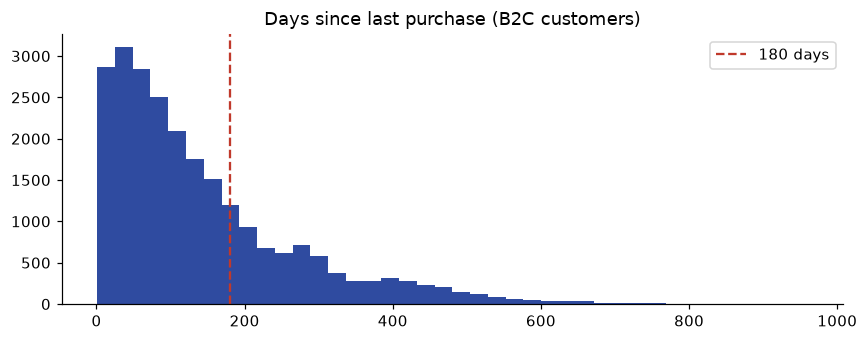

Lapsed B2C customers: 6,675 | their historical sales per year = 7,381,033 EGP (gross profit 2,256,598 EGP)


In [33]:
# 2.5 Churn / lapse sizing (a customer is 'lapsed' when silent for more than LAPSE_DAYS)
LAPSE_DAYS = 180
rc['lapsed'] = rc.recency_days > LAPSE_DAYS
by_seg = rc.groupby('segment').agg(customers=('lapsed', 'size'), lapsed_pct=('lapsed', 'mean'))
by_seg['lapsed_pct'] *= 100; display(by_seg.round(1).T)
# typical buying rhythm: median gap between orders for repeat customers, to validate the lapse threshold
gaps = s.sort_values(['Customer_ID', 'Order_Date']).groupby('Customer_ID').Order_Date.diff().dt.days.dropna()
print(f'Median gap between consecutive orders: {gaps.median():.0f} days | 90th percentile: {gaps.quantile(.9):.0f} days. The {LAPSE_DAYS}-day lapse threshold sits at about the 90th percentile gap, so it flags customers who are quiet far longer than normal.')
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.hist(rc.recency_days, bins=40, color=BLUE); ax.axvline(LAPSE_DAYS, color=RED, ls='--', label=f'{LAPSE_DAYS} days')
ax.set_title('Days since last purchase (B2C customers)'); ax.legend(); plt.tight_layout(); plt.show()
# Annual value of lapsed retail customers = revenue we could lose each year if nobody comes back
lapsed_val = rc[rc.lapsed]
yrs = (DATA_END - s.Order_Date.min()).days / 365
print(f'Lapsed B2C customers: {len(lapsed_val):,} | their historical sales per year = {EG(lapsed_val.net_sales.sum()/yrs)} (gross profit {EG(lapsed_val.gp.sum()/yrs)})')

In [ ]:
# 2.6 Top 10% by net sales vs all B2C customers 
rc['top10'] = rc.net_sales >= rc.net_sales.quantile(.9)
print(f'Top 10% of B2C customers = {rc[rc.top10].net_sales.sum()/rc.net_sales.sum():.0%} of B2C net sales | {rc[rc.top10].gp.sum()/rc.gp.sum():.0%} of B2C gross profit | they buy {rc[rc.top10].orders.mean():.1f} times vs {rc[~rc.top10].orders.mean():.1f}')
def lift(col):
    a = rc[rc.top10][col].value_counts(normalize=True); b = rc[col].value_counts(normalize=True)
    return pd.DataFrame({'top10_%': a * 100, 'all_%': b * 100, 'lift': a / b}).round(2).sort_values('lift', ascending=False)
for col in ['Acquisition_Channel', 'Governorate', 'Age_Band', 'Gender']:
    print(f'\n{col}:'); display(lift(col).head(6))

Top 10% of B2C customers = 43% of B2C net sales | 35% of B2C gross profit | they buy 16.2 times vs 4.4

Acquisition_Channel:


,top10_%,all_%,lift
Acquisition_Channel,,,
Direct / WhatsApp,23.17,22.26,1.04
Store Walk-in,18.72,18.63,1.0
Google Search,11.98,12.02,1.0
Organic Social,19.72,19.95,0.99
Paid Social,18.01,18.2,0.99
Referral,8.4,8.94,0.94



Governorate:


,top10_%,all_%,lift
Governorate,,,
Other,6.53,6.0,1.09
Monufia,3.24,3.01,1.08
Dakahlia,6.49,6.11,1.06
Alexandria,29.2,28.05,1.04
Sharqia,5.2,5.07,1.03
Beheira,8.07,7.91,1.02



Age_Band:


,top10_%,all_%,lift
Age_Band,,,
25-34,39.85,37.7,1.06
35-44,31.36,31.48,1.0
45-54,14.64,15.26,0.96
55+,5.78,6.05,0.96
18-24,8.36,9.51,0.88



Gender:


,top10_%,all_%,lift
Gender,,,
Not specified,3.29,3.01,1.09
Female,66.89,66.72,1.0
Male,29.83,30.27,0.99


In [35]:
# 2.7 Win-back list: lapsed customers ranked by historical gross profit, reachable only if they opted in
win = rc[rc.lapsed & (rc.Consent_Status == 'Opted-in') & (rc.orders >= 2)].sort_values('gp', ascending=False)
win_out = win[['Customer_Type', 'Governorate', 'Acquisition_Channel', 'orders', 'net_sales', 'gp', 'recency_days', 'segment']].head(500).reset_index()
win_out.to_csv(os.path.join(OUT_DIR, 'winback_list_top500.csv'), index=False)
print(f'B2C win-back universe (lapsed, opted-in, 2+ orders): {len(win):,} customers, historical GP {EG(win.gp.sum())}. Top 500 saved to deliverables/winback_list_top500.csv')
display(win_out.head(8).round(0))
wh_risk = wc[wc.silent_60d].sort_values('gp', ascending=False)[['Governorate', 'orders', 'net_sales', 'gp', 'recency_days']].reset_index()
wh_risk.to_csv(os.path.join(OUT_DIR, 'wholesale_accounts_silent_60d.csv'), index=False)
print(f'Wholesale accounts silent >60 days: {len(wh_risk)} (saved to deliverables/wholesale_accounts_silent_60d.csv)')
opt = cust.groupby('Customer_Type').Consent_Status.apply(lambda x: (x == 'Opted-in').mean() * 100).round(1)
print('Opt-in rate by type (% reachable by marketing):', opt.to_dict())

B2C win-back universe (lapsed, opted-in, 2+ orders): 3,574 customers, historical GP 4,308,263 EGP. Top 500 saved to deliverables/winback_list_top500.csv


,Customer_ID,Customer_Type,Governorate,Acquisition_Channel,orders,net_sales,gp,recency_days,segment
0,C11487,Retail,Monufia,Organic Social,39,108607.0,18818.0,524,"Cannot Lose (high value, lapsing)"
1,C13676,Retail,Alexandria,Organic Social,37,68494.0,15930.0,204,"Cannot Lose (high value, lapsing)"
2,C09713,Retail,Alexandria,Direct / WhatsApp,26,75384.0,15161.0,240,"Cannot Lose (high value, lapsing)"
3,C17065,Retail,Dakahlia,Direct / WhatsApp,31,55283.0,13495.0,391,"Cannot Lose (high value, lapsing)"
4,C12388,Retail,Giza,Paid Social,23,88405.0,13317.0,270,"Cannot Lose (high value, lapsing)"
5,C06468,Retail,Beheira,Google Search,27,42678.0,12247.0,270,"Cannot Lose (high value, lapsing)"
6,C22445,Retail,Alexandria,Direct / WhatsApp,23,53410.0,11906.0,658,"Cannot Lose (high value, lapsing)"
7,C24980,Retail,Beheira,Organic Social,19,53051.0,11123.0,489,"Cannot Lose (high value, lapsing)"


Wholesale accounts silent >60 days: 279 (saved to deliverables/wholesale_accounts_silent_60d.csv)
Opt-in rate by type (% reachable by marketing): {'Retail': 63.9, 'Wholesale': 65.2}


In [36]:
# 2.8 KEY TAKEAWAYS (computed)
sb = s.assign(ctype=s.Customer_ID.map(cust.Customer_Type))
rr = sb[(sb.ctype == 'Retail') & sb.Channel.isin(['Retail', 'Online'])].groupby('FY').agg(buyers=('Customer_ID', 'nunique'), sales=('Net_Sales_EGP', 'sum')); rr['per_buyer'] = rr.sales / rr.buyers
print(f'1. B2C base (Retail + Online channels): active buyers grew from {rr.buyers.iloc[0]:,} ({rr.index[0]}) to {rr.buyers.iloc[-1]:,} ({rr.index[-1]}) (+{rr.buyers.iloc[-1]/rr.buyers.iloc[0]-1:.0%}), while their sales grew only {rr.sales.iloc[-1]/rr.sales.iloc[0]-1:+.0%}: sales per buyer {rr.per_buyer.iloc[0]:,.0f} -> {rr.per_buyer.iloc[-1]:,.0f} EGP.')
print(f'2. Repeat behavior: {rc.is_repeat.mean():.0%} of B2C customers bought at least twice; {(rc.orders>=4).mean():.0%} bought 4+ times. Median customer: {rc.orders.median():.0f} orders.')
spread = acq.gp_per_customer.max() / acq.gp_per_customer.min()
print(f'3. Acquisition source barely matters for value: gross profit per customer ranges only {acq.gp_per_customer.min():,.0f} to {acq.gp_per_customer.max():,.0f} EGP (x{spread:.2f}). Optimise acquisition on cost per customer, not on assumed quality.')
top_seg = seg['sales_share_%'].idxmax()
print(f'4. B2C segments: {top_seg} = {seg.loc[top_seg, "customer_share_%"]:.0f}% of customers and {seg.loc[top_seg, "sales_share_%"]:.0f}% of B2C sales; At Risk + Cannot Lose = {seg.reindex(["Cannot Lose (high value, lapsing)", "At Risk"]).customers.sum():,.0f} customers.')
print(f'5. B2B concentration: top 10 wholesale accounts = {wc.net_sales.head(10).sum()/wc.net_sales.sum():.0%} of wholesale sales; {len(wh_risk)} accounts have been silent for 60+ days.')
print(f'6. Retention action: {len(win):,} reachable lapsed B2C customers (historical GP {EG(win.gp.sum())}); lapsed B2C value = {EG(lapsed_val.gp.sum()/yrs)} gross profit per year. First-quarter retention averages {ret[1].mean():.0f}% across cohorts.')

1. B2C base (Retail + Online channels): active buyers grew from 7,697 (FY24) to 22,137 (FY26) (+188%), while their sales grew only +26%: sales per buyer 2,364 -> 1,034 EGP.
2. Repeat behavior: 84% of B2C customers bought at least twice; 57% bought 4+ times. Median customer: 4 orders.
3. Acquisition source barely matters for value: gross profit per customer ranges only 991 to 1,014 EGP (x1.02). Optimise acquisition on cost per customer, not on assumed quality.
4. B2C segments: Cannot Lose (high value, lapsing) = 16% of customers and 32% of B2C sales; At Risk + Cannot Lose = 5,631 customers.
5. B2B concentration: top 10 wholesale accounts = 2% of wholesale sales; 279 accounts have been silent for 60+ days.
6. Retention action: 3,574 reachable lapsed B2C customers (historical GP 4,308,263 EGP); lapsed B2C value = 2,256,598 EGP gross profit per year. First-quarter retention averages 57% across cohorts.


## Card 03: Branch & Channel Performance
**Question:** Retail, online and wholesale operate differently. Which channel creates value, not just sales volume?

**Approach:** channel scorecard (growth, margin, returns, basket) → location view → geographic demand by governorate → expansion candidates → channel-mix sensitivity.

In [37]:
# 3.1 Channel scorecard
ch = s.groupby('Channel').agg(net_sales=('Net_Sales_EGP', 'sum'), gross_profit=('Gross_Profit_EGP', 'sum'), units=('Quantity', 'sum'), invoices=('Invoice_ID', 'nunique'),
        customers=('Customer_ID', 'nunique'), returned_lines=('Is_Returned', 'sum'), refunds=('Refund_Value_EGP', 'sum'), quality_returns=('Is_Quality_Return', 'sum'))
ch['margin_%'] = ch.gross_profit / ch.net_sales * 100
ch['AOV'] = ch.net_sales / ch.invoices
ch['units_per_invoice'] = ch.units / ch.invoices
ch['GP_per_invoice'] = ch.gross_profit / ch.invoices
ch['return_rate_%'] = ch.returned_lines / ch.invoices * 100
ch['refund_%_of_sales'] = ch.refunds / ch.net_sales * 100
ch['sales_share_%'] = ch.net_sales / ch.net_sales.sum() * 100
ch['profit_share_%'] = ch.gross_profit / ch.gross_profit.sum() * 100
g = s.pivot_table(index='Channel', columns='FY', values='Net_Sales_EGP', aggfunc='sum')
for a, b in zip(FYS[:-1], FYS[1:]): ch[f'growth_{b}_%'] = (g[b] / g[a] - 1) * 100
ch['GP_after_refunds'] = ch.gross_profit - ch.refunds
ch['margin_after_refunds_%'] = ch.GP_after_refunds / ch.net_sales * 100   # upper-bound exposure: assumes refunded goods cannot be resold
display(ch.round(1).T)

Channel,Online,Retail,Wholesale
net_sales,32629574.4,29347687.4,359361115.7
gross_profit,11384070.7,10869176.8,42635042.4
units,99339.0,86174.0,1475076.0
invoices,71559.0,61769.0,46672.0
customers,21560.0,19472.0,2754.0
returned_lines,5537.0,2174.0,832.0
refunds,2400579.4,959860.4,6066565.8
quality_returns,1600.0,634.0,223.0
margin_%,34.9,37.0,11.9
AOV,456.0,475.1,7699.7


In [ ]:
# 3.1b Data-quality check
ctype = clean['Customers'].set_index('Customer_ID').Customer_Type
xt = s.assign(ctype=s.Customer_ID.map(ctype)).pivot_table(index=['Channel', 'ctype'], columns='FY', values='Net_Sales_EGP', aggfunc='sum').fillna(0)
display(xt.round(0))
mis = s[(s.Channel == 'Wholesale') & (s.Customer_ID.map(ctype) == 'Retail')]
print(f'{len(mis):,} lines ({EG(mis.Net_Sales_EGP.sum())}) were sold through the Wholesale channel to Retail-type customers, all in: {sorted(mis.FY.unique())}.')
wb = s[(s.Channel == 'Wholesale') & (s.Customer_ID.map(ctype) == 'Wholesale')].groupby('FY').Net_Sales_EGP.sum()
wh_growth_clean = wb.pct_change() * 100
print('Wholesale growth as reported:', (g.loc['Wholesale'].pct_change() * 100).round(1).dropna().to_dict(), '| for true B2B customers only:', wh_growth_clean.round(1).dropna().to_dict())
print('Decision: channel analysis keeps Channel as recorded (it follows the selling location); B2B vs B2C customer analysis uses Customer_Type. The FY24 mismatch is documented as a data limitation.')

FY                         FY24         FY25         FY26
Channel   ctype                                          
Online    Retail      8387059.0   10694326.0   13485181.0
          Wholesale     63009.0          0.0          0.0
Retail    Retail      9806439.0   10085767.0    9400814.0
          Wholesale     54668.0          0.0          0.0
Wholesale Retail     15508260.0          0.0          0.0
          Wholesale  95704911.0  122727996.0  125419948.0

1,961 lines (15,508,260 EGP) were sold through the Wholesale channel to Retail-type customers, all in: ['FY24'].
Wholesale growth as reported: {'FY25': 10.4, 'FY26': 2.2} | for true B2B customers only: {'FY25': 28.2, 'FY26': 2.2}
Decision: channel analysis keeps Channel as recorded (it follows the selling location); B2B vs B2C customer analysis uses Customer_Type. The FY24 mismatch is documented as a data limitation.


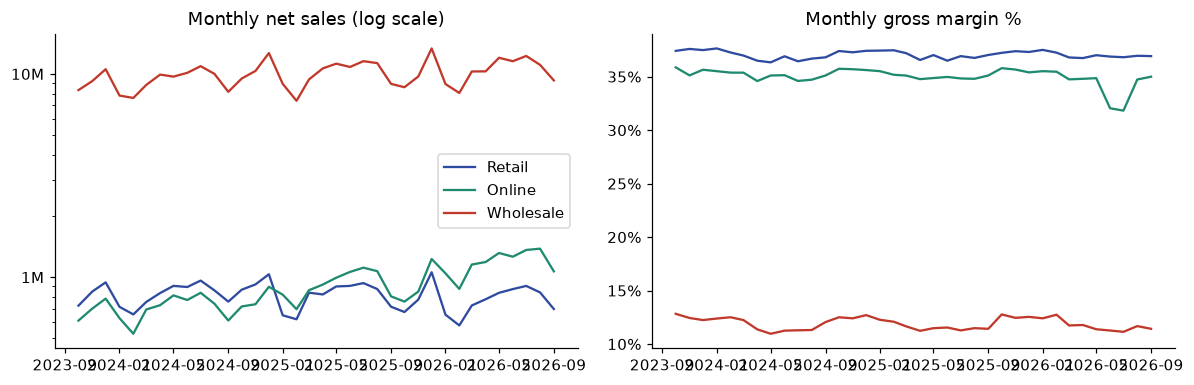

In [39]:
# 3.2 Growth and margin trend by channel (monthly)
mc = s.groupby(['Month', 'Channel']).agg(n=('Net_Sales_EGP', 'sum'), g=('Gross_Profit_EGP', 'sum')).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for c_, col in zip(['Retail', 'Online', 'Wholesale'], [BLUE, GREEN, RED]):
    x = mc[mc.Channel == c_]; ax[0].plot(x.Month, x.n, color=col, label=c_); ax[1].plot(x.Month, x.g / x.n * 100, color=col, label=c_)
ax[0].set_yscale('log'); ax[0].yaxis.set_major_formatter(mill); ax[0].set_title('Monthly net sales (log scale)'); ax[0].legend()
ax[1].yaxis.set_major_formatter(pct_fmt); ax[1].set_title('Monthly gross margin %')
plt.tight_layout(); plt.show()

In [40]:
# 3.3 Returns by channel and reason (refund value)
ret_tbl = s[s.Is_Returned == 1].pivot_table(index='Return_Reason', columns='Channel', values='Refund_Value_EGP', aggfunc='sum').fillna(0)
ret_tbl['total'] = ret_tbl.sum(axis=1); display(ret_tbl.sort_values('total', ascending=False).round(0))
rate = s.groupby(['Channel', 'Product_Family']).Is_Returned.mean().unstack() * 100
display(rate.round(1))

Channel,Online,Retail,Wholesale,total
Return_Reason,,,,
Size / fit,841931.0,331855.0,2338806.0,3512592.0
Fabric / stitching,394460.0,162114.0,953162.0,1509735.0
Changed mind,375440.0,152084.0,943935.0,1471459.0
Color / appearance,294867.0,117469.0,667295.0,1079631.0
Print issue,297485.0,112218.0,590461.0,1000164.0
Delivery issue,196395.0,84122.0,572908.0,853425.0


Product_Family,Kids Sets,Pajamas/Homewear,Sweatshirts,T-Shirts
Channel,,,,
Online,7.6,7.7,8.2,7.5
Retail,3.5,3.5,3.4,3.6
Wholesale,1.5,1.8,1.8,2.0


Channel,Online,Retail,Wholesale,total,direct (Retail+Online),share_of_total_%,direct_share_%
Customer_Governorate,,,,,,,
Alexandria,9290866.6,8268310.6,105934901.7,123494079.0,17559177.2,29.3,28.3
Cairo,5791146.1,5264355.8,62917627.6,73973129.4,11055501.8,17.6,17.8
Giza,3542601.2,3214609.4,42016679.0,48773889.5,6757210.6,11.6,10.9
Beheira,2621112.6,2308844.6,30208051.1,35138008.3,4929957.2,8.3,8.0
Dakahlia,2000728.6,1847253.5,23960902.2,27808884.3,3847982.1,6.6,6.2
Gharbia,1918192.6,1769895.8,19288531.2,22976619.6,3688088.4,5.5,6.0
Sharqia,1646820.3,1415958.8,17750504.9,20813284.1,3062779.2,4.9,4.9
Other,1971227.0,1760122.6,16897770.3,20629119.9,3731349.6,4.9,6.0
Kafr El Sheikh,1355473.6,1234896.0,13415101.3,16005471.0,2590369.7,3.8,4.2


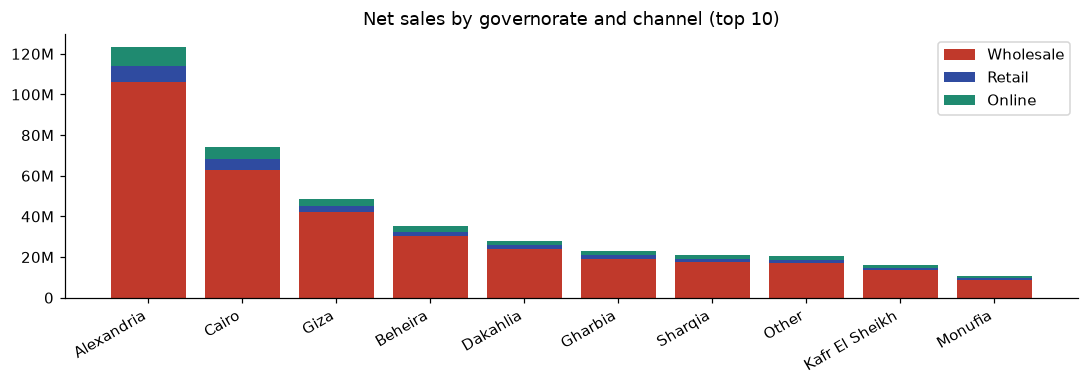

In [41]:
# 3.4 Geographic demand: where do customers buy from?
geo = s.pivot_table(index='Customer_Governorate', columns='Channel', values='Net_Sales_EGP', aggfunc='sum').fillna(0)
geo['total'] = geo.sum(axis=1); geo['direct (Retail+Online)'] = geo.Retail + geo.Online
geo['share_of_total_%'] = geo.total / geo.total.sum() * 100
geo['direct_share_%'] = geo['direct (Retail+Online)'] / geo['direct (Retail+Online)'].sum() * 100
geo = geo.sort_values('total', ascending=False); display(geo.head(12).round(1))
top = geo.head(10)
fig, ax = plt.subplots(figsize=(10, 3.6)); bottom = np.zeros(len(top))
for c_, col in zip(['Wholesale', 'Retail', 'Online'], [RED, BLUE, GREEN]):
    ax.bar(top.index, top[c_], bottom=bottom, color=col, label=c_); bottom += top[c_].values
ax.yaxis.set_major_formatter(mill); ax.legend(); ax.set_title('Net sales by governorate and channel (top 10)'); plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

In [42]:
# 3.5 Expansion candidates: governorates with strong DIRECT (retail + online) demand but no physical store.
# Score = 55% size of direct demand + 30% growth + 15% low return rate (each min-max scaled).
# Margin is not scored: it is almost identical across governorates (~36%), so it cannot discriminate.
# Governorates with direct sales below MIN_DIRECT are excluded because growth on a tiny base is noise; the 'Other' bucket is not a place.
STORE_GOV = clean['Locations'].set_index('Location_ID').loc['LOC001', 'Governorate']
d = s[s.Channel.isin(['Retail', 'Online'])]
gv = d.groupby('Customer_Governorate').agg(direct_sales=('Net_Sales_EGP', 'sum'), gp=('Gross_Profit_EGP', 'sum'), customers=('Customer_ID', 'nunique'), ret=('Is_Returned', 'mean'))
gv['margin'] = gv.gp / gv.direct_sales
gg = d.pivot_table(index='Customer_Governorate', columns='FY', values='Net_Sales_EGP', aggfunc='sum')
gv['growth'] = (gg[LAST_FY] / gg[PREV_FY] - 1)
MIN_DIRECT = 1_000_000
gv = gv[(gv.index != 'Other') & (gv.direct_sales >= MIN_DIRECT)].copy()
mm = lambda x: (x - x.min()) / (x.max() - x.min()) if x.max() > x.min() else x * 0
gv['score'] = (.55 * mm(gv.direct_sales) + .30 * mm(gv.growth.fillna(0)) + .15 * (1 - mm(gv.ret))) * 100
gv['has_store'] = gv.index == STORE_GOV
gv = gv.sort_values('score', ascending=False)
display(gv.head(10).assign(growth=lambda x: x.growth * 100, margin=lambda x: x.margin * 100, ret=lambda x: x.ret * 100).round(1))
cands = gv[~gv.has_store].head(3)
print('Expansion shortlist (no store today):', ', '.join(cands.index), '| existing store governorate:', STORE_GOV, f'({gv.loc[STORE_GOV, "direct_sales"]/gv.direct_sales.sum():.0%} of direct sales)')

,direct_sales,gp,customers,ret,margin,growth,score,has_store
Customer_Governorate,,,,,,,,
Alexandria,17559177.2,6302440.8,6764,5.7,35.9,9.2,70.8,True
Monufia,1807371.0,651616.0,726,5.1,36.1,15.2,45.8,False
Giza,6757210.6,2432424.7,2666,6.3,36.0,14.7,45.7,False
Cairo,11055501.8,3973758.0,4356,5.8,35.9,7.5,42.9,False
Port Said,1172317.2,418467.6,456,5.5,35.7,15.6,40.5,False
Sharqia,3062779.2,1097892.1,1222,5.8,35.8,11.9,30.8,False
Beheira,4929957.2,1768044.7,1909,5.7,35.9,9.5,30.0,False
Gharbia,3688088.4,1325489.7,1419,5.4,35.9,8.9,27.5,False
Dakahlia,3847982.1,1375639.0,1475,6.1,35.7,10.0,23.0,False


Expansion shortlist (no store today): Monufia, Giza, Cairo | existing store governorate: Alexandria (30% of direct sales)


In [ ]:
# 3.6 Channel-mix sensitivity
wh_net = ch.loc['Wholesale', 'net_sales']; wh_gp = ch.loc['Wholesale', 'gross_profit']
WH_UNITS = s[s.Channel == 'Wholesale'].Quantity.sum(); DR = s[s.Channel != 'Wholesale']
gp_unit_gain = DR.Gross_Profit_EGP.sum() / DR.Quantity.sum() - wh_gp / WH_UNITS   # extra gross profit per unit sold direct instead of wholesale
direct_margin = (ch.loc[['Retail', 'Online'], 'gross_profit'].sum() / ch.loc[['Retail', 'Online'], 'net_sales'].sum())
direct_price_uplift = (s[s.Channel != 'Wholesale'].Net_Sales_EGP.sum() / s[s.Channel != 'Wholesale'].Quantity.sum()) / (s[s.Channel == 'Wholesale'].Net_Sales_EGP.sum() / s[s.Channel == 'Wholesale'].Quantity.sum())
print(f'Net price per unit, direct vs wholesale: x{direct_price_uplift:.2f} | direct margin {direct_margin:.1%} vs wholesale {wh_gp/wh_net:.1%}')
rows = []
for shift in [0.01, 0.02, 0.05]:
    for conv in [0.5, 1.0]:
        # shifted wholesale sales move to direct at the wholesale unit volume but direct net price per unit; 'conv' = share of shifted volume actually won
        units_shift = WH_UNITS * shift * conv
        lost_units = WH_UNITS * shift * (1 - conv)                     # volume that leaves wholesale but is not won direct
        delta = units_shift * gp_unit_gain - lost_units * (wh_gp / WH_UNITS)
        rows.append({'wholesale_volume_shifted': f'{shift:.0%}', 'share_of_it_won_direct': f'{conv:.0%}', 'delta_gross_profit_EGP': round(delta)})
display(pd.DataFrame(rows).pivot(index='wholesale_volume_shifted', columns='share_of_it_won_direct', values='delta_gross_profit_EGP').style.format('{:,.0f}'))

Net price per unit, direct vs wholesale: x1.37 | direct margin 35.9% vs wholesale 11.9%


share_of_it_won_direct,100%,50%
wholesale_volume_shifted,,
1%,"1,343,080","458,365"
2%,"2,686,160","916,729"
5%,"6,715,399","2,291,823"


In [44]:
# 3.7 KEY TAKEAWAYS (computed)
best_gp_inv = ch['GP_per_invoice'].idxmax()
print(f'1. Value, not volume: {ch["sales_share_%"].idxmax()} = {ch["sales_share_%"].max():.0f}% of sales but {ch.loc[ch["sales_share_%"].idxmax(), "profit_share_%"]:.0f}% of gross profit. Best gross profit per invoice: {best_gp_inv} ({ch.loc[best_gp_inv, "GP_per_invoice"]:,.0f} EGP).')
print(f'2. Returns: return rate Retail {ch.loc["Retail","return_rate_%"]:.1f}% | Online {ch.loc["Online","return_rate_%"]:.1f}% | Wholesale {ch.loc["Wholesale","return_rate_%"]:.1f}%; refunds cost {EG(ch.refunds.sum())} in total.')
gcol = [c for c in ch.columns if c.startswith('growth_')][-1]
print(f'3. Growth {gcol.replace("growth_", "").replace("_%", "")} vs prior year: ' + ' | '.join(f'{k} {v:+.1f}%' for k, v in ch[gcol].items()) + f'. (Wholesale excluding the FY24 retail-customer lines: {wh_growth_clean.iloc[-1]:+.1f}%.)')
print(f'4. Geography: top governorates by total sales = {", ".join(geo.head(3).index)} ({geo.head(3).total.sum()/geo.total.sum():.0%} of sales). Expansion shortlist: {", ".join(cands.index)}.')
print(f'5. Mix: every 1% of wholesale volume that could be sold direct at current direct economics adds about {EG(WH_UNITS * 0.01 * gp_unit_gain)} gross profit over the 3 years of data (about {EG(WH_UNITS * 0.01 * gp_unit_gain / 3)} per year).')
print(f'6. Refund exposure: online loses {ch.loc["Online","refund_%_of_sales"]:.1f}% of its sales to refunds vs {ch.loc["Retail","refund_%_of_sales"]:.1f}% in retail; margin after refunds (upper bound) Online {ch.loc["Online","margin_after_refunds_%"]:.1f}% vs Retail {ch.loc["Retail","margin_after_refunds_%"]:.1f}%.')

1. Value, not volume: Wholesale = 85% of sales but 66% of gross profit. Best gross profit per invoice: Wholesale (914 EGP).
2. Returns: return rate Retail 3.5% | Online 7.7% | Wholesale 1.8%; refunds cost 9,427,006 EGP in total.
3. Growth FY26 vs prior year: Online +26.1% | Retail -6.8% | Wholesale +2.2%. (Wholesale excluding the FY24 retail-customer lines: +2.2%.)
4. Geography: top governorates by total sales = Alexandria, Cairo, Giza (58% of sales). Expansion shortlist: Monufia, Giza, Cairo.
5. Mix: every 1% of wholesale volume that could be sold direct at current direct economics adds about 1,343,080 EGP gross profit over the 3 years of data (about 447,693 EGP per year).
6. Refund exposure: online loses 7.4% of its sales to refunds vs 3.3% in retail; margin after refunds (upper bound) Online 27.5% vs Retail 33.8%.


## Card 04: Inventory & Demand Planning
**Question:** Some SKUs tie up cash while fast movers hit stockout days. No forecast is supplied.

**Approach:** reconcile inventory to sales → ABC/XYZ → turns and days of cover → stockout and overstock diagnosis in EGP → **own 30/60/90-day forecast** (4 candidate models, back-tested, best one chosen) → replenishment logic with priorities.

In [ ]:
# 4.0 Setup + reconciliation
inv = clean['Inventory_History'].copy(); inv['Month'] = inv.Snapshot_Month
inv['Channel'] = inv.Location_ID.map(clean['Locations'].set_index('Location_ID').Channel)
LAST_M = inv.Month.max()
a = inv.groupby(['Month', 'Location_ID']).Sold_Qty.sum()
b = s.groupby(['Month', 'Location_ID']).Quantity.sum()
diff = (a - b.reindex(a.index)).abs()
print(f'Inventory Sold_Qty vs Sales Quantity by month x location: max difference = {diff.max():.0f} units -> {"fully reconciled" if diff.max() == 0 else "differences exist"}.')
print('Latest snapshot:', LAST_M.date(), '| series (product x location):', inv.groupby(['Product_ID', 'Location_ID']).ngroups)

Inventory Sold_Qty vs Sales Quantity by month x location: max difference = 0 units -> fully reconciled.
Latest snapshot: 2026-09-01 | series (product x location): 177


In [46]:
# 4.1 ABC (value) x XYZ (demand variability) on the last 12 months
s12 = s[s.Order_Date > DATA_END - pd.DateOffset(months=12)]
pv = s12.groupby('Product_ID').agg(net=('Net_Sales_EGP', 'sum'), units=('Quantity', 'sum'))
monthly = s12.pivot_table(index='Product_ID', columns='Month', values='Quantity', aggfunc='sum').fillna(0)
pv['cv'] = monthly.std(axis=1) / monthly.mean(axis=1)
pv = pv.sort_values('net', ascending=False); pv['cum'] = pv.net.cumsum() / pv.net.sum()
pv['ABC'] = np.where(pv.cum <= .80, 'A', np.where(pv.cum <= .95, 'B', 'C'))
X_MAX, Y_MAX = 0.5, 0.7   # assumption: CV <= 0.5 stable (X), <= 0.7 variable (Y), above = erratic (Z)
pv['XYZ'] = np.where(pv.cv <= X_MAX, 'X', np.where(pv.cv <= Y_MAX, 'Y', 'Z'))
pv['class'] = pv.ABC + pv.XYZ
print(f'CV thresholds: X <= {X_MAX}, Y <= {Y_MAX}, Z above (observed CV range {pv.cv.min():.2f} to {pv.cv.max():.2f})')
mat = pv.pivot_table(index='ABC', columns='XYZ', values='net', aggfunc='count').fillna(0).astype(int)
share = pv.pivot_table(index='ABC', columns='XYZ', values='net', aggfunc='sum').fillna(0) / pv.net.sum() * 100
display(mat); display(share.round(1))

CV thresholds: X <= 0.5, Y <= 0.7, Z above (observed CV range 0.39 to 0.99)


XYZ,X,Y,Z
ABC,,,
A,10,13,12
B,8,5,2
C,5,3,1


XYZ,X,Y,Z
ABC,,,
A,22.0,29.8,28.1
B,7.8,4.7,1.9
C,2.7,2.2,0.7


In [47]:
# 4.2 Stock turns, days of cover, reorder status (latest snapshot) per product x location
last = inv[inv.Month == LAST_M].copy()
l12 = inv[inv.Month > LAST_M - pd.DateOffset(months=12)]
turn = l12.groupby(['Product_ID', 'Location_ID']).agg(sold12=('Sold_Qty', 'sum'), avg_stock=('Closing_Stock', 'mean'), so_days=('Stockout_Days_In_Month', 'sum')).reset_index()
turn['turns'] = turn.sold12 / turn.avg_stock.replace(0, np.nan)
last = last.merge(turn, on=['Product_ID', 'Location_ID'])
last = last.join(pv[['ABC', 'XYZ', 'class']], on='Product_ID')
bychan = last.groupby('Channel').agg(skus=('Product_ID', 'count'), closing_units=('Closing_Stock', 'sum'), median_cover_days=('Days_of_Cover', 'median'),
        turns_median=('turns', 'median'), at_or_below_reorder_pct=('Closing_Stock', lambda x: (x <= last.loc[x.index, 'Reorder_Point_Units']).mean() * 100),
        cover_over_120_pct=('Days_of_Cover', lambda x: (x > 120).mean() * 100))
display(bychan.round(1))
byabc = last.groupby('ABC').agg(skus=('Product_ID', 'count'), median_cover=('Days_of_Cover', 'median'), median_turns=('turns', 'median'), stockout_days_12m=('so_days', 'sum'))
display(byabc.round(1))

,skus,closing_units,median_cover_days,turns_median,at_or_below_reorder_pct,cover_over_120_pct
Channel,,,,,,
Online,59,25542,112.6,2.9,3.4,49.2
Retail,59,21097,118.4,3.0,3.4,49.2
Wholesale,59,31228,11.0,24.6,61.0,10.2


,skus,median_cover,median_turns,stockout_days_12m
ABC,,,,
A,105,59.2,5.8,516
B,45,112.6,2.7,60
C,27,180.9,1.6,67


In [ ]:
# 4.3 Diagnosis in EGP
price = s.groupby(['Product_ID', 'Channel']).agg(n=('Net_Sales_EGP', 'sum'), g=('Gross_Profit_EGP', 'sum'), c=('Estimated_COGS_EGP', 'sum'), q=('Quantity', 'sum'))
price['net_unit'] = price.n / price.q; price['gp_unit'] = price.g / price.q; price['cogs_unit'] = price.c / price.q
inv = inv.join(price[['net_unit', 'gp_unit', 'cogs_unit']], on=[inv.Product_ID, inv.Channel]) if False else inv.merge(price[['net_unit', 'gp_unit', 'cogs_unit']].reset_index(), on=['Product_ID', 'Channel'], how='left')
inv['lost_units'] = inv.Stockout_Days_In_Month * inv.Avg_Daily_Sales_90D
inv['lost_rev'] = inv.lost_units * inv.net_unit; inv['lost_gp'] = inv.lost_units * inv.gp_unit
so = inv[inv.Stockout_Days_In_Month > 0]
so12 = so[so.Month > LAST_M - pd.DateOffset(months=12)]
print(f'Stockout days in the data: {int(inv.Stockout_Days_In_Month.sum()):,} | in last 12 months: {int(so12.Stockout_Days_In_Month.sum()):,}')
print(f'Estimated lost sales (stockout days x avg daily sales x net price): {EG(so.lost_rev.sum())} total, {EG(so12.lost_rev.sum())} last 12 months; lost gross profit last 12 months: {EG(so12.lost_gp.sum())}')
display(so.groupby('Channel').agg(stockout_days=('Stockout_Days_In_Month', 'sum'), lost_rev=('lost_rev', 'sum'), lost_gp=('lost_gp', 'sum'), affected_series=('Product_ID', 'nunique')).round(0))
top_so = so12.groupby(['Product_ID', 'Product_Name']).agg(days=('Stockout_Days_In_Month', 'sum'), lost_gp=('lost_gp', 'sum')).sort_values('lost_gp', ascending=False).head(8)
display(top_so.round(0))
# Overstock: stock above OVER_DAYS of cover is considered excess; cash tied = excess units x COGS per unit
OVER_DAYS = 120
last = last.merge(price[['cogs_unit', 'net_unit', 'gp_unit']].reset_index(), on=['Product_ID', 'Channel'], how='left')
last['excess_units'] = np.maximum(0, last.Closing_Stock - OVER_DAYS * last.Avg_Daily_Sales_90D)
last['excess_cash'] = last.excess_units * last.cogs_unit
print(f'\nOverstock (> {OVER_DAYS} days of cover): {int((last.excess_units > 0).sum())} of {len(last)} product-locations hold {last.excess_units.sum():,.0f} excess units = {EG(last.excess_cash.sum())} of cash at cost')
display(last.groupby('Channel').agg(excess_units=('excess_units', 'sum'), excess_cash=('excess_cash', 'sum')).round(0))
display(last.sort_values('excess_cash', ascending=False)[['Product_Name', 'Channel', 'Closing_Stock', 'Avg_Daily_Sales_90D', 'Days_of_Cover', 'excess_cash']].head(8).round(1))

Stockout days in the data: 1,197 | in last 12 months: 643
Estimated lost sales (stockout days x avg daily sales x net price): 8,813,248 EGP total, 4,894,427 EGP last 12 months; lost gross profit last 12 months: 710,174 EGP


,stockout_days,lost_rev,lost_gp,affected_series
Channel,,,,
Online,30,34162.0,12191.0,1
Retail,14,26490.0,10350.0,2
Wholesale,1153,8752595.0,1064869.0,23


,,days,lost_gp
Product_ID,Product_Name,,
P001,Summer children's girls-Happy,46,149878.0
P006,Summer children's boys-Sonic,90,126623.0
P049,Fuchsia - طقم تيشيرت وشورت اطفال صيفي,70,111666.0
P033,Boys' sweatshirt-LEO,15,98192.0
P002,Summer children's girls-turtle,63,43416.0
P004,Summer children's girls-Hello kitty black&white,59,28944.0
P044,Girls' autumn pajamas-Ice Cream,22,28381.0
P008,Summer children's boys-SpongeBob,17,25264.0



Overstock (> 120 days of cover): 64 of 177 product-locations hold 40,043 excess units = 7,292,806 EGP of cash at cost


,excess_units,excess_cash
Channel,,
Online,15613.0,2895024.0
Retail,14435.0,2598751.0
Wholesale,9996.0,1799031.0


,Product_Name,Channel,Closing_Stock,Avg_Daily_Sales_90D,Days_of_Cover,excess_cash
112,Gazelle - بيجامة حريمي صيفي2024,Online,3115,1.5,2133.6,637783.4
53,Gazelle - بيجامة حريمي صيفي2024,Retail,2954,0.8,3516.7,618995.4
81,Girls' summer pajamas-Dumbo,Online,3497,0.5,6725.0,601880.8
22,Girls' summer pajamas-Dumbo,Retail,3057,0.5,5878.8,524775.8
18,Boys' summer pajamas- Seeds OF,Retail,3399,0.6,5395.2,515492.3
99,Boys' Autumn Pajamas-Jurassic Park,Online,3343,0.8,4285.9,510905.3
40,Boys' Autumn Pajamas-Jurassic Park,Retail,3230,0.2,12920.0,503138.0
77,Boys' summer pajamas- Seeds OF,Online,3303,1.4,2342.6,486083.3


In [ ]:
# 4.4 Demand forecast
piv = inv.pivot_table(index=['Product_ID', 'Location_ID'], columns='Month', values='Sold_Qty', aggfunc='sum').fillna(0)
Y = piv.values.astype(float); n = Y.shape[1]
def f_naive(Y, h): return np.repeat(Y[:, -1:], h, axis=1)
def f_ma3(Y, h): return np.repeat(Y[:, -3:].mean(axis=1, keepdims=True), h, axis=1)
def f_snaive_growth(Y, h):
    n = Y.shape[1]; g = np.clip(Y[:, -12:].sum(1) / np.maximum(Y[:, -24:-12].sum(1), 1), .7, 1.3)
    return Y[:, [n - 12 + k for k in range(h)]] * g[:, None]
def f_trend_season(Y, h):
    n = Y.shape[1]; t = np.arange(n); out = np.zeros((Y.shape[0], h))
    for i, y in enumerate(Y):
        b, a = np.polyfit(t, y, 1); trend = np.maximum(a + b * t, 1e-6)
        seas = np.array([(y / trend)[k::12].mean() for k in range(12)])
        fut = np.arange(n, n + h); out[i] = np.maximum((a + b * fut) * seas[fut % 12], 0)
    return out
MODELS = {'Naive (last month)': f_naive, 'Moving average (3m)': f_ma3, 'Seasonal naive x growth': f_snaive_growth, 'Trend x seasonality': f_trend_season}
H = 3
def wape(A, F): return np.abs(A - F).sum() / A.sum() * 100
rows = []
for name, fn in MODELS.items():
    r = {'model': name}
    for k, cut in enumerate([3, 6]):                 # two rolling origins: hold out the last 3 months, and the 3 months before them
        train = Y[:, :n - cut]; act = Y[:, n - cut:n - cut + H]; fc = fn(train, H)
        r[f'series_WAPE_origin{k+1}_%'] = wape(act, fc)
        r[f'total_WAPE_origin{k+1}_%'] = abs(act.sum(0) - fc.sum(0)).sum() / act.sum() * 100
        r[f'bias_origin{k+1}_%'] = (fc.sum() - act.sum()) / act.sum() * 100
    rows.append(r)
bt = pd.DataFrame(rows).set_index('model'); bt['avg_series_WAPE_%'] = bt[['series_WAPE_origin1_%', 'series_WAPE_origin2_%']].mean(axis=1)
bt = bt.sort_values('avg_series_WAPE_%'); display(bt.round(1))
BEST = bt.index[0]; print('Selected model:', BEST)

,series_WAPE_origin1_%,total_WAPE_origin1_%,bias_origin1_%,series_WAPE_origin2_%,total_WAPE_origin2_%,bias_origin2_%,avg_series_WAPE_%
model,,,,,,,
Trend x seasonality,27.5,11.9,11.9,30.7,4.2,0.3,29.1
Seasonal naive x growth,29.3,3.2,1.9,36.1,3.8,3.8,32.7
Naive (last month),33.7,11.1,7.0,44.5,11.9,-11.9,39.1
Moving average (3m),29.6,10.1,4.0,80.4,24.6,-24.6,55.0


Selected model: Trend x seasonality


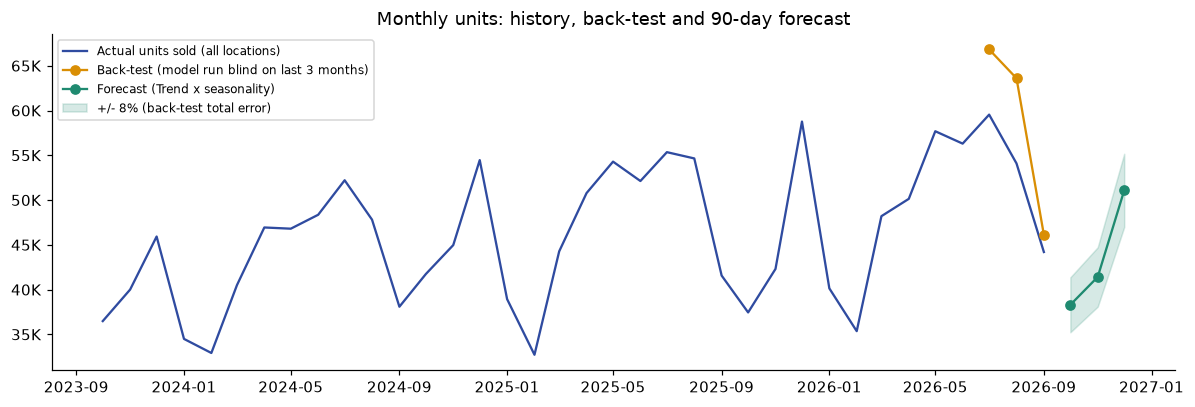

Forecast units (all products, all locations): {'fc_30d': 38303, 'fc_60d': 79717, 'fc_90d': 130797}
Same months last year, for context: 138522 units (Oct-Dec 2025)


In [50]:
# 4.5 Final forecast Oct-Dec 2026 (30/60/90 days = month 1 / months 1-2 / months 1-3)
fc = MODELS[BEST](Y, H)
fut_months = pd.date_range(LAST_M + pd.DateOffset(months=1), periods=H, freq='MS')
fdf = pd.DataFrame(fc, index=piv.index, columns=fut_months)
fdf['fc_30d'] = fdf.iloc[:, 0]; fdf['fc_60d'] = fdf.iloc[:, :2].sum(axis=1); fdf['fc_90d'] = fdf.iloc[:, :3].sum(axis=1)
tot_hist = pd.Series(Y.sum(0), index=piv.columns)
# backtest curve of the chosen model on the last 3 months (for the chart) and its error band at total level
bt_fc = pd.Series(MODELS[BEST](Y[:, :n - 3], 3).sum(0), index=piv.columns[-3:])
band = bt.loc[BEST, ['total_WAPE_origin1_%', 'total_WAPE_origin2_%']].mean() / 100
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(tot_hist.index, tot_hist.values, color=BLUE, label='Actual units sold (all locations)')
ax.plot(bt_fc.index, bt_fc.values, color=AMBER, marker='o', label='Back-test (model run blind on last 3 months)')
f_tot = pd.Series(fc.sum(0), index=fut_months)
ax.plot(f_tot.index, f_tot.values, color=GREEN, marker='o', label=f'Forecast ({BEST})')
ax.fill_between(f_tot.index, f_tot.values * (1 - band), f_tot.values * (1 + band), color=GREEN, alpha=.18, label=f'+/- {band:.0%} (back-test total error)')
ax.yaxis.set_major_formatter(mill); ax.legend(loc='upper left', fontsize=8); ax.set_title('Monthly units: history, back-test and 90-day forecast'); plt.tight_layout(); plt.show()
print('Forecast units (all products, all locations):', {k: round(float(fdf[k].sum())) for k in ['fc_30d', 'fc_60d', 'fc_90d']})
print('Same months last year, for context:', round(float(tot_hist.iloc[-12:-9].sum())), 'units (Oct-Dec 2025)')

In [ ]:
# 4.6 Replenishment logic per product x location (assumption: nothing is on order),
#   daily demand = 90-day forecast / 90 | lead-time demand = daily x supplier lead time,
#   reorder point = lead-time demand + safety stock | target stock = daily x (lead time + 30 days review cover) + safety stock
REVIEW_DAYS = 30
rp = last.set_index(['Product_ID', 'Location_ID']).join(fdf[['fc_30d', 'fc_60d', 'fc_90d']])
rp['daily_fc'] = rp.fc_90d / 90
rp['lead_time_demand'] = rp.daily_fc * rp.Supplier_Lead_Time_Days
rp['reorder_point'] = rp.lead_time_demand + rp.Safety_Stock_Units
rp['target_stock'] = rp.daily_fc * (rp.Supplier_Lead_Time_Days + REVIEW_DAYS) + rp.Safety_Stock_Units
rp['order_qty'] = np.ceil(np.maximum(0, rp.target_stock - rp.Closing_Stock))
rp['cover_days_fc'] = rp.Closing_Stock / rp.daily_fc.replace(0, np.nan)
def status(r):
    if r.daily_fc <= 0: return 'No demand'
    if r.Closing_Stock < r.lead_time_demand: return '1-CRITICAL: runs out before an order can arrive'
    if r.Closing_Stock <= r.reorder_point: return '2-REORDER NOW'
    if r.cover_days_fc > OVER_DAYS: return '4-OVERSTOCK: hold / promote'
    return '3-OK'
rp['status'] = rp.apply(status, axis=1)
rp['order_value_at_cost'] = rp.order_qty * rp.cogs_unit
summ = rp.groupby('status').agg(series=('Product_Name', 'count'), units_to_order=('order_qty', 'sum'), order_value=('order_value_at_cost', 'sum'), excess_cash=('excess_cash', 'sum')).round(0)
display(summ)
plan = rp[rp.order_qty > 0].sort_values(['status', 'order_value_at_cost'], ascending=[True, False]).reset_index()
plan_out = plan[['Product_ID', 'Product_Name', 'Channel', 'ABC', 'XYZ', 'Closing_Stock', 'Safety_Stock_Units', 'Supplier_Lead_Time_Days', 'daily_fc', 'reorder_point', 'order_qty', 'order_value_at_cost', 'status']]
plan_out.to_csv(os.path.join(OUT_DIR, 'replenishment_plan.csv'), index=False)
print(f'Replenishment plan saved: deliverables/replenishment_plan.csv ({len(plan_out)} lines). Top 10 by urgency and value:')
display(plan_out.head(10).round(1))

,series,units_to_order,order_value,excess_cash
status,,,,
1-CRITICAL: runs out before an order can arrive,32,32638.0,6587507.0,0.0
2-REORDER NOW,9,6557.0,1480592.0,0.0
3-OK,65,7178.0,1803599.0,665760.0
4-OVERSTOCK: hold / promote,71,0.0,0.0,6627046.0


Replenishment plan saved: deliverables/replenishment_plan.csv (63 lines). Top 10 by urgency and value:


,Product_ID,Product_Name,Channel,ABC,XYZ,Closing_Stock,Safety_Stock_Units,Supplier_Lead_Time_Days,daily_fc,reorder_point,order_qty,order_value_at_cost,status
0,P033,Boys' sweatshirt-LEO,Wholesale,A,Z,45,49,7,44.3,359.1,1643.0,465756.6,1-CRITICAL: runs out before an order can arrive
1,P008,Summer children's boys-SpongeBob,Wholesale,A,Y,413,586,10,46.7,1053.3,2043.0,446256.5,1-CRITICAL: runs out before an order can arrive
2,P005,Summer children's boys-Black and orange,Wholesale,A,Y,140,672,21,27.2,1244.0,1922.0,421307.3,1-CRITICAL: runs out before an order can arrive
3,P014,Boys' summer t-shirt-Black,Wholesale,A,X,104,643,21,27.5,1219.7,1940.0,403104.0,1-CRITICAL: runs out before an order can arrive
4,P039,Boys' Autumn Pajamas-Spider Man,Wholesale,A,Z,258,171,21,41.4,1039.6,2023.0,366720.3,1-CRITICAL: runs out before an order can arrive
5,P044,Girls' autumn pajamas-Ice Cream,Wholesale,A,Z,0,74,14,38.5,613.7,1771.0,301191.9,1-CRITICAL: runs out before an order can arrive
6,P045,Girls' autumn pajamas-Stitch,Wholesale,A,Z,207,89,14,36.9,605.9,1507.0,296716.3,1-CRITICAL: runs out before an order can arrive
7,P002,Summer children's girls-turtle,Wholesale,A,Y,0,367,21,20.3,793.6,1404.0,284287.1,1-CRITICAL: runs out before an order can arrive
8,P048,Semon - طقم تيشيرت وشورت اطفال صيفي,Wholesale,A,X,0,144,5,22.5,256.6,933.0,260987.9,1-CRITICAL: runs out before an order can arrive
9,P043,Girls' autumn pajamas-Snow White,Wholesale,A,Z,61,67,10,38.1,448.1,1531.0,255710.1,1-CRITICAL: runs out before an order can arrive


In [52]:
# 4.7 KEY TAKEAWAYS (computed)
crit = rp[rp.status.str.startswith('1')]; reo = rp[rp.status.str.startswith('2')]; ovr = rp[rp.status.str.startswith('4')]
share_wh = so.groupby('Channel').lost_rev.sum() / so.lost_rev.sum()
print(f'1. Classification: {int((pv.ABC == "A").sum())} A-products make 80% of last-12-month sales; {int((pv["class"] == "AZ").sum())} are AZ (high value AND erratic demand: the hardest to plan).')
print(f'2. Stockouts: {int(so12.Stockout_Days_In_Month.sum()):,} stockout days in the last 12 months, {share_wh.idxmax()} accounts for {share_wh.max():.0%} of the lost sales. Estimated lost gross profit (last 12 months): {EG(so12.lost_gp.sum())}.')
print(f'3. Overstock: {EG(last.excess_cash.sum())} of cash sits in stock beyond {OVER_DAYS} days of cover ({int((last.excess_units>0).sum())} product-locations).')
print(f'4. Forecast: best model = {BEST} (series-level WAPE {bt.iloc[0]["avg_series_WAPE_%"]:.0f}%, total-level error about {band:.0%}). Next 90 days: {fdf.fc_90d.sum():,.0f} units.')
print(f'5. Action: {len(crit)} product-locations are CRITICAL and {len(reo)} need reordering now; the plan orders {plan.order_qty.sum():,.0f} units worth {EG(plan.order_value_at_cost.sum())} at cost. {len(ovr)} overstocked lines should be held or promoted.')

1. Classification: 35 A-products make 80% of last-12-month sales; 12 are AZ (high value AND erratic demand: the hardest to plan).
2. Stockouts: 643 stockout days in the last 12 months, Wholesale accounts for 99% of the lost sales. Estimated lost gross profit (last 12 months): 710,174 EGP.
3. Overstock: 7,292,806 EGP of cash sits in stock beyond 120 days of cover (64 product-locations).
4. Forecast: best model = Trend x seasonality (series-level WAPE 29%, total-level error about 8%). Next 90 days: 130,797 units.
5. Action: 32 product-locations are CRITICAL and 9 need reordering now; the plan orders 46,373 units worth 9,871,698 EGP at cost. 71 overstocked lines should be held or promoted.


## Card 05: Marketing Effectiveness
**Question:** Spend is spread across platforms, but efficiency by campaign, product and period is invisible.

**Approach:** campaign metrics (CTR, CPC, conversion, CAC, ROAS) → **profit-based ROAS** (revenue x product margin vs spend) → platform, product-family and period views → outliers → budget reallocation scenario → web funnel.

In [53]:
# 5.1 Campaign metrics
mk = clean['Marketing'].copy()
mk['Family'] = mk.Product_ID.map(fam)
mk['Month'] = mk.Start_Date.dt.to_period('M').dt.to_timestamp()
mk['FY'] = fy_label(mk.Start_Date)
mk['CTR_%'] = mk.Clicks / mk.Impressions * 100
mk['CPC'] = mk.Spend_EGP / mk.Clicks
mk['CPM'] = mk.Spend_EGP / mk.Impressions * 1000
mk['Conv_%'] = mk.Orders_Attributed / mk.Landing_Page_Sessions * 100
mk['CAC'] = mk.Spend_EGP / mk.Orders_Attributed.replace(0, np.nan)
mk['ROAS'] = mk.Attributed_Revenue_EGP / mk.Spend_EGP
mk['margin'] = mk.Product_ID.map(unit_econ.margin)
mk['gross_profit_attr'] = mk.Attributed_Revenue_EGP * mk.margin
mk['contribution'] = mk.gross_profit_attr - mk.Spend_EGP        # gross profit generated minus the money spent
mk['profit_ROAS'] = mk.gross_profit_attr / mk.Spend_EGP
mk['breakeven_ROAS'] = 1 / mk.margin
print(f'{len(mk)} campaigns | spend {EG(mk.Spend_EGP.sum())} | attributed revenue {EG(mk.Attributed_Revenue_EGP.sum())} | blended ROAS {mk.Attributed_Revenue_EGP.sum()/mk.Spend_EGP.sum():.2f}x')
def agg(g):
    r = g.agg(campaigns=('Campaign_ID', 'count'), spend=('Spend_EGP', 'sum'), impressions=('Impressions', 'sum'), clicks=('Clicks', 'sum'),
              sessions=('Landing_Page_Sessions', 'sum'), orders=('Orders_Attributed', 'sum'), revenue=('Attributed_Revenue_EGP', 'sum'),
              gp_attr=('gross_profit_attr', 'sum'), contribution=('contribution', 'sum'))
    r['CTR_%'] = r.clicks / r.impressions * 100; r['CPC'] = r.spend / r.clicks; r['Conv_%'] = r.orders / r.sessions * 100
    r['CAC'] = r.spend / r.orders; r['ROAS'] = r.revenue / r.spend; r['profit_ROAS'] = r.gp_attr / r.spend
    r['spend_share_%'] = r.spend / r.spend.sum() * 100
    return r
plat = agg(mk.groupby('Platform')).sort_values('ROAS', ascending=False)
display(plat.drop(columns=['impressions', 'clicks', 'sessions']).round(2))

420 campaigns | spend 14,583,976 EGP | attributed revenue 179,741,957 EGP | blended ROAS 12.32x


,campaigns,spend,orders,revenue,gp_attr,contribution,CTR_%,CPC,Conv_%,CAC,ROAS,profit_ROAS,spend_share_%
Platform,,,,,,,,,,,,,
WhatsApp / CRM,42,1546750,212023,1.035723e+08,17757081.02,16210331.02,5.60,0.43,5.89,7.30,66.96,11.48,10.61
Google,117,3890507,80618,3.995280e+07,5694275.04,1803768.04,3.77,2.12,4.40,48.26,10.27,1.46,26.68
TikTok,65,2238109,21402,1.091526e+07,1673717.28,-564391.72,2.27,1.93,1.84,104.57,4.88,0.75,15.35
Meta,153,5437904,46851,2.374271e+07,3761434.07,-1676469.93,1.89,2.74,2.36,116.07,4.37,0.69,37.29
Influencer,43,1470706,3120,1.558888e+06,256256.96,-1214449.04,1.24,9.97,2.12,471.38,1.06,0.17,10.08


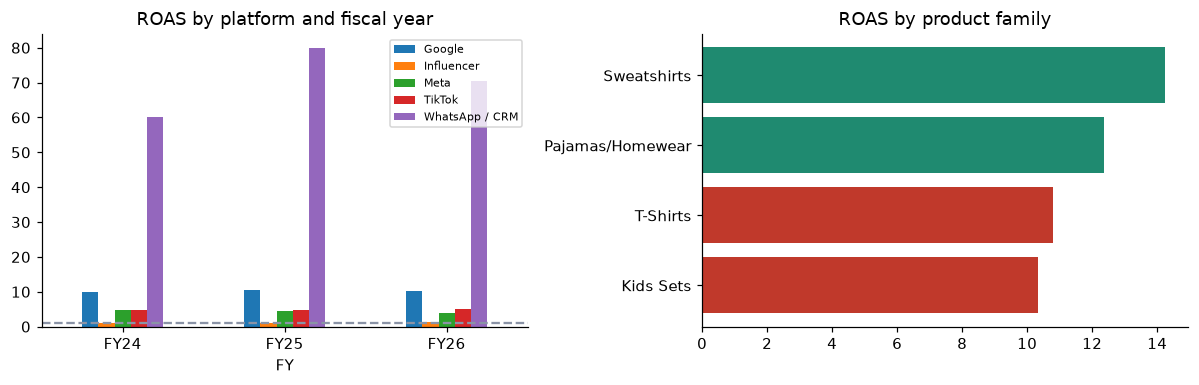

,campaigns,spend,revenue,ROAS,profit_ROAS,contribution,CAC
Family,,,,,,,
Kids Sets,35,1254622,1.297330e+07,10.34,1.79,992721.34,50.12
T-Shirts,37,1156682,1.247529e+07,10.79,1.05,59475.89,39.07
Pajamas/Homewear,288,10066462,1.243113e+08,12.35,1.96,9673431.65,37.38
Sweatshirts,60,2106210,2.998210e+07,14.24,2.82,3833159.49,52.51


In [54]:
# 5.2 Platform x period, and product family
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
yr = agg(mk.groupby(['FY', 'Platform'])).reset_index().pivot(index='FY', columns='Platform', values='ROAS')
yr.plot.bar(ax=ax[0], rot=0); ax[0].axhline(1, color=GREY, ls='--'); ax[0].set_title('ROAS by platform and fiscal year'); ax[0].legend(fontsize=7)
famt = agg(mk.groupby('Family')).sort_values('ROAS')
ax[1].barh(famt.index, famt.ROAS, color=[RED if r < famt.ROAS.median() else GREEN for r in famt.ROAS]); ax[1].set_title('ROAS by product family')
plt.tight_layout(); plt.show()
display(famt[['campaigns', 'spend', 'revenue', 'ROAS', 'profit_ROAS', 'contribution', 'CAC']].round(2))

In [ ]:
# 5.3 Profit view
pv_ = agg(mk.groupby('Platform'))
pv_['avg_breakeven_ROAS'] = mk.groupby('Platform').apply(lambda d: (d.Spend_EGP.sum() / d.gross_profit_attr.sum()) * (d.Attributed_Revenue_EGP.sum() / d.Spend_EGP.sum()))
pv_['verdict'] = np.where(pv_.contribution > 0, 'creates profit', 'destroys profit')
display(pv_[['spend', 'revenue', 'ROAS', 'profit_ROAS', 'avg_breakeven_ROAS', 'contribution', 'verdict']].round(2))
neg = mk[mk.contribution < 0]
print(f'{len(neg)} of {len(mk)} campaigns ({len(neg)/len(mk):.0%}) lose money after product margin; they absorbed {EG(neg.Spend_EGP.sum())} of spend and lost {EG(-neg.contribution.sum())} net.')

,spend,revenue,ROAS,profit_ROAS,avg_breakeven_ROAS,contribution,verdict
Platform,,,,,,,
Google,3890507,3.995280e+07,10.27,1.46,7.02,1803768.04,creates profit
Influencer,1470706,1.558888e+06,1.06,0.17,6.08,-1214449.04,destroys profit
Meta,5437904,2.374271e+07,4.37,0.69,6.31,-1676469.93,destroys profit
TikTok,2238109,1.091526e+07,4.88,0.75,6.52,-564391.72,destroys profit
WhatsApp / CRM,1546750,1.035723e+08,66.96,11.48,5.83,16210331.02,creates profit


261 of 420 campaigns (62%) lose money after product margin; they absorbed 8,950,967 EGP of spend and lost 4,756,946 EGP net.


Top 8 campaigns by contribution:


,Campaign_ID,Platform,Product_Name,Spend_EGP,ROAS,profit_ROAS,CTR_%,Conv_%,contribution,ROAS_z
100,CMP0101,WhatsApp / CRM,Boys' sweatshirt-LEO,31621,135.88,35.94,7.55,8.56,1104724.22,2.03
51,CMP0052,WhatsApp / CRM,Girls' summer pajamas-flower,56447,89.57,19.60,5.17,7.06,1050036.11,0.59
112,CMP0113,WhatsApp / CRM,Summer children's boys-Sonic,46442,72.29,21.87,4.39,6.49,969375.18,0.05
65,CMP0066,WhatsApp / CRM,Boys' sweatshirt-LEO,24345,133.48,35.30,5.34,7.37,835097.20,1.96
90,CMP0091,WhatsApp / CRM,Summer children's boys-Sonic,38832,73.52,22.24,7.07,5.72,824984.91,0.08
110,CMP0111,WhatsApp / CRM,Summer children's boys-Sonic,43328,63.62,19.25,6.37,3.63,790740.42,-0.23
132,CMP0133,WhatsApp / CRM,Girls' sweatshirt-Fuchsia,20307,183.33,39.56,7.89,5.46,783061.93,3.51
190,CMP0191,WhatsApp / CRM,Boys' Autumn Pajamas-Loony Tunes,64929,72.49,12.81,7.47,5.21,766976.05,0.05


Bottom 8 campaigns by contribution (candidates to stop):


,Campaign_ID,Platform,Product_Name,Spend_EGP,ROAS,profit_ROAS,CTR_%,Conv_%,contribution,ROAS_z
183,CMP0184,TikTok,Boys' summer t-shirt-Beige,72293,9.19,-0.10,2.93,2.33,-79346.52,2.19
288,CMP0289,Google,Semon - طقم تيشيرت وشورت اطفال صيفي,66995,11.77,0.03,5.01,4.10,-65201.14,0.34
230,CMP0231,Influencer,Boys' summer pajamas-Snoopy,73519,1.18,0.14,1.16,2.62,-62875.91,0.21
322,CMP0323,Meta,Semon - طقم تيشيرت وشورت اطفال صيفي,63781,9.54,0.02,1.77,3.57,-62397.20,2.44
273,CMP0274,Influencer,Boys' summer t-shirt-Aubergine,69188,0.85,0.19,1.19,2.79,-55877.45,-0.47
411,CMP0412,Meta,Semon - طقم تيشيرت وشورت اطفال صيفي,54788,3.85,0.01,1.71,3.43,-54308.84,-0.18
357,CMP0358,Meta,BATGIRL - بيجامة حريمي صيفي2024,73354,1.32,0.27,1.20,1.50,-53764.94,-1.35
366,CMP0367,TikTok,Girls' autumn pajamas-Stitch,55443,1.57,0.05,1.63,1.15,-52784.31,-1.56


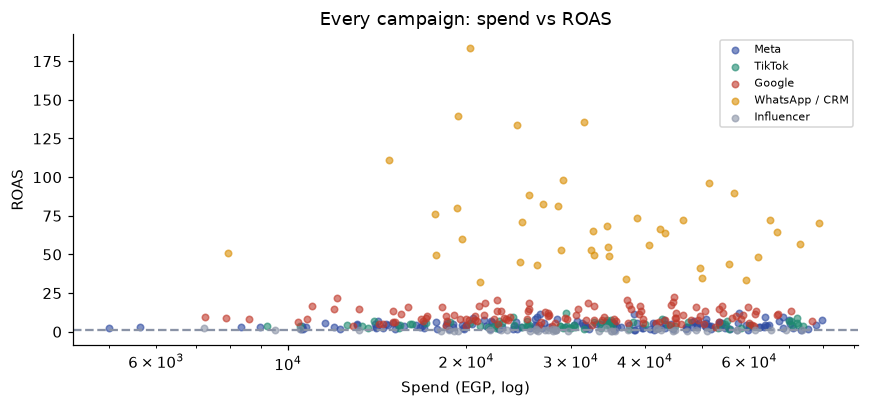

In [ ]:
# 5.4 Campaign outliers
mk['ROAS_z'] = mk.groupby('Platform').ROAS.transform(lambda x: (x - x.mean()) / x.std())
cols = ['Campaign_ID', 'Platform', 'Product_Name', 'Spend_EGP', 'ROAS', 'profit_ROAS', 'CTR_%', 'Conv_%', 'contribution', 'ROAS_z']
print('Top 8 campaigns by contribution:'); display(mk.sort_values('contribution', ascending=False)[cols].head(8).round(2))
print('Bottom 8 campaigns by contribution (candidates to stop):'); display(mk.sort_values('contribution')[cols].head(8).round(2))
fig, ax = plt.subplots(figsize=(8, 3.8))
for p, col in zip(mk.Platform.unique(), [BLUE, GREEN, RED, AMBER, GREY]):
    d = mk[mk.Platform == p]; ax.scatter(d.Spend_EGP, d.ROAS, s=18, alpha=.6, color=col, label=p)
ax.set_xscale('log'); ax.axhline(1, color=GREY, ls='--'); ax.set_xlabel('Spend (EGP, log)'); ax.set_ylabel('ROAS'); ax.legend(fontsize=7); ax.set_title('Every campaign: spend vs ROAS'); plt.tight_layout(); plt.show()

In [57]:
# 5.5 Does discounting buy marketing efficiency?
mk['disc_band'] = pd.cut(mk.Discount_Pct, [-.001, 0, .10, .20, .40], labels=['0%', '1-10%', '11-20%', '21%+'])
db = agg(mk.groupby('disc_band')); display(db[['campaigns', 'spend', 'ROAS', 'profit_ROAS', 'Conv_%', 'contribution']].round(2))
print('Correlation of campaign discount with ROAS:', round(mk.Discount_Pct.corr(mk.ROAS), 2), '| with profit ROAS:', round(mk.Discount_Pct.corr(mk.profit_ROAS), 2))

,campaigns,spend,ROAS,profit_ROAS,Conv_%,contribution
disc_band,,,,,,
0%,71,2699849,11.03,1.74,4.05,1998855.24
1-10%,135,4638060,11.80,2.02,4.03,4749652.26
11-20%,144,5041576,11.30,1.60,4.09,3045136.82
21%+,70,2204491,17.36,3.16,4.64,4765144.05


Correlation of campaign discount with ROAS: 0.05 | with profit ROAS: 0.05


In [ ]:
# 5.6 Budget reallocation scenario
q1, q3 = mk.profit_ROAS.quantile(.25), mk.profit_ROAS.quantile(.75)
low, high = mk[mk.profit_ROAS <= q1], mk[mk.profit_ROAS >= q3]
low_pr, high_pr = low.gross_profit_attr.sum() / low.Spend_EGP.sum(), high.gross_profit_attr.sum() / high.Spend_EGP.sum()
rows = []
for shift in [0.25, 0.50, 1.0]:
    moved = low.Spend_EGP.sum() * shift
    for eff in [0.5, 0.7, 0.9]:
        # gross profit given up from the cut campaigns vs gross profit gained from the scaled campaigns
        delta = moved * (high_pr * eff - low_pr)
        rows.append({'share_of_worst_quartile_spend_moved': f'{shift:.0%}', 'scaling_efficiency_of_best_quartile': f'{eff:.0%}', 'delta_contribution_EGP': round(delta)})
sc = pd.DataFrame(rows).pivot(index='share_of_worst_quartile_spend_moved', columns='scaling_efficiency_of_best_quartile', values='delta_contribution_EGP')
print(f'Worst quartile: {len(low)} campaigns, spend {EG(low.Spend_EGP.sum())}, profit ROAS {low_pr:.2f} | Best quartile: {len(high)} campaigns, profit ROAS {high_pr:.2f}')
display(sc.style.format('{:,.0f}').background_gradient(cmap='RdYlGn', axis=None))

Worst quartile: 105 campaigns, spend 3,740,182 EGP, profit ROAS 0.19 | Best quartile: 105 campaigns, profit ROAS 6.14


scaling_efficiency_of_best_quartile,50%,70%,90%
share_of_worst_quartile_spend_moved,,,
100%,"10,765,057","15,356,738","19,948,418"
25%,"2,691,264","3,839,184","4,987,105"
50%,"5,382,528","7,678,369","9,974,209"


Web orders vs Online invoices (monthly correlation): 0.76 | totals: 47,462 web orders vs 71,559 online invoices
Funnel (daily averages): add-to-cart 10.2% -> checkout 5.1% -> conversion 2.86% | mobile share 80%
Page load vs conversion correlation (daily): -0.16
Attributed revenue = 551% of Online net sales, 290% of ALL direct (Retail + Online) net sales, and 42.7% of total net sales; marketing spend = 3.5% of total net sales.
Monthly spend vs Online net sales correlation: lag0 = -0.14, spend leading by 1 month = 0.02


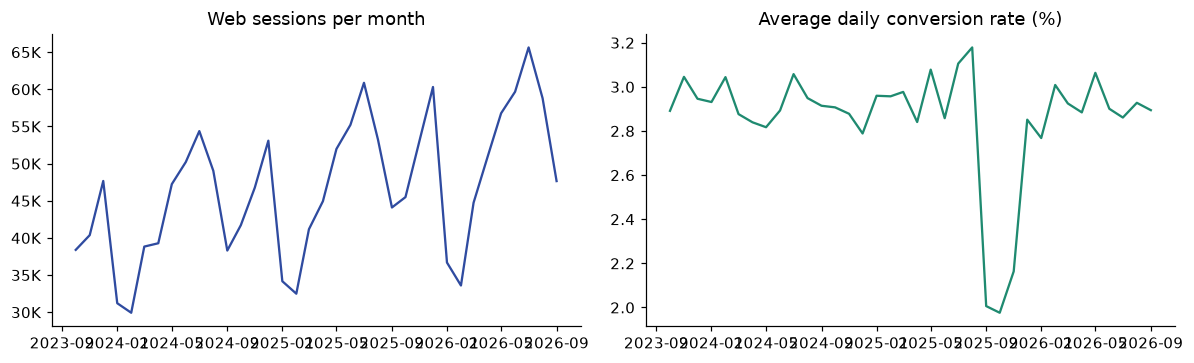

In [59]:
# 5.7 Web funnel and the attribution sanity check
wt = clean['Web_Traffic_Daily'].copy(); wt['Month'] = wt.Date.dt.to_period('M').dt.to_timestamp()
wm = wt.groupby('Month').agg(sessions=('Sessions', 'sum'), orders=('Orders', 'sum'), atc=('Add_To_Cart_Rate', 'mean'), chk=('Checkout_Rate', 'mean'), conv=('Conversion_Rate', 'mean'), load=('Avg_Page_Load_Sec', 'mean'), mobile=('Mobile_Pct', 'mean'))
online_inv = s[s.Channel == 'Online'].groupby('Month').Invoice_ID.nunique()
print(f'Web orders vs Online invoices (monthly correlation): {wm.orders.corr(online_inv):.2f} | totals: {wm.orders.sum():,} web orders vs {online_inv.sum():,} online invoices')
print(f'Funnel (daily averages): add-to-cart {wt.Add_To_Cart_Rate.mean():.1%} -> checkout {wt.Checkout_Rate.mean():.1%} -> conversion {wt.Conversion_Rate.mean():.2%} | mobile share {wt.Mobile_Pct.mean():.0%}')
print(f'Page load vs conversion correlation (daily): {wt.Avg_Page_Load_Sec.corr(wt.Conversion_Rate):.2f}')
ms = mk.groupby('Month').agg(spend=('Spend_EGP', 'sum'), attr=('Attributed_Revenue_EGP', 'sum'))
on_net = s[s.Channel == 'Online'].groupby('Month').Net_Sales_EGP.sum(); tot_net = s.groupby('Month').Net_Sales_EGP.sum()
chk_ = ms.join(on_net.rename('online_net')).join(tot_net.rename('total_net')).dropna()
direct_net = s[s.Channel != 'Wholesale'].groupby('Month').Net_Sales_EGP.sum()
chk_ = chk_.join(direct_net.rename('direct_net'))
print(f'Attributed revenue = {chk_.attr.sum()/chk_.online_net.sum():.0%} of Online net sales, {chk_.attr.sum()/chk_.direct_net.sum():.0%} of ALL direct (Retail + Online) net sales, and {chk_.attr.sum()/chk_.total_net.sum():.1%} of total net sales; marketing spend = {mk.Spend_EGP.sum()/s.Net_Sales_EGP.sum():.1%} of total net sales.')
print(f'Monthly spend vs Online net sales correlation: lag0 = {chk_.spend.corr(chk_.online_net):.2f}, spend leading by 1 month = {chk_.spend.shift(1).corr(chk_.online_net):.2f}')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(wm.index, wm.sessions, color=BLUE); ax[0].yaxis.set_major_formatter(mill); ax[0].set_title('Web sessions per month')
ax[1].plot(wm.index, wm.conv * 100, color=GREEN); ax[1].set_title('Average daily conversion rate (%)')
plt.tight_layout(); plt.show()

In [60]:
# 5.8 KEY TAKEAWAYS (computed)
best_p, worst_p = plat.ROAS.idxmax(), plat.ROAS.idxmin()
mid = sc.loc['50%', '70%']
print(f'1. Efficiency: blended ROAS {mk.Attributed_Revenue_EGP.sum()/mk.Spend_EGP.sum():.2f}x. Best platform by ROAS: {best_p} ({plat.ROAS.max():.2f}x); weakest: {worst_p} ({plat.ROAS.min():.2f}x).')
print(f'2. Profit reality: after product margin, {len(neg)} of {len(mk)} campaigns lose money; total contribution of all marketing = {EG(mk.contribution.sum())} (profit ROAS {mk.gross_profit_attr.sum()/mk.Spend_EGP.sum():.2f}). Platforms below break-even: {", ".join(pv_[pv_.contribution < 0].index) or "none"}.')
print(f'3. Funnel: {mk.Clicks.sum()/mk.Impressions.sum():.2%} CTR, {mk.Orders_Attributed.sum()/mk.Landing_Page_Sessions.sum():.2%} landing-page conversion, cost per attributed order {mk.Spend_EGP.sum()/mk.Orders_Attributed.sum():,.0f} EGP.')
print(f'4. Discounts: correlation between campaign discount and ROAS is {mk.Discount_Pct.corr(mk.ROAS):.2f}.')
print(f'5. Action: moving 50% of the worst-quartile spend to the best quartile (best quartile keeps 70% of its efficiency) changes contribution by {EG(mid)}; the {len(neg)} loss-making campaigns have a combined contribution of {EG(neg.contribution.sum())} (best case, if their attributed revenue were truly incremental).')
print(f'6. Attribution caveat: attributed revenue is {chk_.attr.sum()/chk_.direct_net.sum():.0%} of all direct (Retail + Online) net sales, so platform attribution cannot all be incremental. WhatsApp / CRM (ROAS {plat.loc["WhatsApp / CRM", "ROAS"]:.0f}x) mostly reaches existing customers who may buy anyway: treat the ROAS numbers as upper bounds and validate with a holdout test before shifting budget.')

1. Efficiency: blended ROAS 12.32x. Best platform by ROAS: WhatsApp / CRM (66.96x); weakest: Influencer (1.06x).
2. Profit reality: after product margin, 261 of 420 campaigns lose money; total contribution of all marketing = 14,558,788 EGP (profit ROAS 2.00). Platforms below break-even: Influencer, Meta, TikTok.
3. Funnel: 3.10% CTR, 4.17% landing-page conversion, cost per attributed order 40 EGP.
4. Discounts: correlation between campaign discount and ROAS is 0.05.
5. Action: moving 50% of the worst-quartile spend to the best quartile (best quartile keeps 70% of its efficiency) changes contribution by 7,678,369 EGP; the 261 loss-making campaigns have a combined contribution of -4,756,946 EGP (best case, if their attributed revenue were truly incremental).
6. Attribution caveat: attributed revenue is 290% of all direct (Retail + Online) net sales, so platform attribution cannot all be incremental. WhatsApp / CRM (ROAS 67x) mostly reaches existing customers who may buy anyway: treat the

## Card 06: Factory Production & Bottlenecks
**Question:** Production orders show uneven efficiency and delays across lines and stages. Where is throughput lost before delivery?

**Approach:** order-level KPIs (plan attainment, reject rate, cycle time, delay, overtime) → line scorecard → bottleneck Pareto → drivers of efficiency → capacity utilisation vs the public 5,000 pieces/day → EGP value of lost throughput → prioritised actions.

In [ ]:
# 6.1 Order-level KPIs
pr = clean['Production_Orders'].copy()
pr['Month'] = pr.Start_Date.dt.to_period('M').dt.to_timestamp()
pr['FY'] = fy_label(pr.Start_Date)
pr['family'] = pr.Product_ID.map(fam)
pr['attainment_%'] = pr.Produced_Qty / pr.Planned_Qty * 100
pr['reject_%'] = pr.Rejected_Qty / pr.Produced_Qty * 100
pr['cycle_days'] = (pr.Completion_Date - pr.Start_Date).dt.days + 1
pr['planned_days'] = (pr.Due_Date - pr.Start_Date).dt.days + 1
pr['throughput_per_day'] = pr.Produced_Qty / pr.cycle_days
pr['delayed'] = pr.Delay_Days > 0
pr['shortfall_units'] = np.maximum(0, pr.Planned_Qty - pr.Produced_Qty)
pr['OT_per_1000'] = pr.Overtime_Hours / pr.Produced_Qty * 1000
pr['has_bottleneck'] = pr.Primary_Bottleneck != 'No Bottleneck'
pr = pr.join(unit_econ[['gp_per_unit', 'cogs_per_unit']], on='Product_ID')
# Scale check
UNITS_SOLD = s.Quantity.sum(); UNITS_PRODUCED = pr.Produced_Qty.sum()
SCALE_PROD = min(1.0, UNITS_SOLD / UNITS_PRODUCED)      
print(f'Scale check: production orders produced {UNITS_PRODUCED:,.0f} units vs {UNITS_SOLD:,.0f} units sold in the sales data (x{UNITS_PRODUCED/UNITS_SOLD:.1f}). Production-based EGP values are scaled by {SCALE_PROD:.0%}.')
pr['lost_gp_shortfall'] = pr.shortfall_units * pr.gp_per_unit * SCALE_PROD     
REJECT_LOSS_SHARE = 0.5   
pr['scrap_cost'] = pr.Rejected_Qty * pr.cogs_per_unit * REJECT_LOSS_SHARE * SCALE_PROD
tot = pr[['Planned_Qty', 'Produced_Qty', 'Good_Qty', 'Rejected_Qty']].sum()
print(f'{len(pr):,} orders | planned {tot.Planned_Qty:,.0f} | produced {tot.Produced_Qty:,.0f} ({tot.Produced_Qty/tot.Planned_Qty:.1%} of plan) | good {tot.Good_Qty:,.0f} | rejected {tot.Rejected_Qty:,.0f} ({tot.Rejected_Qty/tot.Produced_Qty:.2%})')
print(f'Delayed orders: {pr.delayed.mean():.1%} | average delay when late: {pr[pr.delayed].Delay_Days.mean():.1f} days | average efficiency: {pr.Efficiency_Pct.mean():.1f}% | orders with a named bottleneck: {pr.has_bottleneck.mean():.1%}')

Scale check: production orders produced 6,267,720 units vs 1,660,589 units sold in the sales data (x3.8). Production-based EGP values are scaled by 26%.
2,500 orders | planned 6,897,476 | produced 6,267,720 (90.9% of plan) | good 6,111,480 | rejected 156,240 (2.49%)
Delayed orders: 16.3% | average delay when late: 5.5 days | average efficiency: 82.2% | orders with a named bottleneck: 16.3%


,orders,produced,attainment_%,reject_%,eff,delay_rate,avg_delay,OT_hours_per_1000_units,thr,lost_value
Line_ID,,,,,,,,,,
LINE-05,483,1203628,90.5,2.5,81.9,17.6,1.0,3.0,160.8,2264778.3
LINE-03,489,1229878,90.7,2.5,82.1,14.7,0.9,2.7,164.5,2164939.4
LINE-01,525,1333223,90.8,2.5,82.2,14.5,0.9,2.6,169.4,2362111.0
LINE-02,501,1234906,90.9,2.5,82.4,14.4,0.7,3.0,161.4,2224884.5
LINE-04,502,1266085,91.5,2.5,82.5,20.3,1.1,2.9,160.8,2121502.7


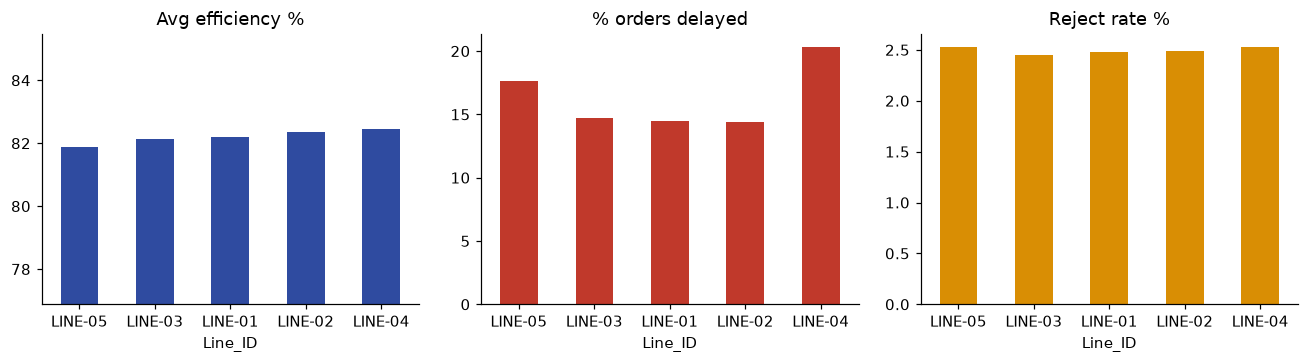

In [62]:
# 6.2 Line scorecard
def line_agg(g):
    r = g.agg(orders=('Production_Order_ID', 'count'), planned=('Planned_Qty', 'sum'), produced=('Produced_Qty', 'sum'), good=('Good_Qty', 'sum'),
              rejected=('Rejected_Qty', 'sum'), eff=('Efficiency_Pct', 'mean'), delay_rate=('delayed', 'mean'), avg_delay=('Delay_Days', 'mean'),
              overtime=('Overtime_Hours', 'sum'), cycle=('cycle_days', 'mean'), thr=('throughput_per_day', 'mean'), lost_gp=('lost_gp_shortfall', 'sum'), scrap=('scrap_cost', 'sum'))
    r['attainment_%'] = r.produced / r.planned * 100; r['reject_%'] = r.rejected / r.produced * 100; r['delay_rate'] *= 100
    r['OT_hours_per_1000_units'] = r.overtime / r.produced * 1000; r['lost_value'] = r.lost_gp + r.scrap
    return r
lines = line_agg(pr.groupby('Line_ID')).sort_values('eff')
display(lines[['orders', 'produced', 'attainment_%', 'reject_%', 'eff', 'delay_rate', 'avg_delay', 'OT_hours_per_1000_units', 'thr', 'lost_value']].round(1))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
lines.eff.plot.bar(ax=ax[0], color=BLUE, rot=0); ax[0].set_title('Avg efficiency %'); ax[0].set_ylim(lines.eff.min() - 5, lines.eff.max() + 3)
lines.delay_rate.plot.bar(ax=ax[1], color=RED, rot=0); ax[1].set_title('% orders delayed')
lines['reject_%'].plot.bar(ax=ax[2], color=AMBER, rot=0); ax[2].set_title('Reject rate %')
plt.tight_layout(); plt.show()

,orders,delay_days,avg_delay,eff,reject_pct,ot_hours,lost_value,cum_delay_share_%
Primary_Bottleneck,,,,,,,,
Sewing,134,945,7.1,73.4,2.6,1875.1,781340.7,42.3
Finishing,109,582,5.3,75.5,2.4,1673.5,406037.6,68.4
Packing,61,264,4.3,81.5,2.5,865.2,221549.8,80.2
Cutting,59,247,4.2,84.4,2.4,845.4,132887.6,91.3
Printing,44,194,4.4,84.4,2.7,614.2,74292.7,100.0


Efficiency: 77.9% with a bottleneck vs 83.0% without | delay rate 100% vs 0%
Orders with a named bottleneck are 16% of orders but carry 100% of all delay days.


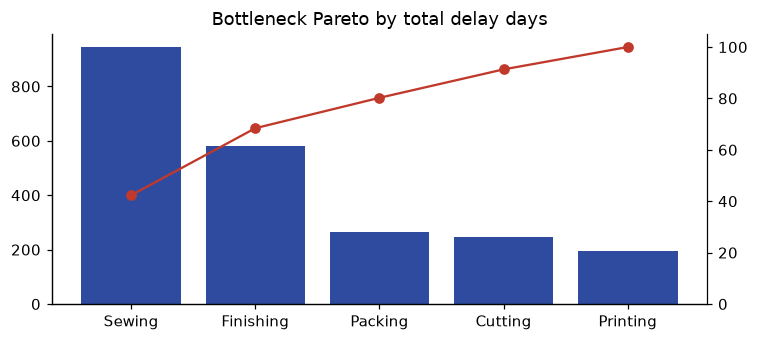

Delay days by line x bottleneck stage:


Primary_Bottleneck,Cutting,Finishing,Packing,Printing,Sewing
Line_ID,,,,,
LINE-01,39,92,42,35,239
LINE-02,58,124,51,6,134
LINE-03,42,102,45,31,202
LINE-04,35,124,61,92,217
LINE-05,73,140,65,30,153


In [ ]:
# 6.3 Bottleneck Pareto
bn = pr[pr.has_bottleneck].groupby('Primary_Bottleneck').agg(orders=('Production_Order_ID', 'count'), delay_days=('Delay_Days', 'sum'), avg_delay=('Delay_Days', 'mean'),
        eff=('Efficiency_Pct', 'mean'), reject_pct=('reject_%', 'mean'), ot_hours=('Overtime_Hours', 'sum'), lost_value=('lost_gp_shortfall', 'sum')).sort_values('delay_days', ascending=False)
bn['cum_delay_share_%'] = bn.delay_days.cumsum() / bn.delay_days.sum() * 100
display(bn.round(1))
base = pr[~pr.has_bottleneck]
print(f'Efficiency: {pr[pr.has_bottleneck].Efficiency_Pct.mean():.1f}% with a bottleneck vs {base.Efficiency_Pct.mean():.1f}% without | delay rate {pr[pr.has_bottleneck].delayed.mean():.0%} vs {base.delayed.mean():.0%}')
share_delay = pr[pr.has_bottleneck].Delay_Days.sum() / pr.Delay_Days.sum()
print(f'Orders with a named bottleneck are {pr.has_bottleneck.mean():.0%} of orders but carry {share_delay:.0%} of all delay days.')
fig, ax = plt.subplots(figsize=(7, 3.2)); ax.bar(bn.index, bn.delay_days, color=BLUE); a2 = ax.twinx(); a2.plot(bn.index, bn['cum_delay_share_%'], color=RED, marker='o'); a2.set_ylim(0, 105); a2.spines['right'].set_visible(True)
ax.set_title('Bottleneck Pareto by total delay days'); plt.tight_layout(); plt.show()
bl = pr[pr.has_bottleneck].pivot_table(index='Line_ID', columns='Primary_Bottleneck', values='Delay_Days', aggfunc='sum').fillna(0)
print('Delay days by line x bottleneck stage:'); display(bl.astype(int))

Correlation with efficiency:


,corr
Overtime_Hours,-0.15
OT_per_1000,-0.12
Planned_Qty,-0.03
Delay_Days,-0.28
reject_%,-0.01
attainment_%,0.93
cycle_days,-0.13


,orders,eff,delay_rate,reject,ot_per_1000
size_band,,,,,
Q1 small,625,83.04,0.14,2.53,9.54
Q2,625,81.50,0.15,2.45,3.88
Q3,625,82.22,0.18,2.51,2.40
Q4 large,625,82.08,0.18,2.49,1.85


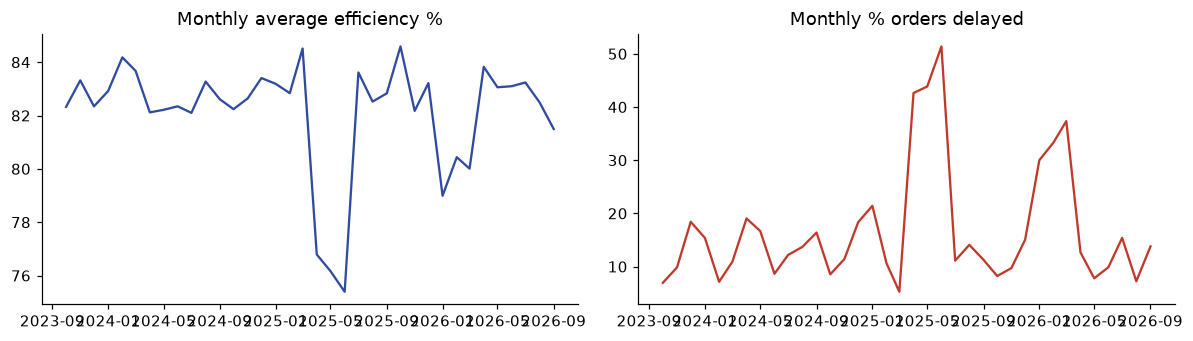

In [ ]:
# 6.4 Correlations and size effects
drv = pr[['Efficiency_Pct', 'Overtime_Hours', 'OT_per_1000', 'Planned_Qty', 'Delay_Days', 'reject_%', 'attainment_%', 'cycle_days']].corr().loc['Efficiency_Pct'].drop('Efficiency_Pct')
print('Correlation with efficiency:'); display(drv.round(2).to_frame('corr'))
pr['size_band'] = pd.qcut(pr.Planned_Qty, 4, labels=['Q1 small', 'Q2', 'Q3', 'Q4 large'])
display(pr.groupby('size_band').agg(orders=('Production_Order_ID', 'count'), eff=('Efficiency_Pct', 'mean'), delay_rate=('delayed', 'mean'), reject=('reject_%', 'mean'), ot_per_1000=('OT_per_1000', 'mean')).round(2))
m6 = pr.groupby('Month').agg(eff=('Efficiency_Pct', 'mean'), delay_rate=('delayed', 'mean'), reject=('reject_%', 'mean'), produced=('Produced_Qty', 'sum'))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2)); ax[0].plot(m6.index, m6.eff, color=BLUE); ax[0].set_title('Monthly average efficiency %')
ax[1].plot(m6.index, m6.delay_rate * 100, color=RED); ax[1].set_title('Monthly % orders delayed'); plt.tight_layout(); plt.show()

In [ ]:
# 6.5 Capacity utilisation
CAP_DAY = 5000   # 'Up to 5,000 pieces/day' (LEO Production Hub, Business_Units.csv)
days = np.repeat(pr.index.values, pr.cycle_days.clip(lower=1).values)
per_day = (pr.Produced_Qty / pr.cycle_days.clip(lower=1)).reindex(days).values
start = pr.Start_Date.reindex(days).values; offs = np.concatenate([np.arange(c) for c in pr.cycle_days.clip(lower=1).values])
daily = pd.Series(per_day, index=pd.to_datetime(start) + pd.to_timedelta(offs, unit='D')).groupby(level=0).sum()
cal = pd.date_range('2023-10-01', '2026-09-30'); daily = daily.reindex(cal, fill_value=0)
util = daily.groupby(daily.index.to_period('M')).mean() / CAP_DAY * 100
print(f'Average modelled output = {daily.mean():,.0f} pieces/day = {daily.mean()/CAP_DAY:.1%} of the public {CAP_DAY:,}/day capacity (peak month {util.max():.1f}%). Production orders cover only part of the factory (indicative utilisation).')
print(f'Share of calendar days with zero production: {(daily == 0).mean():.0%}')
# Machine downtime in production areas as a second view of lost capacity
dt = clean['Machine_Downtime']; prod_dt = dt[dt.Business_Area != 'Printing']
print('Downtime hours by production area (excluding printing, see Card 08):'); display(prod_dt.groupby('Business_Area').agg(events=('Downtime_ID', 'count'), hours=('Downtime_Hours', 'sum'), unplanned_hours=('Downtime_Hours', lambda x: x[prod_dt.loc[x.index, 'Planned'] == 'No'].sum())).round(0))

Average modelled output = 5,719 pieces/day = 114.4% of the public 5,000/day capacity (peak month 158.4%). Production orders cover only part of the factory (indicative utilisation).
Share of calendar days with zero production: 0%
Downtime hours by production area (excluding printing, see Card 08):


,events,hours,unplanned_hours
Business_Area,,,
Cutting,453,1040.0,851.0
Finishing,234,515.0,398.0
Packing,235,446.0,349.0
Sewing,685,1495.0,1220.0


In [66]:
# 6.6 Value of lost throughput and prioritised actions
loss = pd.DataFrame({'lost_gp_from_shortfall': [pr.lost_gp_shortfall.sum()], 'scrap_cost_of_rejects': [pr.scrap_cost.sum()], 'overtime_hours': [pr.Overtime_Hours.sum()]})
display(loss.round(0))
act = lines[['eff', 'delay_rate', 'reject_%', 'lost_value']].copy()
for c, asc in [('eff', True), ('delay_rate', False), ('reject_%', False), ('lost_value', False)]: act['r_' + c] = act[c].rank(ascending=asc)
act['priority_score'] = act[[c for c in act.columns if c.startswith('r_')]].mean(axis=1)
act = act.sort_values('priority_score'); act['worst_bottleneck'] = [bl.loc[l].idxmax() if l in bl.index else '-' for l in act.index]
display(act[['eff', 'delay_rate', 'reject_%', 'lost_value', 'worst_bottleneck', 'priority_score']].round(1))

,lost_gp_from_shortfall,scrap_cost_of_rejects,overtime_hours
0,6666596.0,4471620.0,17626.0


,eff,delay_rate,reject_%,lost_value,worst_bottleneck,priority_score
Line_ID,,,,,,
LINE-05,81.9,17.6,2.5,2264778.3,Sewing,1.5
LINE-01,82.2,14.5,2.5,2362111.0,Sewing,3.0
LINE-04,82.5,20.3,2.5,2121502.7,Sewing,3.2
LINE-03,82.1,14.7,2.5,2164939.4,Sewing,3.5
LINE-02,82.4,14.4,2.5,2224884.5,Sewing,3.8


In [ ]:
# 6.7 KEY TAKEAWAYS (computed)
worst, best = lines.eff.idxmin(), lines.eff.idxmax(); gap = lines.eff.max() - lines.eff.min()
if gap < 2:
    print(f'1. Lines are almost identical: efficiency only {gap:.1f} points apart ({lines.eff.min():.1f}% to {lines.eff.max():.1f}%). The lever is NOT which line runs the order. Delay rate does differ: {lines.delay_rate.idxmax()} {lines.delay_rate.max():.0f}% vs {lines.delay_rate.idxmin()} {lines.delay_rate.min():.0f}%.')
else:
    print(f'1. Line gap: {best} runs at {lines.eff.max():.1f}% efficiency vs {worst} at {lines.eff.min():.1f}% ({gap:.1f} points apart).')
print(f'2. Plan vs actual: factory delivers {tot.Produced_Qty/tot.Planned_Qty:.1%} of planned units; {pr.delayed.mean():.0%} of orders finish late (average {pr[pr.delayed].Delay_Days.mean():.1f} days).')
topb = bn.index[0]
print(f'3. Bottleneck is the real driver: every delayed order has a named bottleneck. {topb} is #1 ({bn.delay_days.iloc[0]:.0f} delay days = {bn.delay_days.iloc[0]/bn.delay_days.sum():.0%}), then {bn.index[1]} ({bn.delay_days.iloc[1]/bn.delay_days.sum():.0%}); together {bn.cum_delay_share_pct.iloc[1] if False else bn["cum_delay_share_%"].iloc[1]:.0f}% of delay. Efficiency drops to {pr[pr.has_bottleneck].Efficiency_Pct.mean():.1f}% on bottleneck orders vs {base.Efficiency_Pct.mean():.1f}%.')
print(f'4. Quality loss in production: {tot.Rejected_Qty:,.0f} rejected units; at an assumed {REJECT_LOSS_SHARE:.0%} loss of unit cost and scaled to sales volume ({SCALE_PROD:.0%}) = {EG(pr.scrap_cost.sum())}. Plan shortfall forgoes {EG(pr.lost_gp_shortfall.sum())} gross profit (same scaling).')
print(f'5. Capacity: modelled output averages {daily.mean():,.0f} pieces/day = {daily.mean()/CAP_DAY:.0%} of the public {CAP_DAY:,}/day figure with {pr.Overtime_Hours.sum():,.0f} overtime hours: the factory runs at or above its stated capacity, so Sewing/Finishing relief (not more volume) is the priority. Sewing + Finishing downtime = {prod_dt[prod_dt.Business_Area.isin(["Sewing", "Finishing"])].Downtime_Hours.sum():,.0f} hours.')
print(f'6. Action: attack {bn.index[0]} and {bn.index[1]} first on every line (largest delay-days by line: ' + ', '.join(f'{l} {bl.loc[l].idxmax()}' for l in bl.index) + f'); overtime does not buy efficiency (correlation {pr.Efficiency_Pct.corr(pr.Overtime_Hours):.2f}).')

1. Lines are almost identical: efficiency only 0.6 points apart (81.9% to 82.5%). The lever is NOT which line runs the order. Delay rate does differ: LINE-04 20% vs LINE-02 14%.
2. Plan vs actual: factory delivers 90.9% of planned units; 16% of orders finish late (average 5.5 days).
3. Bottleneck is the real driver: every delayed order has a named bottleneck. Sewing is #1 (945 delay days = 42%), then Finishing (26%); together 68% of delay. Efficiency drops to 77.9% on bottleneck orders vs 83.0%.
4. Quality loss in production: 156,240 rejected units; at an assumed 50% loss of unit cost and scaled to sales volume (26%) = 4,471,620 EGP. Plan shortfall forgoes 6,666,596 EGP gross profit (same scaling).
5. Capacity: modelled output averages 5,719 pieces/day = 114% of the public 5,000/day figure with 17,626 overtime hours: the factory runs at or above its stated capacity, so Sewing/Finishing relief (not more volume) is the priority. Sewing + Finishing downtime = 2,009 hours.
6. Action: attac

## Card 07: Quality, Returns & Cost of Poor Quality (COPQ)
**Question:** Customer returns and QC defects are analysed separately, so root causes are hard to prioritise.

**Approach:** QC reject rates by stage → defect and root-cause Pareto → customer returns by reason → **link QC and returns at product level** → total COPQ in EGP → corrective-action priorities.

In [68]:
# 7.1 QC overview by stage
qc = clean['Quality'].copy()
qc['Month'] = qc.Inspection_Date.dt.to_period('M').dt.to_timestamp(); qc['family'] = qc.Product_ID.map(fam)
qc['has_defect'] = qc.Defect_Type != 'No Defect'
stage_order = ['Fabric', 'Cutting', 'Sewing', 'Printing', 'Finishing', 'Final']
st = qc.groupby('Stage').agg(inspections=('QC_ID', 'count'), inspected=('Inspected_Qty', 'sum'), rejected=('Rejected_Qty', 'sum'), loss=('Estimated_Loss_EGP', 'sum'), defect_events=('has_defect', 'sum')).reindex(stage_order)
st['reject_rate_%'] = st.rejected / st.inspected * 100; st['loss_per_inspection'] = st.loss / st.inspections; st['loss_share_%'] = st.loss / st.loss.sum() * 100
display(st.round(2))
print(f'Overall QC reject rate: {qc.Rejected_Qty.sum()/qc.Inspected_Qty.sum():.2%} | total estimated loss: {EG(qc.Estimated_Loss_EGP.sum())} | inspections with a defect: {qc.has_defect.mean():.0%}')

,inspections,inspected,rejected,loss,defect_events,reject_rate_%,loss_per_inspection,loss_share_%
Stage,,,,,,,,
Fabric,1501,625790,14880,2695718.12,1176,2.38,1795.95,16.51
Cutting,1532,635851,15365,2810109.57,1196,2.42,1834.28,17.22
Sewing,1472,625472,14864,2699704.48,1137,2.38,1834.04,16.54
Printing,1454,597182,14647,2660944.06,1143,2.45,1830.09,16.30
Finishing,1510,626258,15229,2791198.60,1181,2.43,1848.48,17.10
Final,1531,622825,14839,2665239.30,1195,2.38,1740.85,16.33


Overall QC reject rate: 2.41% | total estimated loss: 16,322,914 EGP | inspections with a defect: 78%


,events,rejected,loss,cum_%
Defect_Type,,,,
Size Variance,944,10850,1973449.8,13.8
Stitch Defect,908,10726,1958578.0,27.5
Packing Error,881,9785,1764936.4,39.9
Finishing Defect,848,9572,1757454.9,52.2
Fabric Defect,865,9695,1753644.8,64.4
Print Cracking,859,9195,1715102.2,76.4
Color Misalignment,865,9541,1705874.8,88.4
Ink Smudge,858,9252,1664975.2,100.0


,events,rejected,loss,cum_%
Root_Cause,,,,
Curing temperature,929,10480,1917893.4,13.4
Process variation,906,10255,1901571.3,26.7
Handling / packing,903,10022,1834519.6,39.6
Operator method,866,9888,1782661.9,52.0
Machine calibration,870,9877,1781071.0,64.5
Pattern / measurement,874,9744,1772558.5,76.9
No significant issue,829,9298,1685422.3,88.7
Material variation,851,9052,1618318.2,100.0


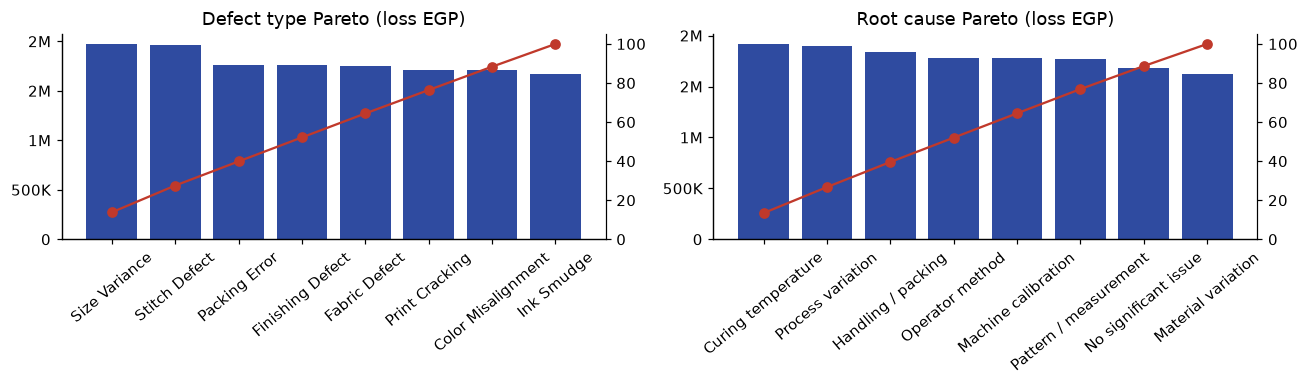

Loss by stage x defect type (EGP):


Defect_Type,Color Misalignment,Fabric Defect,Finishing Defect,Ink Smudge,Packing Error,Print Cracking,Size Variance,Stitch Defect
Stage,,,,,,,,
Fabric,291471,334106,284649,236585,269075,313782,315257,330128
Cutting,301610,317170,312686,305938,264725,289696,338100,329046
Sewing,250957,277636,294386,246317,314288,253959,379152,330012
Printing,266303,282640,279864,292722,335506,260104,316324,296635
Finishing,311414,250257,311541,295954,317280,305542,334699,340319
Final,284120,291836,274329,287460,264062,292020,289917,332438


In [69]:
# 7.2 Defect Pareto and root-cause Pareto (loss in EGP, defects only)
d = qc[qc.has_defect]
dp = d.groupby('Defect_Type').agg(events=('QC_ID', 'count'), rejected=('Rejected_Qty', 'sum'), loss=('Estimated_Loss_EGP', 'sum')).sort_values('loss', ascending=False)
dp['cum_%'] = dp.loss.cumsum() / dp.loss.sum() * 100
rc_ = d.groupby('Root_Cause').agg(events=('QC_ID', 'count'), rejected=('Rejected_Qty', 'sum'), loss=('Estimated_Loss_EGP', 'sum')).sort_values('loss', ascending=False)
rc_['cum_%'] = rc_.loss.cumsum() / rc_.loss.sum() * 100
display(dp.round(1)); display(rc_.round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, tbl, ttl in [(ax[0], dp, 'Defect type Pareto (loss EGP)'), (ax[1], rc_, 'Root cause Pareto (loss EGP)')]:
    a.bar(tbl.index, tbl.loss, color=BLUE); a.yaxis.set_major_formatter(mill); a.tick_params(axis='x', rotation=40); a2 = a.twinx(); a2.plot(tbl.index, tbl['cum_%'], color=RED, marker='o'); a2.set_ylim(0, 105); a2.spines['right'].set_visible(True); a.set_title(ttl)
plt.tight_layout(); plt.show()
hm = d.pivot_table(index='Stage', columns='Defect_Type', values='Estimated_Loss_EGP', aggfunc='sum').reindex(stage_order).fillna(0)
print('Loss by stage x defect type (EGP):'); display(hm.round(0).astype(int))

,lines,refund,quality_related,refund_share_%,quality_related_%
Return_Reason,,,,,
Size / fit,3050,3512591.5,0,37.3,0.0
Fabric / stitching,1405,1509735.2,1405,16.0,100.0
Changed mind,1343,1471459.4,0,15.6,0.0
Color / appearance,1016,1079630.8,0,11.5,0.0
Print issue,1052,1000164.0,1052,10.6,100.0
Delivery issue,677,853424.6,0,9.1,0.0


Returned lines: 8,543 (4.7% of all lines) | refund value: 9,427,006 EGP (2.2% of net sales) | quality-related returns: 2,457 lines, 2,509,899 EGP


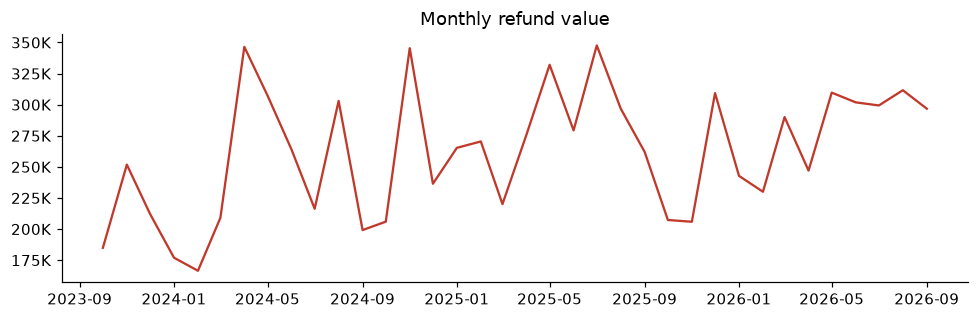

In [ ]:
# 7.3 Customer returns
rt = s[s.Is_Returned == 1].copy()
rr_ = rt.groupby('Return_Reason').agg(lines=('Row_ID', 'count'), refund=('Refund_Value_EGP', 'sum'), quality_related=('Is_Quality_Return', 'sum')).sort_values('refund', ascending=False)
rr_['refund_share_%'] = rr_.refund / rr_.refund.sum() * 100; rr_['quality_related_%'] = rr_.quality_related / rr_.lines * 100
display(rr_.round(1))
print(f'Returned lines: {len(rt):,} ({len(rt)/len(s):.1%} of all lines) | refund value: {EG(rt.Refund_Value_EGP.sum())} ({rt.Refund_Value_EGP.sum()/s.Net_Sales_EGP.sum():.1%} of net sales) | quality-related returns: {int(rt.Is_Quality_Return.sum()):,} lines, {EG(rt[rt.Is_Quality_Return == 1].Refund_Value_EGP.sum())}')
mr = rt.groupby(rt.Return_Date.dt.to_period('M').dt.to_timestamp()).agg(refund=('Refund_Value_EGP', 'sum'))
fig, ax = plt.subplots(figsize=(9, 3)); ax.plot(mr.index, mr.refund, color=RED); ax.yaxis.set_major_formatter(mill); ax.set_title('Monthly refund value'); plt.tight_layout(); plt.show()

,qc_reject_rate,defect_events,return_rate_%,quality_return_rate_%,print_reject_%
qc_reject_rate,1.00,-0.05,0.28,0.13,-0.10
defect_events,-0.05,1.00,-0.04,-0.16,0.09
return_rate_%,0.28,-0.04,1.00,0.57,-0.36
quality_return_rate_%,0.13,-0.16,0.57,1.00,-0.17
print_reject_%,-0.10,0.09,-0.36,-0.17,1.00


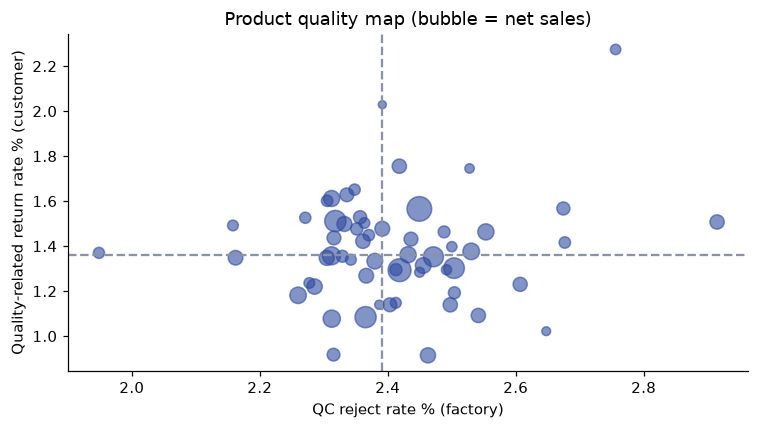

Product-level correlation between factory QC reject rate and customer quality-return rate: 0.13


In [71]:
# 7.4 Connect quality to returns at product level
prod_q = qc.groupby('Product_ID').agg(qc_reject_rate=('Rejected_Qty', 'sum'), inspected=('Inspected_Qty', 'sum'), qc_loss=('Estimated_Loss_EGP', 'sum'), defect_events=('has_defect', 'sum'))
prod_q['qc_reject_rate'] = prod_q.qc_reject_rate / prod_q.inspected * 100
prod_r = s.groupby('Product_ID').agg(lines=('Row_ID', 'count'), net=('Net_Sales_EGP', 'sum'), returned=('Is_Returned', 'sum'), q_returned=('Is_Quality_Return', 'sum'), refund=('Refund_Value_EGP', 'sum'))
prod_r['return_rate_%'] = prod_r.returned / prod_r.lines * 100; prod_r['quality_return_rate_%'] = prod_r.q_returned / prod_r.lines * 100
prp = clean['Printing_Batches'].groupby('Product_ID').agg(print_rework=('Rework_Cost_EGP', 'sum'), print_reject=('Rejected_Qty', 'sum'), printed=('Printed_Qty', 'sum'))
prp['print_reject_%'] = prp.print_reject / prp.printed * 100
pq = prod_q.join(prod_r).join(prp).join(pm[['Product_Name', 'Product_Family']])
cm = pq[['qc_reject_rate', 'defect_events', 'return_rate_%', 'quality_return_rate_%', 'print_reject_%']].corr().round(2)
display(cm)
x, y = pq.qc_reject_rate, pq['quality_return_rate_%']
fig, ax = plt.subplots(figsize=(7, 4)); ax.scatter(x, y, s=pq.net / pq.net.max() * 250 + 10, alpha=.6, color=BLUE)
ax.axvline(x.median(), color=GREY, ls='--'); ax.axhline(y.median(), color=GREY, ls='--'); ax.set_xlabel('QC reject rate % (factory)'); ax.set_ylabel('Quality-related return rate % (customer)')
ax.set_title('Product quality map (bubble = net sales)'); plt.tight_layout(); plt.show()
print(f'Product-level correlation between factory QC reject rate and customer quality-return rate: {x.corr(y):.2f}')

In [72]:
# 7.5 Match return reasons to the factory stage that should have caught them (assumed mapping, stated explicitly)
MAP = {'Fabric / stitching': ['Fabric', 'Sewing'], 'Print issue': ['Printing'], 'Color / appearance': ['Printing', 'Fabric'], 'Size / fit': ['Cutting', 'Final']}
rows = []
for reason, stages in MAP.items():
    rows.append({'return_reason': reason, 'refund_EGP': rr_.loc[reason, 'refund'], 'quality_related_%': rr_.loc[reason, 'quality_related_%'],
                 'matching_QC_stages': ' + '.join(stages), 'QC_loss_EGP_in_those_stages': st.loc[stages, 'loss'].sum(), 'QC_reject_rate_%_in_those_stages': st.loc[stages, 'rejected'].sum() / st.loc[stages, 'inspected'].sum() * 100})
display(pd.DataFrame(rows).round(1))
print('Reading: a return reason with high refund value and a low QC reject rate in its matching stage means inspection is not catching the problem before shipment.')

,return_reason,refund_EGP,quality_related_%,matching_QC_stages,QC_loss_EGP_in_those_stages,QC_reject_rate_%_in_those_stages
0,Fabric / stitching,1509735.2,100.0,Fabric + Sewing,5395422.6,2.4
1,Print issue,1000164.0,100.0,Printing,2660944.1,2.5
2,Color / appearance,1079630.8,0.0,Printing + Fabric,5356662.2,2.4
3,Size / fit,3512591.5,0.0,Cutting + Final,5475348.9,2.4


Reading: a return reason with high refund value and a low QC reject rate in its matching stage means inspection is not catching the problem before shipment.


,EGP,share_%
QC estimated loss (internal),16322914.1,67.7
"Production rejects (50% cost loss, scaled 26%) (internal)",4471619.5,18.6
Printing rework + reprint (internal),795587.6,3.3
Refunds on quality-related returns (external),2509899.2,10.4


Total COPQ = 24,100,021 EGP = 5.7% of net sales and 37.1% of gross profit (components may overlap, so read as an upper bound).
Sensitivity of total COPQ to the share of rejected-unit cost that is really lost:


,0%,25%,50%,75%,100%
Total COPQ (EGP),19628401.0,21864211.0,24100021.0,26335830.0,28571640.0


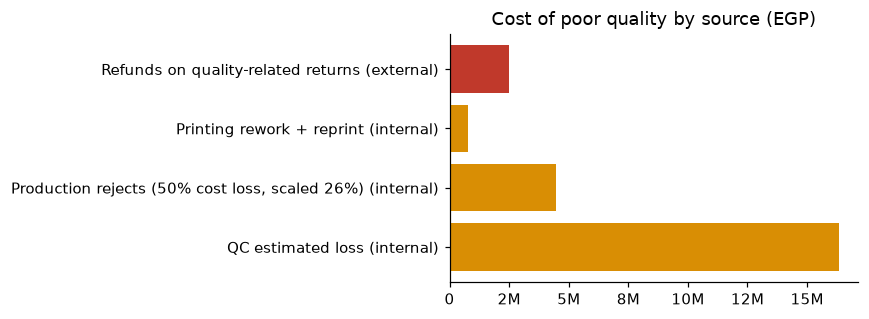

In [ ]:
# 7.6 Cost of Poor Quality
pr_cost = pr.scrap_cost.sum()     # uses REJECT_LOSS_SHARE set in Card 06
prt = clean['Printing_Batches']
copq = pd.Series({
    'QC estimated loss (internal)': qc.Estimated_Loss_EGP.sum(),
    f'Production rejects ({REJECT_LOSS_SHARE:.0%} cost loss, scaled {SCALE_PROD:.0%}) (internal)': pr_cost,
    'Printing rework + reprint (internal)': prt.Rework_Cost_EGP.sum(),
    'Refunds on quality-related returns (external)': rt[rt.Is_Quality_Return == 1].Refund_Value_EGP.sum(),
})
c = copq.to_frame('EGP'); c['share_%'] = c.EGP / c.EGP.sum() * 100; display(c.round(1)); print(f'Total COPQ = {EG(copq.sum())} = {copq.sum()/s.Net_Sales_EGP.sum():.1%} of net sales and {copq.sum()/s.Gross_Profit_EGP.sum():.1%} of gross profit (components may overlap, so read as an upper bound).')
sens = pd.DataFrame({f'{sh:.0%}': [(copq.sum() - pr_cost) + pr.Rejected_Qty.mul(pr.cogs_per_unit).sum() * SCALE_PROD * sh] for sh in [0, .25, .5, .75, 1]}, index=['Total COPQ (EGP)'])
print('Sensitivity of total COPQ to the share of rejected-unit cost that is really lost:'); display(sens.round(0))
fig, ax = plt.subplots(figsize=(8, 3)); ax.barh(copq.index, copq.values, color=[AMBER, AMBER, AMBER, RED]); ax.xaxis.set_major_formatter(mill); ax.set_title('Cost of poor quality by source (EGP)'); plt.tight_layout(); plt.show()

In [ ]:
# 7.7 Corrective-action priorities
pq['copq'] = pq.qc_loss.fillna(0) + pq.print_rework.fillna(0) + (s[s.Is_Quality_Return == 1].groupby('Product_ID').Refund_Value_EGP.sum()).reindex(pq.index).fillna(0)
pq['copq_%_of_sales'] = pq.copq / pq.net * 100
top = pq.sort_values('copq', ascending=False).head(10)[['Product_Name', 'Product_Family', 'net', 'qc_reject_rate', 'print_reject_%', 'quality_return_rate_%', 'copq', 'copq_%_of_sales']]
display(top.round(1))
top.to_csv(os.path.join(OUT_DIR, 'quality_priority_products.csv'))
print(f'Top 10 products carry {pq.sort_values("copq", ascending=False).head(10).copq.sum()/pq.copq.sum():.0%} of product-level quality cost.')

,Product_Name,Product_Family,net,qc_reject_rate,print_reject_%,quality_return_rate_%,copq,copq_%_of_sales
Product_ID,,,,,,,,
P037,Girls' sweatshirt-Flower,Sweatshirts,22791251.9,2.4,2.5,1.6,1038182.7,4.6
P033,Boys' sweatshirt-LEO,Sweatshirts,16587409.1,2.4,2.3,1.1,821524.1,5.0
P032,Boys' sweatshirt-blue,Sweatshirts,14626403.1,2.5,2.4,1.4,807420.9,5.5
P051,Ice cream - بيجامة حريمي صيفي2024,Pajamas/Homewear,19595749.9,2.4,2.8,1.3,806475.8,4.1
P008,Summer children's boys-SpongeBob,Pajamas/Homewear,15606338.4,2.5,2.4,1.3,731895.4,4.7
P001,Summer children's girls-Happy,Pajamas/Homewear,16774261.2,2.3,2.5,1.5,691740.5,4.1
P059,Positive vibes - 2024بيجامة حريمي صيفي,Pajamas/Homewear,11779226.0,2.3,3.1,1.4,517436.0,4.4
P005,Summer children's boys-Black and orange,Pajamas/Homewear,9295939.6,2.6,2.8,1.5,486198.3,5.2
P029,Girls' pajamas-Daylife+kuromi,Pajamas/Homewear,9810823.8,2.5,3.0,1.4,461822.3,4.7


Top 10 products carry 35% of product-level quality cost.


In [ ]:
# 7.8 KEY TAKEAWAYS (computed)
spread = st['reject_rate_%'].max() - st['reject_rate_%'].min(); n80d = int((dp['cum_%'] <= 80).sum()) + 1
norc = d[d.Root_Cause == 'No significant issue']
size_refund = rr_.loc['Size / fit', 'refund']
print(f'1. Stages: QC reject rate is {st["reject_rate_%"].min():.2f}% to {st["reject_rate_%"].max():.2f}% across stages (only {spread:.2f} points apart), so no single stage is the culprit. Overall reject rate {qc.Rejected_Qty.sum()/qc.Inspected_Qty.sum():.2%}; QC loss {EG(qc.Estimated_Loss_EGP.sum())}.')
print(f'2. Defects are systemic, not concentrated: {n80d} of {len(dp)} defect types are needed to reach 80% of loss (largest, {dp.index[0]}, is only {dp.loss.iloc[0]/dp.loss.sum():.0%}). Largest root cause: {rc_.index[0]} ({rc_.loss.iloc[0]/rc_.loss.sum():.0%}). Data gap: {len(norc)/len(d):.0%} of defect events ({EG(norc.Estimated_Loss_EGP.sum())}) have the root cause "No significant issue", so root-cause logging needs fixing.')
print(f'3. Returns: {len(rt)/len(s):.1%} of lines are returned ({EG(rt.Refund_Value_EGP.sum())}). Top reason is {rr_.index[0]} ({rr_["refund_share_%"].iloc[0]:.0f}% of refunds, {EG(size_refund)}), which is NOT flagged quality-related: it is a sizing / pattern problem that factory QC cannot catch. Quality-related returns (fabric/stitching, print) cost {EG(rt[rt.Is_Quality_Return == 1].Refund_Value_EGP.sum())}.')
print(f'4. Link: product-level correlation between factory QC reject rate and customer quality-return rate is {x.corr(y):.2f}. {"QC is a useful early warning." if abs(x.corr(y)) >= 0.4 else "QC reject rate does not predict which products customers return, so inspection criteria should be reviewed against what customers actually complain about."}')
print(f'5. COPQ = {EG(copq.sum())} ({copq.sum()/s.Net_Sales_EGP.sum():.1%} of net sales) under the stated {REJECT_LOSS_SHARE:.0%} reject-loss assumption; largest component: {copq.idxmax()} ({copq.max()/copq.sum():.0%}).')
print(f'6. Action: (a) review size charts and pattern grading ({EG(size_refund)} of refunds); (b) standardise process control (curing temperature, process variation) because defects are spread evenly; (c) start with the 10 products that carry {pq.sort_values("copq", ascending=False).head(10).copq.sum()/pq.copq.sum():.0%} of product quality cost.')

1. Stages: QC reject rate is 2.38% to 2.45% across stages (only 0.08 points apart), so no single stage is the culprit. Overall reject rate 2.41%; QC loss 16,322,914 EGP.
2. Defects are systemic, not concentrated: 7 of 8 defect types are needed to reach 80% of loss (largest, Size Variance, is only 14%). Largest root cause: Curing temperature (13%). Data gap: 12% of defect events (1,685,422 EGP) have the root cause "No significant issue", so root-cause logging needs fixing.
3. Returns: 4.7% of lines are returned (9,427,006 EGP). Top reason is Size / fit (37% of refunds, 3,512,592 EGP), which is NOT flagged quality-related: it is a sizing / pattern problem that factory QC cannot catch. Quality-related returns (fabric/stitching, print) cost 2,509,899 EGP.
4. Link: product-level correlation between factory QC reject rate and customer quality-return rate is 0.13. QC reject rate does not predict which products customers return, so inspection criteria should be reviewed against what customers 

## Card 08: Printing Performance & Downtime
**Question:** Printing yield and rework vary by machine and period, and downtime events cut output.

**Approach:** machine yield, defect and reprint rates → cost per good unit → print-type and period views → downtime hours and reasons → combine into a **maintenance priority score** per machine.

In [76]:
# 8.1 Machine scorecard
pb = clean['Printing_Batches'].copy()
pb['Month'] = pb.Print_Date.dt.to_period('M').dt.to_timestamp(); pb['has_defect'] = pb.Defect_Type != 'No Defect'
def pagg(g):
    r = g.agg(batches=('Print_Batch_ID', 'count'), planned=('Planned_Qty', 'sum'), printed=('Printed_Qty', 'sum'), good=('Good_Qty', 'sum'), rejected=('Rejected_Qty', 'sum'),
              reprint=('Reprint_Qty', 'sum'), consumable=('Ink_or_Consumable_Cost_EGP', 'sum'), rework=('Rework_Cost_EGP', 'sum'), defect_batches=('has_defect', 'mean'))
    r['yield_%'] = r.good / r.printed * 100; r['reject_%'] = r.rejected / r.printed * 100; r['reprint_%'] = r.reprint / r.printed * 100
    r['plan_attainment_%'] = r.printed / r.planned * 100; r['cost_per_good_unit'] = (r.consumable + r.rework) / r.good; r['rework_%_of_cost'] = r.rework / (r.consumable + r.rework) * 100
    r['defect_batches'] *= 100; return r
mach = pagg(pb.groupby('Machine_ID'))
display(mach[['batches', 'printed', 'yield_%', 'reject_%', 'reprint_%', 'plan_attainment_%', 'defect_batches', 'cost_per_good_unit', 'rework', 'rework_%_of_cost']].round(2))
print(f'Overall: yield {pb.Good_Qty.sum()/pb.Printed_Qty.sum():.2%} | reject {pb.Rejected_Qty.sum()/pb.Printed_Qty.sum():.2%} | reprint {pb.Reprint_Qty.sum()/pb.Printed_Qty.sum():.2%} | rework cost {EG(pb.Rework_Cost_EGP.sum())} | consumables {EG(pb.Ink_or_Consumable_Cost_EGP.sum())}')

,batches,printed,yield_%,reject_%,reprint_%,plan_attainment_%,defect_batches,cost_per_good_unit,rework,rework_%_of_cost
Machine_ID,,,,,,,,,,
PR-M01,395,1196294,97.39,2.61,1.74,98.48,79.24,4.77,159322.54,2.87
PR-M02,378,1203163,97.44,2.56,1.73,98.42,80.69,4.68,155570.92,2.84
PR-M03,386,1150466,97.04,2.96,2.00,98.47,80.83,4.77,171904.25,3.23
PR-M04,371,1184512,97.39,2.61,1.75,98.53,79.51,4.67,157148.76,2.91
PR-M05,370,1126297,97.39,2.61,1.76,98.50,79.46,4.65,151641.18,2.97


Overall: yield 97.33% | reject 2.67% | reprint 1.80% | rework cost 795,588 EGP | consumables 26,075,587 EGP


,batches,printed,yield_%,reject_%,reprint_%,cost_per_good_unit,rework
Print_Type,,,,,,,
Digital,492,1529057,97.32,2.68,1.81,4.58,210571.10
Heat Transfer,467,1446027,97.35,2.65,1.76,4.83,193867.57
Screen,468,1461024,97.36,2.64,1.76,4.67,197667.80
Water-Based,473,1424624,97.30,2.70,1.84,4.77,193481.18


,batches,rejected,rework,cum_rework_%
Defect_Type,,,,
Color Misalignment,306,28291,143326.6,21.2
Print Cracking,318,27407,140607.1,42.0
Curing,297,26344,134251.3,61.9
Registration,305,26313,134178.9,81.8
Ink Smudge,293,23879,123204.0,100.0


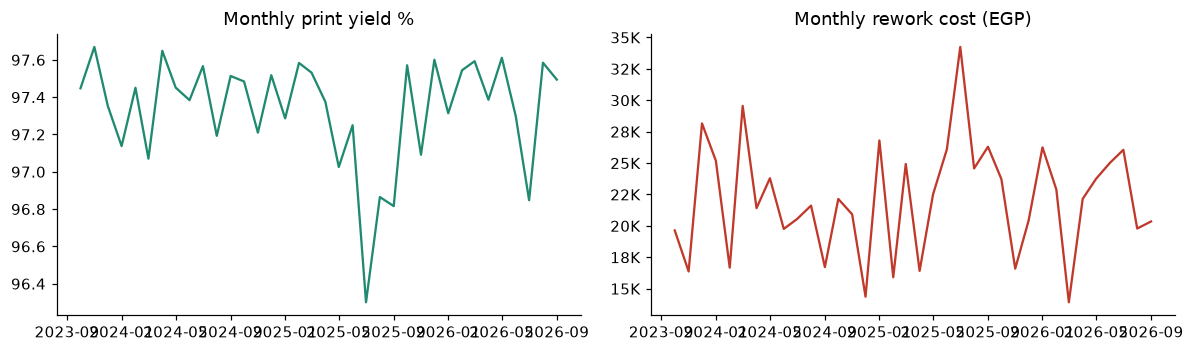

Reject rate % by machine x print type:


Print_Type,Digital,Heat Transfer,Screen,Water-Based
Machine_ID,,,,
PR-M01,2.58,2.69,2.41,2.78
PR-M02,2.62,2.57,2.60,2.44
PR-M03,3.03,2.77,2.80,3.22
PR-M04,2.68,2.67,2.70,2.41
PR-M05,2.48,2.57,2.72,2.72


In [77]:
# 8.2 Print type, defect types and periods
ptype = pagg(pb.groupby('Print_Type')); display(ptype[['batches', 'printed', 'yield_%', 'reject_%', 'reprint_%', 'cost_per_good_unit', 'rework']].round(2))
dd = pb[pb.has_defect].groupby('Defect_Type').agg(batches=('Print_Batch_ID', 'count'), rejected=('Rejected_Qty', 'sum'), rework=('Rework_Cost_EGP', 'sum')).sort_values('rework', ascending=False)
dd['cum_rework_%'] = dd.rework.cumsum() / dd.rework.sum() * 100; display(dd.round(1))
mt = pagg(pb.groupby('Month'))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(mt.index, mt['yield_%'], color=GREEN); ax[0].set_title('Monthly print yield %')
ax[1].plot(mt.index, mt.rework, color=RED); ax[1].yaxis.set_major_formatter(mill); ax[1].set_title('Monthly rework cost (EGP)'); plt.tight_layout(); plt.show()
mm_ = pb.pivot_table(index='Machine_ID', columns='Print_Type', values='Rejected_Qty', aggfunc='sum') / pb.pivot_table(index='Machine_ID', columns='Print_Type', values='Printed_Qty', aggfunc='sum') * 100
print('Reject rate % by machine x print type:'); display(mm_.round(2))

Downtime events on printing machines: 1,193 of 2,800 total | hours: 2,678 (unplanned 2,130, planned 548)


Reason,Electrical fault,Material wait,Mechanical fault,Operator shortage,Planned maintenance,Setup / changeover,total_hours
Machine_ID,,,,,,,
PR-M02,72.0,87.0,176.0,36.0,106.0,114.0,591.0
PR-M03,47.0,53.0,162.0,65.0,129.0,97.0,554.0
PR-M01,53.0,92.0,120.0,66.0,98.0,111.0,541.0
PR-M04,65.0,84.0,138.0,34.0,78.0,102.0,501.0
PR-M05,33.0,71.0,108.0,43.0,137.0,100.0,492.0


,events,hours,avg_hours,cum_%
Reason,,,,
Mechanical fault,291,705.2,2.4,26.3
Planned maintenance,255,547.6,2.1,46.8
Setup / changeover,242,524.2,2.2,66.4
Material wait,166,387.8,2.3,80.8
Electrical fault,120,269.4,2.2,90.9
Operator shortage,119,243.7,2.0,100.0


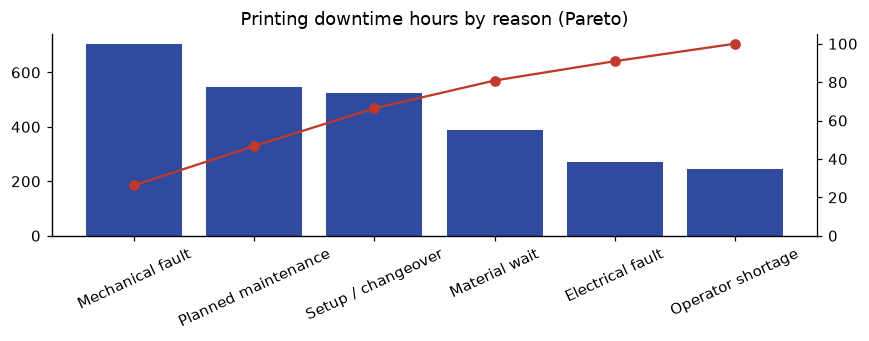

In [ ]:
# 8.3 Downtime
dt = clean['Machine_Downtime'].copy(); dtp = dt[dt.Machine_ID.isin(pb.Machine_ID.unique())].copy()
print(f'Downtime events on printing machines: {len(dtp):,} of {len(dt):,} total | hours: {dtp.Downtime_Hours.sum():,.0f} (unplanned {dtp[dtp.Planned == "No"].Downtime_Hours.sum():,.0f}, planned {dtp[dtp.Planned == "Yes"].Downtime_Hours.sum():,.0f})')
dm = dtp.pivot_table(index='Machine_ID', columns='Reason', values='Downtime_Hours', aggfunc='sum').fillna(0); dm['total_hours'] = dm.sum(axis=1)
display(dm.sort_values('total_hours', ascending=False).round(0))
rs = dtp.groupby('Reason').agg(events=('Downtime_ID', 'count'), hours=('Downtime_Hours', 'sum'), avg_hours=('Downtime_Hours', 'mean')).sort_values('hours', ascending=False)
rs['cum_%'] = rs.hours.cumsum() / rs.hours.sum() * 100; display(rs.round(1))
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.bar(rs.index, rs.hours, color=BLUE); ax.tick_params(axis='x', rotation=25); a2 = ax.twinx(); a2.plot(rs.index, rs['cum_%'], color=RED, marker='o'); a2.set_ylim(0, 105); a2.spines['right'].set_visible(True)
ax.set_title('Printing downtime hours by reason (Pareto)'); plt.tight_layout(); plt.show()

In [79]:
# 8.4 Maintenance priority score per machine (equal weights, rank-based, higher = fix first)
unpl = dtp[dtp.Planned == 'No'].groupby('Machine_ID').Downtime_Hours.sum()
fail = dtp[dtp.Reason.isin(['Mechanical fault', 'Electrical fault'])].groupby('Machine_ID').Downtime_Hours.sum()
ms = mach[['reject_%', 'reprint_%', 'rework', 'cost_per_good_unit']].copy(); ms['unplanned_downtime_h'] = unpl; ms['fault_hours'] = fail; ms = ms.fillna(0)
for c in ['reject_%', 'rework', 'unplanned_downtime_h', 'fault_hours']: ms['rank_' + c] = ms[c].rank(ascending=False)
ms['priority_score'] = 6 - ms[[c for c in ms.columns if c.startswith('rank_')]].mean(axis=1)
ms = ms.sort_values('priority_score', ascending=False); display(ms[['reject_%', 'rework', 'unplanned_downtime_h', 'fault_hours', 'cost_per_good_unit', 'priority_score']].round(2))
print('Correlation across machines: reject rate vs unplanned downtime =', round(ms['reject_%'].corr(ms.unplanned_downtime_h), 2), '(only 5 machines, so indicative only).')
# Value of getting every machine to the best machine's yield
best_yield = mach['yield_%'].max() / 100; gain_units = (best_yield * mach.printed - mach.good).clip(lower=0).sum()
gain_value = gain_units * (pb.Rework_Cost_EGP.sum() / pb.Rejected_Qty.sum() + (pb.Ink_or_Consumable_Cost_EGP.sum() / pb.Printed_Qty.sum()))
print(f'If every machine matched the best yield ({best_yield:.2%}), {gain_units:,.0f} more good units would come from the same print volume (about {EG(gain_value)} of rework and consumables avoided).')

,reject_%,rework,unplanned_downtime_h,fault_hours,cost_per_good_unit,priority_score
Machine_ID,,,,,,
PR-M03,2.96,171904.25,424.7,209.2,4.77,4.25
PR-M01,2.61,159322.54,442.7,173.1,4.77,3.25
PR-M02,2.56,155570.92,484.8,248.4,4.68,3.25
PR-M04,2.61,157148.76,423.3,203.0,4.67,2.50
PR-M05,2.61,151641.18,354.8,140.9,4.65,1.75


Correlation across machines: reject rate vs unplanned downtime = -0.12 (only 5 machines, so indicative only).
If every machine matched the best yield (97.44%), 6,275 more good units would come from the same print volume (about 59,851 EGP of rework and consumables avoided).


In [80]:
# 8.5 KEY TAKEAWAYS (computed)
bm, wmach = mach['yield_%'].idxmax(), mach['yield_%'].idxmin(); yspread = mach['yield_%'].max() - mach['yield_%'].min()
print(f'1. Yield: all machines are close ({mach["yield_%"].min():.2f}% to {mach["yield_%"].max():.2f}%, {yspread:.2f} points). Weakest: {wmach}; best: {bm}. Overall reject rate {pb.Rejected_Qty.sum()/pb.Printed_Qty.sum():.2%}.')
print(f'2. Cost: rework and reprint cost {EG(pb.Rework_Cost_EGP.sum())} ({pb.Rework_Cost_EGP.sum()/(pb.Rework_Cost_EGP.sum()+pb.Ink_or_Consumable_Cost_EGP.sum()):.1%} of printing cost); consumables are the real cost ({EG(pb.Ink_or_Consumable_Cost_EGP.sum())}). Highest cost per good unit: {mach.cost_per_good_unit.idxmax()} ({mach.cost_per_good_unit.max():.2f} EGP).')
print(f'3. Defects: top defect by rework cost = {dd.index[0]} ({dd.rework.iloc[0]/dd.rework.sum():.0%}); defect types are evenly spread (top 3 = {dd["cum_rework_%"].iloc[2]:.0f}%). Highest reject rate by print type: {ptype["reject_%"].idxmax()} ({ptype["reject_%"].max():.2f}%).')
print(f'4. Downtime: {dtp.Downtime_Hours.sum():,.0f} hours on printing machines, {dtp[dtp.Planned == "No"].Downtime_Hours.sum()/dtp.Downtime_Hours.sum():.0%} unplanned; top reason = {rs.index[0]} ({rs.hours.iloc[0]/rs.hours.sum():.0%}), then {rs.index[1]} ({rs.hours.iloc[1]/rs.hours.sum():.0%}). Printing is the area with the most downtime events in the group ({len(dtp)/len(dt):.0%} of all events).')
print(f'5. Action: maintenance order = {", ".join(ms.index[:3])}. Matching the best machine yield avoids only about {EG(gain_value)} of rework and consumables: printing is already efficient, so the bigger prize is cutting unplanned downtime ({dtp[dtp.Planned == "No"].Downtime_Hours.sum():,.0f} hours) and the production rejects in Card 06/07.')

1. Yield: all machines are close (97.04% to 97.44%, 0.40 points). Weakest: PR-M03; best: PR-M02. Overall reject rate 2.67%.
2. Cost: rework and reprint cost 795,588 EGP (3.0% of printing cost); consumables are the real cost (26,075,587 EGP). Highest cost per good unit: PR-M03 (4.77 EGP).
3. Defects: top defect by rework cost = Color Misalignment (21%); defect types are evenly spread (top 3 = 62%). Highest reject rate by print type: Water-Based (2.70%).
4. Downtime: 2,678 hours on printing machines, 80% unplanned; top reason = Mechanical fault (26%), then Planned maintenance (20%). Printing is the area with the most downtime events in the group (43% of all events).
5. Action: maintenance order = PR-M03, PR-M01, PR-M02. Matching the best machine yield avoids only about 59,851 EGP of rework and consumables: printing is already efficient, so the bigger prize is cutting unplanned downtime (2,130 hours) and the production rejects in Card 06/07.


## Card 09: Supply Chain & Materials
**Question:** Material availability and supplier reliability can create factory delays, excess cost and shortages.

**Approach:** purchase-order KPIs (lead time, on-time, in-full, OTIF) → supplier and material scorecards → cost trend → material **criticality** (sales exposure through the BOM) → supplier x material **action matrix**.

In [81]:
# 9.1 Purchase-order KPIs
po = clean['Purchase_Orders'].copy()
mat = clean['Materials'].set_index('Material_ID'); sup = clean['Suppliers'].set_index('Supplier_ID')
po['Category'] = po.Material_ID.map(mat.Material_Category); po['std_lead_time'] = po.Material_ID.map(mat.Standard_Lead_Time_Days)
po['lead_actual'] = (po.Actual_Receipt_Date - po.Order_Date).dt.days
po['lead_promised'] = (po.Promised_Date - po.Order_Date).dt.days
po['delay_days'] = (po.Actual_Receipt_Date - po.Promised_Date).dt.days
po['on_time'] = po.delay_days <= 0
po['accept_%'] = po.Accepted_Qty / po.Ordered_Qty * 100
IN_FULL_MIN = 97
po['in_full'] = po['accept_%'] >= IN_FULL_MIN
po['OTIF'] = po.on_time & po.in_full
po['spend'] = po.Ordered_Qty * po.Unit_Cost_EGP; po['reject_cost'] = po.Rejected_Qty * po.Unit_Cost_EGP
po['Month'] = po.Order_Date.dt.to_period('M').dt.to_timestamp()
po['FY'] = fy_label(po.Order_Date)
def sagg(g):
    r = g.agg(pos=('PO_ID', 'count'), spend=('spend', 'sum'), ordered=('Ordered_Qty', 'sum'), accepted=('Accepted_Qty', 'sum'), on_time=('on_time', 'mean'), in_full=('in_full', 'mean'), OTIF=('OTIF', 'mean'),
              lead_actual=('lead_actual', 'mean'), lead_promised=('lead_promised', 'mean'), delay_avg=('delay_days', 'mean'), delay_p90=('delay_days', lambda x: x.quantile(.9)), reject_cost=('reject_cost', 'sum'))
    r['accept_%'] = r.accepted / r.ordered * 100; r['reject_%'] = 100 - r['accept_%']
    for c in ['on_time', 'in_full', 'OTIF']: r[c] = r[c] * 100
    r['lead_slip_days'] = r.lead_actual - r.lead_promised; return r
print(f'{len(po):,} purchase orders | spend {EG(po.spend.sum())} | on-time {po.on_time.mean():.1%} | in-full (>= {IN_FULL_MIN}%) {po.in_full.mean():.1%} | OTIF {po.OTIF.mean():.1%} | avg delay when late {po[po.delay_days > 0].delay_days.mean():.1f} days | rejected material cost {EG(po.reject_cost.sum())}')
supp = sagg(po.groupby('Supplier_ID')).join(sup[['Primary_Category', 'Governorate', 'Payment_Terms_Days', 'Contracted']]).sort_values('OTIF')
display(supp[['Primary_Category', 'Contracted', 'pos', 'spend', 'on_time', 'in_full', 'OTIF', 'lead_actual', 'lead_slip_days', 'delay_p90', 'reject_%', 'reject_cost']].round(1))

3,600 purchase orders | spend 884,773,205 EGP | on-time 65.4% | in-full (>= 97%) 85.2% | OTIF 56.0% | avg delay when late 2.8 days | rejected material cost 15,206,735 EGP


,Primary_Category,Contracted,pos,spend,on_time,in_full,OTIF,lead_actual,lead_slip_days,delay_p90,reject_%,reject_cost
Supplier_ID,,,,,,,,,,,,
SUP09,Trims,No,289,76331660.2,34.6,79.2,27.3,14.7,3.6,12.0,1.9,1403149.9
SUP04,Printing Consumables,Yes,281,65328364.4,39.9,86.5,33.8,14.7,2.9,8.0,1.7,1062472.5
SUP12,Fabric,Yes,298,61850511.2,66.8,85.2,57.7,12.1,0.5,2.0,1.8,1138236.0
SUP06,Packaging,Yes,312,72353891.2,67.9,86.2,59.0,11.9,0.5,2.0,1.7,1245277.2
SUP11,Trims,Yes,305,76543735.7,72.5,82.3,59.7,11.9,0.4,2.0,1.9,1358579.5
SUP08,Trims,No,316,81631567.6,69.0,85.1,60.8,11.6,0.5,2.0,1.7,1331289.6
SUP07,Packaging,Yes,335,84758330.2,69.3,86.0,60.9,12.1,0.5,2.0,1.7,1379155.0
SUP02,Trims,Yes,297,69784488.3,72.7,86.2,61.6,11.4,0.4,2.0,1.7,1250360.0
SUP05,Fabric,No,297,73873102.5,72.4,85.9,61.6,11.9,0.4,2.0,1.8,1364090.8


,Material_Name,Material_Category,pos,spend,Standard_Lead_Time_Days,lead_actual,lead_vs_standard_days,on_time,OTIF,delay_p90,reject_%
Material_ID,,,,,,,,,,,
M011,Water-Based Ink,Printing,286,297682642.2,21,12.4,-8.6,66.8,60.8,3.0,1.6
M003,Rib Cotton,Fabric,321,97389898.9,10,12.5,2.5,67.3,58.3,2.0,1.7
M002,Single Jersey Cotton 180 GSM,Fabric,302,95957491.9,14,11.9,-2.1,68.5,59.9,3.0,1.7
M005,Elastic Band,Trims,279,84809139.0,7,12.6,5.6,65.6,53.4,3.0,1.8
M001,Single Jersey Cotton 160 GSM,Fabric,286,83881844.0,10,11.9,1.9,66.4,55.9,2.5,1.8
M004,Summer Melton,Fabric,286,83323470.0,10,12.1,2.1,64.3,55.9,3.0,1.8
M006,Sewing Thread,Trims,303,67051227.9,14,12.7,-1.3,61.1,52.8,3.0,1.7
M012,Heat Transfer Film,Printing,335,32385916.5,7,12.0,5.0,63.6,54.0,3.0,1.8
M010,Carton Box,Packaging,310,10910652.8,10,12.7,2.7,60.3,50.0,3.0,1.8


,pos,spend,on_time,OTIF,lead_actual,reject_%,reject_cost
Category,,,,,,,
Fabric,1195,360552704.8,66.7,57.6,12.1,1.7,6293545.1
Packaging,613,21150082.2,62.6,52.7,12.5,1.8,368575.6
Printing,621,330068558.7,65.1,57.2,12.2,1.8,5459206.9
Trims,1171,173001859.1,65.6,55.5,12.5,1.7,3085407.9


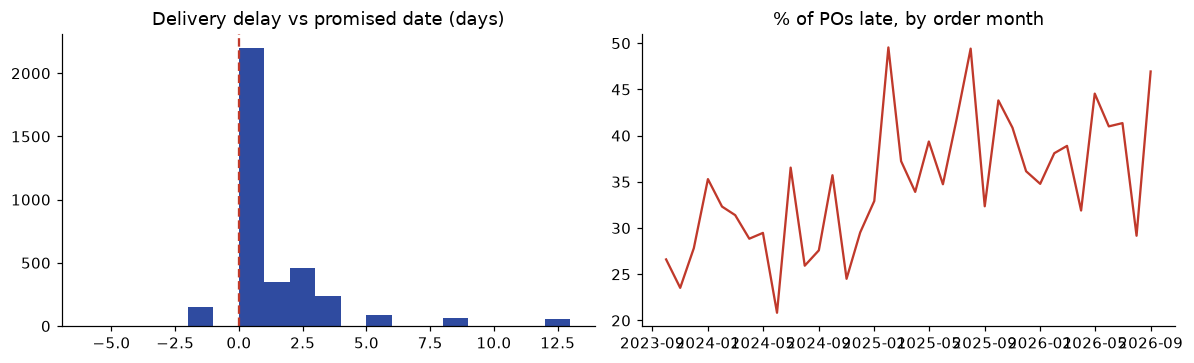

In [82]:
# 9.2 Material scorecard: actual vs standard lead time, delays, rejects
mats = sagg(po.groupby('Material_ID')).join(mat[['Material_Name', 'Material_Category', 'Standard_Lead_Time_Days']])
mats['lead_vs_standard_days'] = mats.lead_actual - mats.Standard_Lead_Time_Days
display(mats[['Material_Name', 'Material_Category', 'pos', 'spend', 'Standard_Lead_Time_Days', 'lead_actual', 'lead_vs_standard_days', 'on_time', 'OTIF', 'delay_p90', 'reject_%']].sort_values('spend', ascending=False).round(1))
cat = sagg(po.groupby('Category')); display(cat[['pos', 'spend', 'on_time', 'OTIF', 'lead_actual', 'reject_%', 'reject_cost']].round(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(po.delay_days, bins=range(int(po.delay_days.min()), int(po.delay_days.max()) + 2), color=BLUE); ax[0].axvline(0, color=RED, ls='--'); ax[0].set_title('Delivery delay vs promised date (days)')
m9 = po.groupby('Month').agg(late=('on_time', lambda x: (1 - x.mean()) * 100)); ax[1].plot(m9.index, m9.late, color=RED); ax[1].set_title('% of POs late, by order month'); plt.tight_layout(); plt.show()

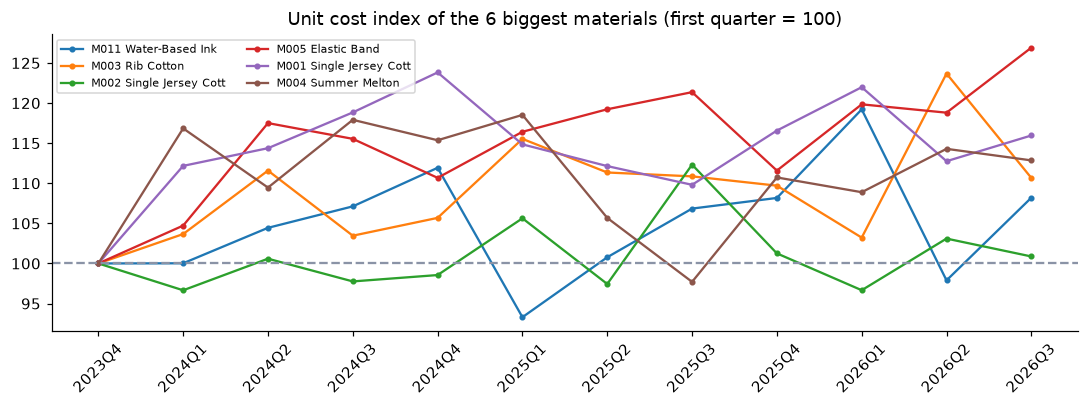

,cost_change_FY24_to_FY26_%,cost_volatility_CV_%,Material_Name,spend
Material_ID,,,,
M011,5.3,6.6,Water-Based Ink,297682642.2
M003,7.3,5.9,Rib Cotton,97389898.9
M002,2.0,4.5,Single Jersey Cotton 180 GSM,95957491.9
M005,8.5,6.4,Elastic Band,84809139.0
M001,4.9,5.4,Single Jersey Cotton 160 GSM,83881844.0
M004,2.8,6.1,Summer Melton,83323470.0
M006,7.7,4.7,Sewing Thread,67051227.9
M012,6.0,6.8,Heat Transfer Film,32385916.5
M010,0.8,12.1,Carton Box,10910652.8


Spend-weighted unit-cost change FY24 -> FY26: +5.2%


In [ ]:
# 9.3 Cost trend
po['Q'] = po.Order_Date.dt.to_period('Q')
qc_ = po.groupby(['Q', 'Material_ID']).apply(lambda d: (d.spend.sum() / d.Ordered_Qty.sum())).unstack()
idx = qc_ / qc_.iloc[0] * 100
fig, ax = plt.subplots(figsize=(10, 3.8))
for c in mats.sort_values('spend', ascending=False).index[:6]: ax.plot(idx.index.astype(str), idx[c], marker='o', ms=3, label=f'{c} {mat.loc[c, "Material_Name"][:18]}')
ax.axhline(100, color=GREY, ls='--'); ax.legend(fontsize=7, ncol=2); ax.set_title('Unit cost index of the 6 biggest materials (first quarter = 100)'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
fyc = po.groupby(['FY', 'Material_ID']).apply(lambda d: d.spend.sum() / d.Ordered_Qty.sum()).unstack()
chg = pd.DataFrame({'cost_change_FY24_to_FY26_%': (fyc.loc[FYS[-1]] / fyc.loc[FYS[0]] - 1) * 100, 'cost_volatility_CV_%': qc_.std() / qc_.mean() * 100}).join(mats[['Material_Name', 'spend']])
display(chg.sort_values('spend', ascending=False).round(1))
w = (chg['cost_change_FY24_to_FY26_%'] * chg.spend / chg.spend.sum()).sum()
print(f'Spend-weighted unit-cost change FY24 -> FY26: {w:+.1f}%')

In [ ]:
# 9.4 Criticality
bom = clean['Product_BOM']
s12 = s[s.Order_Date > DATA_END - pd.DateOffset(months=12)]
prod12 = s12.groupby('Product_ID').agg(units=('Quantity', 'sum'), net=('Net_Sales_EGP', 'sum'), gp=('Gross_Profit_EGP', 'sum'))
b = bom.join(prod12, on='Product_ID'); b['need_qty'] = b.units * b.Required_Per_Unit
crit = b.groupby('Material_ID').agg(products_using=('Product_ID', 'nunique'), need_12m=('need_qty', 'sum'))
crit['sales_exposure_%'] = [prod12.loc[bom[bom.Material_ID == m].Product_ID.unique()].net.sum() / prod12.net.sum() * 100 for m in crit.index]
crit['gp_exposure_%'] = [prod12.loc[bom[bom.Material_ID == m].Product_ID.unique()].gp.sum() / prod12.gp.sum() * 100 for m in crit.index]
crit = crit.reindex(mat.index)
crit['spend_share_%'] = mats.spend / mats.spend.sum() * 100
crit['std_lead_time'] = mat.Standard_Lead_Time_Days
unused = crit[crit.products_using.isna()].index.tolist()
crit['crit_score'] = pd.concat([crit['sales_exposure_%'].fillna(0).rank(pct=True), crit['spend_share_%'].rank(pct=True), crit.std_lead_time.rank(pct=True)], axis=1).mean(axis=1) * 100
crit['criticality'] = np.where(crit.crit_score >= crit.crit_score.median(), 'High', 'Low')
purch12 = po[po.Order_Date > DATA_END - pd.DateOffset(months=12)].groupby('Material_ID').Accepted_Qty.sum()
crit['purchased_12m_accepted'] = purch12; crit['purchase_vs_BOM_need'] = crit.purchased_12m_accepted / crit.need_12m
display(crit.join(mat[['Material_Name', 'Unit']]).sort_values('crit_score', ascending=False).round(2))
print('Materials in the master but not used in any BOM:', unused, '-> ordered but not consumed by any product: review for waste or missing BOM lines.')
print('Purchases vs BOM-implied need (last 12 months), median ratio:', round(crit.purchase_vs_BOM_need.median(), 2), '(1.0 = purchases equal need; far from 1 = BOM or PO quantities are on a different scale)')

,products_using,need_12m,sales_exposure_%,gp_exposure_%,spend_share_%,std_lead_time,crit_score,criticality,purchased_12m_accepted,purchase_vs_BOM_need,Material_Name,Unit
Material_ID,,,,,,,,,,,,
M011,25.0,7021.20,37.30,37.11,33.65,21,88.89,High,287407,40.93,Water-Based Ink,kg
M006,59.0,14460.88,100.00,100.00,7.58,14,73.61,High,255898,17.70,Sewing Thread,cone
M003,16.0,132827.37,27.62,22.85,11.01,10,68.06,High,316513,2.38,Rib Cotton,meter
M002,15.0,119440.48,25.27,28.26,10.85,14,66.67,High,357362,2.99,Single Jersey Cotton 180 GSM,meter
M008,59.0,584172.00,100.00,100.00,1.17,14,62.50,High,675062,1.16,Care Label,piece
M001,15.0,133239.43,26.62,30.09,9.48,10,56.94,High,263144,1.97,Single Jersey Cotton 160 GSM,meter
M004,13.0,93913.39,20.49,18.80,9.42,10,45.83,Low,301960,3.22,Summer Melton,meter
M007,59.0,584172.00,100.00,100.00,1.22,7,44.44,Low,730555,1.25,Neck Label,piece
M009,59.0,584172.00,100.00,100.00,1.16,7,38.89,Low,745274,1.28,Poly Bag,piece


Materials in the master but not used in any BOM: ['M005', 'M010'] -> ordered but not consumed by any product: review for waste or missing BOM lines.
Purchases vs BOM-implied need (last 12 months), median ratio: 2.69 (1.0 = purchases equal need; far from 1 = BOM or PO quantities are on a different scale)


In [85]:
# 9.5 Single-sourcing and supplier x material action matrix
share = po.groupby(['Material_ID', 'Supplier_ID']).spend.sum().unstack().fillna(0); share = share.div(share.sum(axis=1), axis=0) * 100
top_sup = share.idxmax(axis=1); top_share = share.max(axis=1); n_sup = (share > 0).sum(axis=1)
conc = pd.DataFrame({'suppliers': n_sup, 'top_supplier': top_sup, 'top_supplier_share_%': top_share}).join(mat.Material_Name)
display(conc.round(0))
pair = sagg(po.groupby(['Material_ID', 'Supplier_ID'])).reset_index(); pair = pair[pair.pos >= 5].copy()
pair = pair.merge(crit[['criticality', 'crit_score']].reset_index(), on='Material_ID').merge(mat.Material_Name.reset_index(), on='Material_ID')
OTIF_ALL = po.OTIF.mean() * 100
# Rule (assumption): a supplier-material pair is POOR if its OTIF is 8+ points below the company average, or its 90th-percentile delay exceeds 5 days, or rejects exceed 2.5%
pair['performance'] = np.where((pair.OTIF < OTIF_ALL - 8) | (pair.delay_p90 > 5) | (pair['reject_%'] > 2.5), 'Poor', 'Good')
def action(r):
    if r.criticality == 'High' and r.performance == 'Poor': return '1-ESCALATE: dual-source + expedite clause + safety stock'
    if r.criticality == 'High' and r.performance == 'Good': return '2-SECURE: long-term contract, protect capacity'
    if r.criticality == 'Low' and r.performance == 'Poor': return '3-REPLACE / renegotiate price and terms'
    return '4-MAINTAIN: routine review'
pair['action'] = pair.apply(action, axis=1)
pair = pair.merge(sup[['Contracted']].reset_index(), on='Supplier_ID')
am = pair.sort_values(['action', 'spend'], ascending=[True, False])[['Material_ID', 'Material_Name', 'Supplier_ID', 'Contracted', 'criticality', 'performance', 'pos', 'spend', 'OTIF', 'on_time', 'delay_p90', 'reject_%', 'action']]
am.to_csv(os.path.join(OUT_DIR, 'supplier_material_action_matrix.csv'), index=False)
print(am.action.value_counts().to_string()); display(am.head(12).round(1))

,suppliers,top_supplier,top_supplier_share_%,Material_Name
Material_ID,,,,
M001,12,SUP12,10.0,Single Jersey Cotton 160 GSM
M002,12,SUP06,10.0,Single Jersey Cotton 180 GSM
M003,12,SUP10,11.0,Rib Cotton
M004,12,SUP05,12.0,Summer Melton
M005,12,SUP11,10.0,Elastic Band
M006,12,SUP02,10.0,Sewing Thread
M007,12,SUP06,12.0,Neck Label
M008,12,SUP08,11.0,Care Label
M009,12,SUP10,11.0,Poly Bag


action
2-SECURE: long-term contract, protect capacity              58
4-MAINTAIN: routine review                                  54
3-REPLACE / renegotiate price and terms                     18
1-ESCALATE: dual-source + expedite clause + safety stock    14


,Material_ID,Material_Name,Supplier_ID,Contracted,criticality,performance,pos,spend,OTIF,on_time,delay_p90,reject_%,action
128,M011,Water-Based Ink,SUP09,No,High,Poor,36,33393006.4,27.8,30.6,12.0,1.8,1-ESCALATE: dual-source + expedite clause + safety stock
123,M011,Water-Based Ink,SUP04,Yes,High,Poor,18,18113062.0,61.1,61.1,12.0,1.5,1-ESCALATE: dual-source + expedite clause + safety stock
15,M002,Single Jersey Cotton 180 GSM,SUP04,Yes,High,Poor,26,9237203.2,42.3,46.2,10.0,1.8,1-ESCALATE: dual-source + expedite clause + safety stock
20,M002,Single Jersey Cotton 180 GSM,SUP09,No,High,Poor,31,8729503.6,29.0,32.3,12.0,1.6,1-ESCALATE: dual-source + expedite clause + safety stock
27,M003,Rib Cotton,SUP04,Yes,High,Poor,28,8070569.8,21.4,28.6,5.9,1.5,1-ESCALATE: dual-source + expedite clause + safety stock
32,M003,Rib Cotton,SUP09,No,High,Poor,20,7722995.0,50.0,60.0,8.4,1.8,1-ESCALATE: dual-source + expedite clause + safety stock
4,M001,Single Jersey Cotton 160 GSM,SUP05,No,High,Poor,21,6915406.4,47.6,66.7,2.0,1.7,1-ESCALATE: dual-source + expedite clause + safety stock
63,M006,Sewing Thread,SUP04,Yes,High,Poor,29,6267236.8,37.9,37.9,8.0,1.9,1-ESCALATE: dual-source + expedite clause + safety stock
8,M001,Single Jersey Cotton 160 GSM,SUP09,No,High,Poor,17,5886517.9,17.6,29.4,9.6,2.0,1-ESCALATE: dual-source + expedite clause + safety stock
3,M001,Single Jersey Cotton 160 GSM,SUP04,Yes,High,Poor,23,5710121.2,30.4,43.5,5.0,2.2,1-ESCALATE: dual-source + expedite clause + safety stock


In [86]:
# 9.6 Supplier consolidation scenario + PO data plausibility
tot_cogs = s.Estimated_COGS_EGP.sum()
print(f'Plausibility: total PO spend {EG(po.spend.sum())} vs total estimated COGS of everything sold {EG(tot_cogs)} (ratio {po.spend.sum()/tot_cogs:.1f}x). PO quantities and costs are therefore NOT on the same scale as the sales data: this notebook uses POs for supplier BEHAVIOUR (lateness, lead time, rejects, price trend) and never for volumes.')
bad_s = supp[(supp.OTIF < OTIF_ALL - 20)].index.tolist(); good = po[~po.Supplier_ID.isin(bad_s)]
late_bad = (~po[po.Supplier_ID.isin(bad_s)].on_time).sum(); n_bad = po.Supplier_ID.isin(bad_s).sum()
avoided = late_bad - n_bad * (1 - good.on_time.mean())
print(f'Outlier suppliers (OTIF more than 20 points below average): {bad_s}. They hold {n_bad/len(po):.0%} of POs and {po[po.Supplier_ID.isin(bad_s)].spend.sum()/po.spend.sum():.0%} of spend but cause {late_bad/(~po.on_time).sum():.0%} of all late POs.')
print(f'Every material is already bought from all {po.Supplier_ID.nunique()} suppliers, so no new supplier is needed: moving their volume to the other suppliers (on-time {good.on_time.mean():.0%}) would avoid about {avoided:,.0f} late POs over 3 years ({avoided/len(po):.1%} of all POs), lifting overall on-time from {po.on_time.mean():.1%} to {(po.on_time.sum() + avoided)/len(po):.1%}.')

Plausibility: total PO spend 884,773,205 EGP vs total estimated COGS of everything sold 356,450,088 EGP (ratio 2.5x). PO quantities and costs are therefore NOT on the same scale as the sales data: this notebook uses POs for supplier BEHAVIOUR (lateness, lead time, rejects, price trend) and never for volumes.
Outlier suppliers (OTIF more than 20 points below average): ['SUP09', 'SUP04']. They hold 16% of POs and 16% of spend but cause 29% of all late POs.
Every material is already bought from all 12 suppliers, so no new supplier is needed: moving their volume to the other suppliers (on-time 71%) would avoid about 191 late POs over 3 years (5.3% of all POs), lifting overall on-time from 65.4% to 70.7%.


In [87]:
# 9.7 KEY TAKEAWAYS (computed)
worst_s = supp.OTIF.idxmin(); best_s = supp.OTIF.idxmax(); esc = am[am.action.str.startswith('1')]
print(f'1. Reliability: only {po.OTIF.mean():.0%} of POs are on time AND in full (on-time {po.on_time.mean():.0%}, in-full {po.in_full.mean():.0%}); late POs are {po[po.delay_days > 0].delay_days.mean():.1f} days late on average (p90 = {po.delay_days.quantile(.9):.0f} days).')
print(f'2. Two outliers: {", ".join(bad_s)} have OTIF of {supp.loc[bad_s, "OTIF"].round(0).astype(int).tolist()}% vs about {good.OTIF.mean()*100:.0f}% for the rest, and are responsible for {late_bad/(~po.on_time).sum():.0%} of late deliveries. {int((supp.Contracted == "No").sum())} of {len(supp)} suppliers are not contracted (they carry {supp[supp.Contracted == "No"].spend.sum()/supp.spend.sum():.0%} of spend).')
above = int((mats.lead_vs_standard_days > 0).sum()); below = int((mats.lead_vs_standard_days < 0).sum())
print(f'3. Lead-time master data is wrong for most materials: actual lead time is above the standard for {above} materials and below it for {below} (largest gaps: ' + ', '.join(f'{m} {mats.loc[m, "lead_vs_standard_days"]:+.0f}d' for m in mats.lead_vs_standard_days.abs().sort_values(ascending=False).index[:3]) + '). Planning on the standard misprices safety stock.')
print(f'4. Cost: spend-weighted unit cost moved {w:+.1f}% from {FYS[0]} to {FYS[-1]}; rejected material = {EG(po.reject_cost.sum())} ({po.reject_cost.sum()/po.spend.sum():.1%} of PO spend).')
print(f'5. Structure: supply is fragmented (every material comes from all 12 suppliers, top share {conc["top_supplier_share_%"].max():.0f}%): no single-source risk, but little purchasing leverage. {len(unused)} materials ({", ".join(unused)}) are not in any BOM yet carry {EG(po[po.Material_ID.isin(unused)].spend.sum())} of PO spend: BOM gap or waste.')
print(f'6. Action matrix: {len(esc)} supplier-material pairs need ESCALATION (critical material + poor supplier), {EG(esc.spend.sum())} of spend; saved to deliverables/supplier_material_action_matrix.csv. Priority 1: reallocate volume away from {", ".join(bad_s)}.')

1. Reliability: only 56% of POs are on time AND in full (on-time 65%, in-full 85%); late POs are 2.8 days late on average (p90 = 3 days).
2. Two outliers: SUP09, SUP04 have OTIF of [27, 34]% vs about 61% for the rest, and are responsible for 29% of late deliveries. 5 of 12 suppliers are not contracted (they carry 43% of spend).
3. Lead-time master data is wrong for most materials: actual lead time is above the standard for 8 materials and below it for 4 (largest gaps: M011 -9d, M005 +6d, M009 +5d). Planning on the standard misprices safety stock.
4. Cost: spend-weighted unit cost moved +5.2% from FY24 to FY26; rejected material = 15,206,735 EGP (1.7% of PO spend).
5. Structure: supply is fragmented (every material comes from all 12 suppliers, top share 13%): no single-source risk, but little purchasing leverage. 2 materials (M005, M010) are not in any BOM yet carry 95,719,792 EGP of PO spend: BOM gap or waste.
6. Action matrix: 14 supplier-material pairs need ESCALATION (critical mater

## Card 10: Integrated Management Story + Forecast
**Question:** Leadership needs one connected story from market demand to factory execution, not isolated charts.

**Approach:** one monthly panel linking sales, marketing, web, inventory, supply, production, quality and returns → test which links are statistically visible → **profit-leak map in EGP** → 12-month forecast with Base/Optimistic/Pessimistic scenarios → a quantified management action plan.

In [ ]:
# 10.1 Group operations and customer service
go = clean['Group_Operations']
bu = go.groupby('Business_Unit').agg(avg_efficiency_pct=('Operational_Efficiency_Pct', 'mean'), avg_open_issues=('Open_Issues_Count', 'mean'), volume_total=('Volume', 'sum'), kpi=('Primary_KPI', 'first'))
display(bu.round(1))
cs = clean['Customer_Service'].copy(); cs['Month'] = cs.Open_Date.dt.to_period('M').dt.to_timestamp()
cst = cs.groupby('Issue_Type').agg(tickets=('Ticket_ID', 'count'), resp_min=('First_Response_Minutes', 'mean'), resolution_h=('Resolution_Hours', 'mean'), resolved=('Resolved', lambda x: (x == 'Yes').mean() * 100), csat=('CSAT_1_to_5', 'mean')).sort_values('tickets', ascending=False)
display(cst.round(2))
print(f'Tickets: {len(cs):,} | average CSAT {cs.CSAT_1_to_5.mean():.2f}/5 | resolved {(cs.Resolved == "Yes").mean():.0%} | CSAT when unresolved {cs[cs.Resolved == "No"].CSAT_1_to_5.mean():.2f} vs resolved {cs[cs.Resolved == "Yes"].CSAT_1_to_5.mean():.2f}')

,avg_efficiency_pct,avg_open_issues,volume_total,kpi
Business_Unit,,,,
LEO DESIGN,85.6,3.4,2359,Designs_Completed
LEO MODA,89.6,3.1,1660589,Sales_Units
LEO PRINT,86.0,3.9,4700021,Print_Units
LEO PRODUCTION HUB,85.7,6.1,3271411,Garments_Produced
LEO TEX,88.8,3.6,4537691,Fabric_Meters


,tickets,resp_min,resolution_h,resolved,csat
Issue_Type,,,,,
Size guidance,1347,11.69,17.73,94.06,3.98
Order status,1273,11.16,16.79,95.60,4.02
General product question,1082,11.54,17.81,95.01,3.97
Exchange request,692,11.99,17.68,95.09,4.02
Product quality,668,11.46,18.28,94.46,3.97
Wholesale inquiry,599,11.64,16.94,96.66,4.04
Return request,526,11.32,16.78,95.63,3.99
Payment,313,11.13,17.34,94.89,4.02


Tickets: 6,500 | average CSAT 4.00/5 | resolved 95% | CSAT when unresolved 2.32 vs resolved 4.08


,mean,min,max
net_sales,11703843.8,8694838.5,15635963.3
gross_profit,1802452.5,1369113.8,2503709.5
margin_%,15.4,14.7,16.3
mkt_spend,405110.4,131882.0,799211.0
web_sessions,46612.8,29933.0,65639.0
web_conv_%,2.9,2.0,3.2
stockout_days,33.2,0.0,77.0
closing_stock_units,64225.3,51641.0,77867.0
po_late_%,34.9,20.8,49.5
po_reject_%,1.7,1.4,2.0


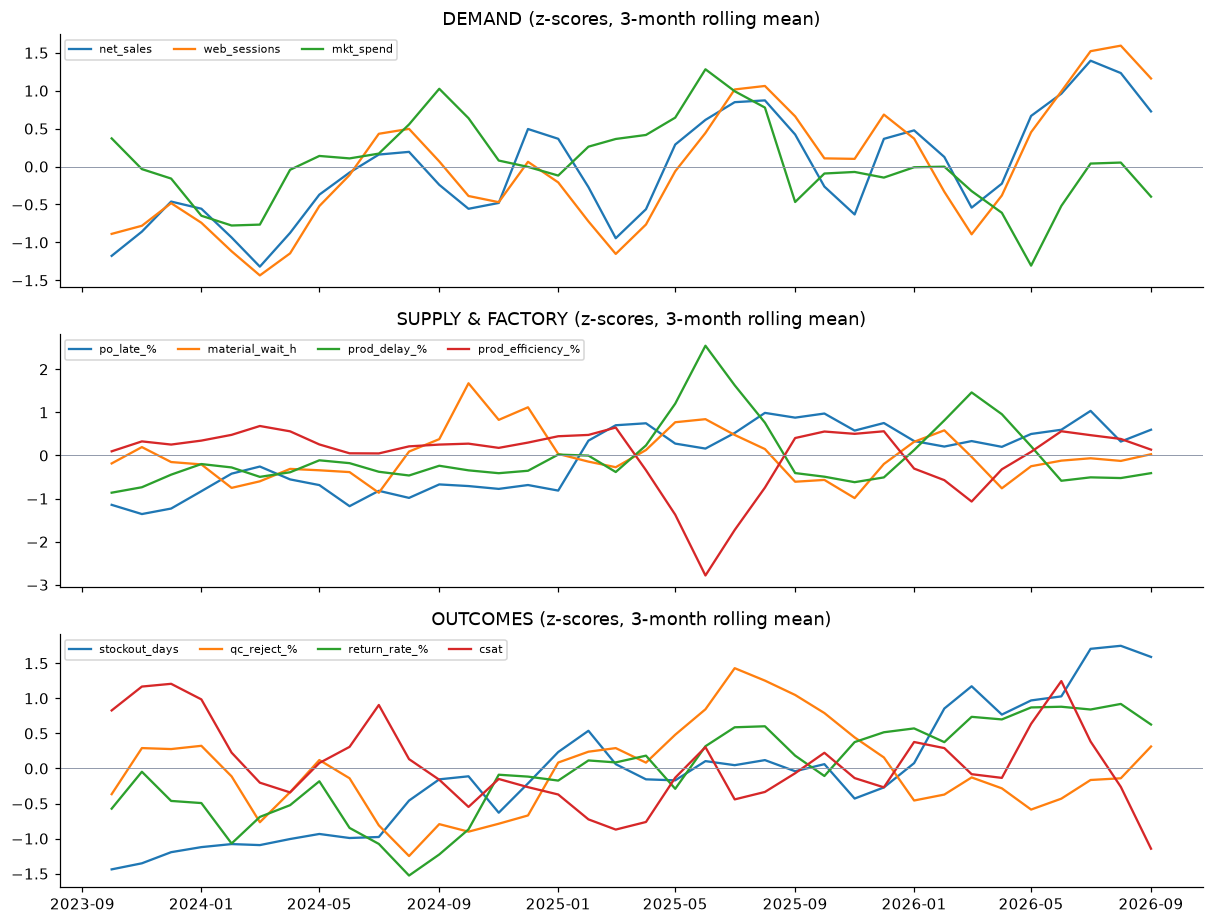

In [ ]:
# 10.2 The integrated monthly panel 
idxm = pd.date_range('2023-10-01', '2026-09-01', freq='MS')
P = pd.DataFrame(index=idxm)
P['net_sales'] = s.groupby('Month').Net_Sales_EGP.sum(); P['gross_profit'] = s.groupby('Month').Gross_Profit_EGP.sum(); P['margin_%'] = P.gross_profit / P.net_sales * 100
P['mkt_spend'] = mk.groupby('Month').Spend_EGP.sum(); P['web_sessions'] = wm.sessions; P['web_conv_%'] = wm.conv * 100
P['stockout_days'] = inv.groupby('Month').Stockout_Days_In_Month.sum(); P['closing_stock_units'] = inv.groupby('Month').Closing_Stock.sum()
P['po_late_%'] = (1 - po.groupby('Month').on_time.mean()) * 100; P['po_reject_%'] = 100 - po.groupby('Month').apply(lambda d: d.Accepted_Qty.sum() / d.Ordered_Qty.sum() * 100)
P['material_wait_h'] = dt[dt.Reason == 'Material wait'].groupby(dt.Date.dt.to_period('M').dt.to_timestamp()).Downtime_Hours.sum()
P['prod_efficiency_%'] = pr.groupby('Month').Efficiency_Pct.mean(); P['prod_delay_%'] = pr.groupby('Month').delayed.mean() * 100; P['prod_reject_%'] = pr.groupby('Month').apply(lambda d: d.Rejected_Qty.sum() / d.Produced_Qty.sum() * 100)
P['qc_reject_%'] = qc.groupby('Month').apply(lambda d: d.Rejected_Qty.sum() / d.Inspected_Qty.sum() * 100)
P['return_rate_%'] = s.groupby('Month').Is_Returned.mean() * 100; P['refund_EGP'] = s.groupby('Month').Refund_Value_EGP.sum()
P['csat'] = cs.groupby('Month').CSAT_1_to_5.mean(); P = P.fillna(0)
display(P.describe().T[['mean', 'min', 'max']].round(1))
z = (P - P.mean()) / P.std()
groups = {'DEMAND': ['net_sales', 'web_sessions', 'mkt_spend'], 'SUPPLY & FACTORY': ['po_late_%', 'material_wait_h', 'prod_delay_%', 'prod_efficiency_%'], 'OUTCOMES': ['stockout_days', 'qc_reject_%', 'return_rate_%', 'csat']}
fig, ax = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
for a, (g, cols) in zip(ax, groups.items()):
    for c in cols: a.plot(z.index, z[c].rolling(3, min_periods=1).mean(), label=c)
    a.axhline(0, color=GREY, lw=.6); a.set_title(g + ' (z-scores, 3-month rolling mean)'); a.legend(fontsize=7, ncol=4, loc='upper left')
plt.tight_layout(); plt.show()

In [ ]:
# 10.3 Lagged correlations (n = 36 months, so |r| > 0.33 is roughly the 95% threshold)
LINKS = [('po_late_%', 'material_wait_h', 'Late purchase orders -> material-wait downtime'), ('po_late_%', 'prod_delay_%', 'Late purchase orders -> production delays'),
         ('material_wait_h', 'prod_delay_%', 'Material-wait downtime -> production delays'), ('prod_delay_%', 'stockout_days', 'Production delays -> stockout days'),
         ('stockout_days', 'net_sales', 'Stockout days -> net sales'), ('mkt_spend', 'net_sales', 'Marketing spend -> net sales'), ('web_sessions', 'net_sales', 'Web sessions -> net sales'),
         ('qc_reject_%', 'return_rate_%', 'QC reject rate -> customer return rate'), ('return_rate_%', 'csat', 'Return rate -> CSAT')]
THR = 2 / np.sqrt(len(P)); rows = []
for a_, b_, name in LINKS:
    r = {lag: P[a_].shift(lag).corr(P[b_]) for lag in range(0, 4)}
    best = max(r, key=lambda k: abs(r[k]) if not np.isnan(r[k]) else 0)
    rd = P[a_].pct_change().replace([np.inf, -np.inf], np.nan).corr(P[b_].pct_change().replace([np.inf, -np.inf], np.nan))
    rows.append({'link': name, 'r_lag0': r[0], 'r_monthly_changes': rd, 'r_lag1': r[1], 'r_lag2': r[2], 'r_lag3': r[3], 'strongest_lag_months': best, 'strongest_r': r[best], 'significant': abs(r[best]) > THR})
lk = pd.DataFrame(rows); display(lk.round(2))
sig = lk[lk.significant]
print(f'{len(sig)} of {len(lk)} links exceed the significance threshold (|r| > {THR:.2f}).')
print('Visible links:', '; '.join(f'{r.link} (lag {r.strongest_lag_months}m, r={r.strongest_r:+.2f})' for r in sig.itertuples()) or 'none')
print('Caution: high lag-0 correlations such as web sessions vs net sales mostly reflect SHARED SEASONALITY; the column r_monthly_changes (correlation of month-to-month changes) is the stricter test. Stockouts correlate POSITIVELY with sales because stockouts happen in high-demand months (demand-driven), not because they raise sales.')
print('Reading: month-to-month statistical links between stages are weak in this modelled dataset, so the integrated story rests on STRUCTURAL links (BOM, lead times, product keys) and on EGP quantification, not on lead/lag correlations.')

,link,r_lag0,r_monthly_changes,r_lag1,r_lag2,r_lag3,strongest_lag_months,strongest_r,significant
0,Late purchase orders -> material-wait downtime,-0.13,-0.17,-0.09,0.09,0.09,0,-0.13,False
1,Late purchase orders -> production delays,0.06,-0.04,0.01,0.19,0.28,3,0.28,False
2,Material-wait downtime -> production delays,0.18,-0.03,0.34,0.16,-0.04,1,0.34,True
3,Production delays -> stockout days,0.26,0.08,0.09,0.08,0.09,0,0.26,False
4,Stockout days -> net sales,0.46,0.44,0.04,0.26,0.47,3,0.47,True
5,Marketing spend -> net sales,0.00,-0.14,0.11,0.03,-0.05,1,0.11,False
6,Web sessions -> net sales,0.90,0.88,0.48,-0.09,-0.20,0,0.90,True
7,QC reject rate -> customer return rate,0.39,0.37,0.00,-0.06,0.25,0,0.39,True
8,Return rate -> CSAT,-0.10,0.02,-0.12,0.29,-0.05,2,0.29,False


4 of 9 links exceed the significance threshold (|r| > 0.33).
Visible links: Material-wait downtime -> production delays (lag 1m, r=+0.34); Stockout days -> net sales (lag 3m, r=+0.47); Web sessions -> net sales (lag 0m, r=+0.90); QC reject rate -> customer return rate (lag 0m, r=+0.39)
Caution: high lag-0 correlations such as web sessions vs net sales mostly reflect SHARED SEASONALITY; the column r_monthly_changes (correlation of month-to-month changes) is the stricter test. Stockouts correlate POSITIVELY with sales because stockouts happen in high-demand months (demand-driven), not because they raise sales.
Reading: month-to-month statistical links between stages are weak in this modelled dataset, so the integrated story rests on STRUCTURAL links (BOM, lead times, product keys) and on EGP quantification, not on lead/lag correlations.


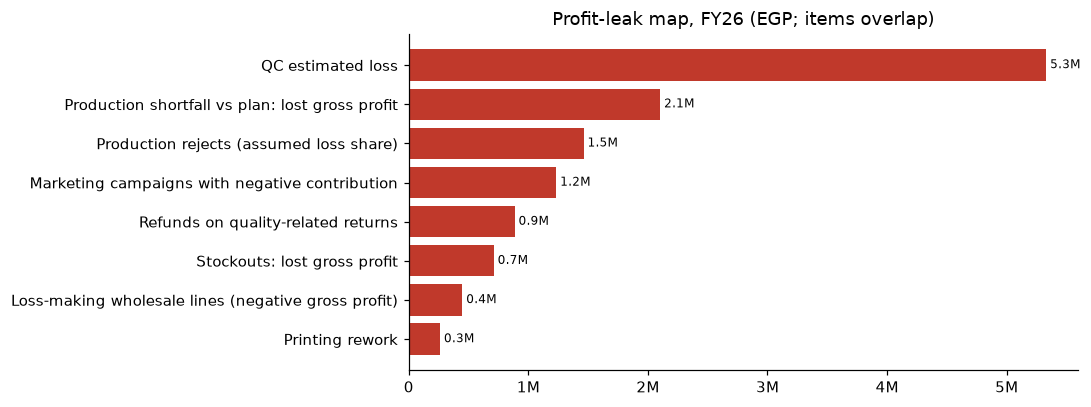

Sum of leaks (upper bound, overlaps possible): 12,429,757 EGP = 54% of FY26 gross profit (23,063,673 EGP).
Memo (not summed, scale caveat from Card 09): rejected purchased material 4,972,258 EGP. Cash tied in overstock (balance-sheet, one-off): 7,292,806 EGP.


In [ ]:
# 10.4 Profit-leak map
FYL = LAST_FY
wh_l = s[(s.Channel == 'Wholesale') & (s.FY == FYL)]
def cap_gain(df, cap, ret):
    over = df.Discount_Pct > cap; new_net = df.Gross_Sales_EGP * (1 - np.minimum(df.Discount_Pct, cap))
    return (np.where(over, ret * (new_net - df.Estimated_COGS_EGP), df.Gross_Profit_EGP)).sum() - df.Gross_Profit_EGP.sum()
qc_l = qc[(qc.Inspection_Date >= f'{2000 + int(FYL[2:]) - 1}-10-01') & (qc.Inspection_Date <= f'{2000 + int(FYL[2:])}-09-30')]
pb_l = pb[(pb.Print_Date >= f'{2000 + int(FYL[2:]) - 1}-10-01') & (pb.Print_Date <= f'{2000 + int(FYL[2:])}-09-30')]
pr_l = pr[pr.FY == FYL]; mk_l = mk[mk.FY == FYL]
leak = pd.Series({
    'Loss-making wholesale lines (negative gross profit)': -s[(s.FY == FYL) & (s.Gross_Profit_EGP < 0)].Gross_Profit_EGP.sum(),
    'Stockouts: lost gross profit': so12.lost_gp.sum(),
    'Production shortfall vs plan: lost gross profit': pr_l.lost_gp_shortfall.sum(),
    'Production rejects (assumed loss share)': pr_l.scrap_cost.sum(),
    'QC estimated loss': qc_l.Estimated_Loss_EGP.sum(),
    'Printing rework': pb_l.Rework_Cost_EGP.sum(),
    'Refunds on quality-related returns': s[(s.FY == FYL) & (s.Is_Quality_Return == 1)].Refund_Value_EGP.sum(),
    'Marketing campaigns with negative contribution': -mk_l[mk_l.contribution < 0].contribution.sum(),
}).sort_values()
fig, ax = plt.subplots(figsize=(10, 3.8)); ax.barh(leak.index, leak.values, color=RED); ax.xaxis.set_major_formatter(mill); ax.set_title(f'Profit-leak map, {FYL} (EGP; items overlap)')
for i, v in enumerate(leak.values): ax.text(v, i, f' {v/1e6:.1f}M', va='center', fontsize=8)
plt.tight_layout(); plt.show()
gp_l = s[s.FY == FYL].Gross_Profit_EGP.sum()
print(f'Sum of leaks (upper bound, overlaps possible): {EG(leak.sum())} = {leak.sum()/gp_l:.0%} of {FYL} gross profit ({EG(gp_l)}).')
print(f'Memo (not summed, scale caveat from Card 09): rejected purchased material {EG(po[po.FY == FYL].reject_cost.sum())}. Cash tied in overstock (balance-sheet, one-off): {EG(last.excess_cash.sum())}.')

,hold-out WAPE % (last 12 months)
Trend x seasonality,6.4
Seasonal naive x growth,7.2
Moving average (3m),12.9
Naive (last month),17.2


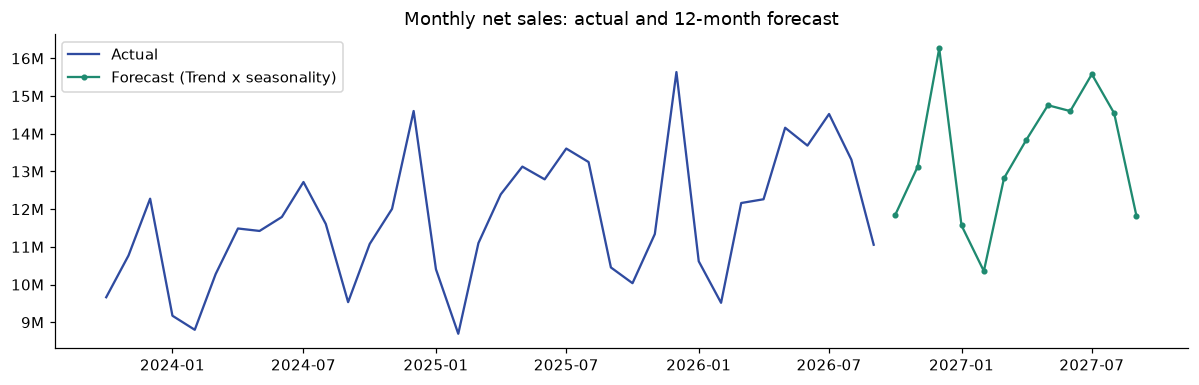

Base forecast next 12 months: 161,115,678 EGP vs last 12 months 148,305,944 EGP (+8.6%). Hold-out error of the selected model: 6.4% (WAPE).


In [92]:
# 10.5 Forecast next 12 months of net sales: pick the best of 4 models by a 12-month hold-out on the total series
ts = P.net_sales.values[None, :].astype(float); n_ = ts.shape[1]
res = {}
for name, fn in MODELS.items():
    fc12 = fn(ts[:, :n_ - 12], 12); res[name] = abs(ts[:, n_ - 12:] - fc12).sum() / ts[:, n_ - 12:].sum() * 100
bt12 = pd.Series(res).sort_values(); display(bt12.round(1).to_frame('hold-out WAPE % (last 12 months)'))
BEST12 = bt12.index[0]; fut = pd.date_range(P.index[-1] + pd.DateOffset(months=1), periods=12, freq='MS')
base_fc = pd.Series(MODELS[BEST12](ts, 12)[0], index=fut)
fy_last_sales = P.net_sales.iloc[-12:].sum(); growth_base = base_fc.sum() / fy_last_sales - 1
fig, ax = plt.subplots(figsize=(11, 3.6)); ax.plot(P.index, P.net_sales, color=BLUE, label='Actual'); ax.plot(base_fc.index, base_fc.values, color=GREEN, marker='o', ms=3, label=f'Forecast ({BEST12})')
ax.yaxis.set_major_formatter(mill); ax.legend(); ax.set_title('Monthly net sales: actual and 12-month forecast'); plt.tight_layout(); plt.show()
print(f'Base forecast next 12 months: {EG(base_fc.sum())} vs last 12 months {EG(fy_last_sales)} ({growth_base:+.1%}). Hold-out error of the selected model: {bt12.iloc[0]:.1f}% (WAPE).')

In [ ]:
# 10.6 Scenarios 
A = dict(opt_wholesale_cap=0.30, opt_cap_retention=0.90, opt_stockout_recovery=0.50, opt_copq_reduction=0.20, opt_marketing_loss_recovery=0.50,
         pess_demand_shock=-0.08, pess_margin_points=-1.0, pess_stockout_worsening=0.25)
margin_l = gp_l / s[s.FY == FYL].Net_Sales_EGP.sum(); g_scale = base_fc.sum() / s[s.FY == FYL].Net_Sales_EGP.sum()
lev = {
 'Wholesale discount cap': cap_gain(wh_l, A['opt_wholesale_cap'], A['opt_cap_retention']) * g_scale,
 'Stockout recovery': so12.lost_gp.sum() * A['opt_stockout_recovery'] * g_scale,
 'COPQ reduction (QC + rejects + rework)': (qc_l.Estimated_Loss_EGP.sum() + pr_l.scrap_cost.sum() + pb_l.Rework_Cost_EGP.sum()) * A['opt_copq_reduction'] * g_scale,
 'Marketing: cut loss-making campaigns': -mk_l[mk_l.contribution < 0].contribution.sum() * A['opt_marketing_loss_recovery'],
}
base_gp = base_fc.sum() * margin_l
opt_sales = base_fc.sum(); opt_gp = base_gp + sum(lev.values())
pes_sales = base_fc.sum() * (1 + A['pess_demand_shock']); pes_gp = pes_sales * (margin_l + A['pess_margin_points'] / 100) - so12.lost_gp.sum() * A['pess_stockout_worsening'] * g_scale
rr_sales = fy_last_sales * (1 + fy.loc[FYL, 'sales_growth_%'] / 100)
sc10 = pd.DataFrame({'Net sales (EGP)': [pes_sales, rr_sales, base_fc.sum(), opt_sales], 'Gross profit (EGP)': [pes_gp, rr_sales * margin_l, base_gp, opt_gp]}, index=['Pessimistic', f'Run-rate (FY growth stays at {fy.loc[FYL, "sales_growth_%"]:.1f}%)', 'Base (model)', 'Optimistic'])
sc10['Margin %'] = sc10['Gross profit (EGP)'] / sc10['Net sales (EGP)'] * 100; sc10['GP vs Base'] = sc10['Gross profit (EGP)'] - base_gp
display(sc10.style.format({'Net sales (EGP)': '{:,.0f}', 'Gross profit (EGP)': '{:,.0f}', 'Margin %': '{:.1f}', 'GP vs Base': '{:+,.0f}'}))
print('Optimistic levers:'); display(pd.Series(lev).round(0).to_frame('EGP gross profit'))
print('Assumptions:', A)

,Net sales (EGP),Gross profit (EGP),Margin %,GP vs Base
Pessimistic,"148,226,424","21,376,163",14.4,"-3,679,604"
Run-rate (FY growth stays at 3.3%),"153,264,204","23,834,752",15.6,"-1,221,015"
Base (model),"161,115,678","25,055,768",15.6,+0
Optimistic,"161,115,678","32,311,679",20.1,"+7,255,911"


Optimistic levers:


,EGP gross profit
Wholesale discount cap,4721259.0
Stockout recovery,385757.0
COPQ reduction (QC + rejects + rework),1532390.0
Marketing: cut loss-making campaigns,616505.0


Assumptions: {'opt_wholesale_cap': 0.3, 'opt_cap_retention': 0.9, 'opt_stockout_recovery': 0.5, 'opt_copq_reduction': 0.2, 'opt_marketing_loss_recovery': 0.5, 'pess_demand_shock': -0.08, 'pess_margin_points': -1.0, 'pess_stockout_worsening': 0.25}


In [ ]:
# 10.7 Quantified management action plant
plan_rows = [
 ('Cap wholesale discounts at 30% (90% volume retention)', 'Card 01/03', cap_gain(wh_l, 0.30, 0.90), 'Gross profit', 'Medium', True, 'Customers keep 90% of the volume that is re-priced'),
 ('Stop selling below cost (price floor at COGS)', 'Card 01', -s[(s.FY == FYL) & (s.Gross_Profit_EGP < 0)].Gross_Profit_EGP.sum(), 'Gross profit', 'High', False, 'Overlaps the discount cap: not added to the total'),
 ('Recover 50% of stockout lost gross profit (replenishment plan)', 'Card 04', so12.lost_gp.sum() * 0.5, 'Gross profit', 'Medium', True, 'Lost units are recoverable demand, not lost customers'),
 ('Cut or fix loss-making marketing campaigns (50% of their net loss)', 'Card 05', -mk_l[mk_l.contribution < 0].contribution.sum() * 0.5, 'Gross profit', 'Low', True, 'Attributed revenue is an upper bound: validate with a holdout test'),
 ('Relieve Sewing/Finishing bottlenecks (50% of their shortfall)', 'Card 06', pr_l[pr_l.Primary_Bottleneck.isin(['Sewing', 'Finishing'])].lost_gp_shortfall.sum() * 0.5, 'Gross profit', 'Medium', True, 'Shortfall units can be sold'),
 ('Reduce cost of poor quality by 20% (QC + rejects + rework)', 'Card 07/08', (qc_l.Estimated_Loss_EGP.sum() + pr_l.scrap_cost.sum() + pb_l.Rework_Cost_EGP.sum()) * 0.2, 'Cost saving', 'Medium', True, 'Depends on the reject-loss share assumption in Card 06'),
 ('Win back 15% of lapsed B2C customers', 'Card 02', lapsed_val.gp.sum() / yrs * 0.15, 'Gross profit', 'Medium', True, 'Consent-based outreach to the saved win-back list'),
 ('Fix size charts: cut Size/fit refunds by 30%', 'Card 07', s[(s.FY == FYL) & (s.Return_Reason == 'Size / fit')].Refund_Value_EGP.sum() * 0.3, 'Revenue protected', 'Medium', False, 'Refund value, not profit: not added'),
 ('Release 30% of excess stock cash (sell-through / promote)', 'Card 04', last.excess_cash.sum() * 0.3, 'One-off cash', 'Medium', False, 'Balance-sheet effect, not P&L'),
 ('Move volume away from the 2 late suppliers', 'Card 09', 0.0, 'Operational (risk)', 'High', False, 'Avoids late POs; its EGP value is quantified by the Risk Radar in Part C'),
]
act10 = pd.DataFrame(plan_rows, columns=['action', 'card', 'annual_impact_EGP', 'impact_type', 'confidence', 'additive', 'key_assumption']).sort_values('annual_impact_EGP', ascending=False)
act10.to_csv(os.path.join(OUT_DIR, 'management_action_plan.csv'), index=False)
display(act10.style.format({'annual_impact_EGP': '{:,.0f}'}))
tot_add = act10[act10.additive].annual_impact_EGP.sum()
print(f'Additive profit impact of the plan: {EG(tot_add)} per year = {tot_add/gp_l:.0%} of {FYL} gross profit.')

,action,card,annual_impact_EGP,impact_type,confidence,additive,key_assumption
0,Cap wholesale discounts at 30% (90% volume retention),Card 01/03,"4,345,888",Gross profit,Medium,True,Customers keep 90% of the volume that is re-priced
8,Release 30% of excess stock cash (sell-through / promote),Card 04,"2,187,842",One-off cash,Medium,False,"Balance-sheet effect, not P&L"
5,Reduce cost of poor quality by 20% (QC + rejects + rework),Card 07/08,"1,410,555",Cost saving,Medium,True,Depends on the reject-loss share assumption in Card 06
3,Cut or fix loss-making marketing campaigns (50% of their net loss),Card 05,"616,505",Gross profit,Low,True,Attributed revenue is an upper bound: validate with a holdout test
1,Stop selling below cost (price floor at COGS),Card 01,"447,199",Gross profit,High,False,Overlaps the discount cap: not added to the total
2,Recover 50% of stockout lost gross profit (replenishment plan),Card 04,"355,087",Gross profit,Medium,True,"Lost units are recoverable demand, not lost customers"
6,Win back 15% of lapsed B2C customers,Card 02,"338,490",Gross profit,Medium,True,Consent-based outreach to the saved win-back list
7,Fix size charts: cut Size/fit refunds by 30%,Card 07,"337,893",Revenue protected,Medium,False,"Refund value, not profit: not added"
4,Relieve Sewing/Finishing bottlenecks (50% of their shortfall),Card 06,"179,906",Gross profit,Medium,True,Shortfall units can be sold
9,Move volume away from the 2 late suppliers,Card 09,0,Operational (risk),High,False,Avoids late POs; its EGP value is quantified by the Risk Radar in Part C


Additive profit impact of the plan: 7,246,431 EGP per year = 31% of FY26 gross profit.


In [ ]:
# 10.8 KEY TAKEAWAYS (computed)
ch_n = s.groupby('Channel').Net_Sales_EGP.sum(); ch_g = s.groupby('Channel').Gross_Profit_EGP.sum()
print(f'DEMAND   : {FYL} net sales {M(s[s.FY == FYL].Net_Sales_EGP.sum())} EGP ({fy.loc[FYL, "sales_growth_%"]:+.1f}% growth, down from {fy.loc[PREV_FY, "sales_growth_%"]:+.1f}%); Wholesale = {ch_n["Wholesale"]/ch_n.sum():.0%} of sales at {ch_g["Wholesale"]/ch_n["Wholesale"]:.1%} margin; {FYL} growth by channel: ' + ', '.join(f'{k} {v:+.1f}%' for k, v in ch[f'growth_{FYL}_%'].items()) + '.')
print(f'CUSTOMERS: {len(rc):,} B2C customers, {rc.is_repeat.mean():.0%} repeat; {len(win):,} reachable lapsed customers; acquisition source does not change customer value.')
print(f'MARKETING: only {pv_[pv_.contribution > 0].index.tolist()} create profit; {int((mk.contribution < 0).sum())} of {len(mk)} campaigns lose money after margin.')
print(f'SUPPLY   : OTIF {po.OTIF.mean():.0%}; {", ".join(bad_s)} drive {late_bad/(~po.on_time).sum():.0%} of late POs; lead-time master data is wrong for most materials.')
print(f'FACTORY  : {pr.delayed.mean():.0%} orders late, all with a bottleneck ({bn.index[0]} first); output = {tot.Produced_Qty/tot.Planned_Qty:.0%} of plan; modelled load {daily.mean()/CAP_DAY:.0%} of stated capacity.')
print(f'QUALITY  : COPQ {EG(copq.sum())}; top refund reason is Size / fit (not a QC problem).')
so_wh = so12.groupby('Channel').lost_gp.sum(); ex_dir = last[last.Channel != 'Wholesale'].excess_cash.sum()
print(f'INVENTORY: stockouts cost {EG(so12.lost_gp.sum())} gross profit ({so_wh.max()/so_wh.sum():.0%} in {so_wh.idxmax()}) while {EG(last.excess_cash.sum())} of cash sits in overstock, {EG(ex_dir)} of it in Retail/Online locations.')
print(f'SERVICE  : CSAT {cs.CSAT_1_to_5.mean():.2f}/5; resolved tickets {cs[cs.Resolved == "Yes"].CSAT_1_to_5.mean():.2f} vs unresolved {cs[cs.Resolved == "No"].CSAT_1_to_5.mean():.2f}: closing the {(cs.Resolved == "No").mean():.0%} open tickets is a cheap CSAT lever.')
print(f'FORECAST : next 12 months net sales {EG(base_fc.sum())} ({growth_base:+.1%} model; run-rate case {EG(rr_sales)}, the model extrapolates the long-run trend while {FYL} growth slowed); GP range {M(pes_gp)} (pessimistic) to {M(opt_gp)} (optimistic) EGP.')
print(f'ACTIONS  : additive plan = {EG(tot_add)} per year ({tot_add/gp_l:.0%} of gross profit).')

DEMAND   : FY26 net sales 148.31M EGP (+3.3% growth, down from +10.8%); Wholesale = 85% of sales at 11.9% margin; FY26 growth by channel: Online +26.1%, Retail -6.8%, Wholesale +2.2%.
CUSTOMERS: 24,035 B2C customers, 84% repeat; 3,574 reachable lapsed customers; acquisition source does not change customer value.
MARKETING: only ['Google', 'WhatsApp / CRM'] create profit; 261 of 420 campaigns lose money after margin.
SUPPLY   : OTIF 56%; SUP09, SUP04 drive 29% of late POs; lead-time master data is wrong for most materials.
FACTORY  : 16% orders late, all with a bottleneck (Sewing first); output = 91% of plan; modelled load 114% of stated capacity.
QUALITY  : COPQ 24,100,021 EGP; top refund reason is Size / fit (not a QC problem).
INVENTORY: stockouts cost 710,174 EGP gross profit (97% in Wholesale) while 7,292,806 EGP of cash sits in overstock, 5,493,775 EGP of it in Retail/Online locations.
SERVICE  : CSAT 4.00/5; resolved tickets 4.08 vs unresolved 2.32: closing the 5% open tickets is

---
## The Demand-to-Supply Risk Radar

In [ ]:
# 1. Assumptions
AS_OF = DATA_END + pd.Timedelta(days=1)          # planning date = day after the last data day
PROD_CYCLE_DAYS = int(round(pr.cycle_days.mean()))   # average production cycle: materials must be on site this many days before the sales month starts
HANDLING_DAYS = 3                                 # receiving / put-away buffer
YIELD_LOSS = pr.Rejected_Qty.sum() / pr.Produced_Qty.sum()   # production reject rate: extra material needed per good unit
RECENT = po[po.Order_Date > DATA_END - pd.DateOffset(months=12)].copy()   # supplier behaviour from the latest 12 months
ON_HAND = {}                                      # e.g. {'M001': 12000.0} raw-material stock in the material's unit; empty = assume none
print(f'As of {AS_OF.date()} | production cycle {PROD_CYCLE_DAYS} days + {HANDLING_DAYS} days handling | yield loss {YIELD_LOSS:.2%} | supplier behaviour from {len(RECENT):,} POs of the last 12 months')

As of 2026-10-01 | production cycle 17 days + 3 days handling | yield loss 2.49% | supplier behaviour from 1,195 POs of the last 12 months


In [ ]:
# 2. Demand forecast -> material requirement
mcols = list(fut_months)
fc_prod = fdf[mcols].groupby(level='Product_ID').sum()                      # forecast units by product and month (all locations)
req = bom.merge(fc_prod.reset_index(), on='Product_ID')
for c in mcols: req[c] = req[c] * req.Required_Per_Unit / (1 - YIELD_LOSS)   # add the yield loss
mat_req = req.groupby('Material_ID')[mcols].sum().reindex(mat.index).fillna(0)
mat_req.columns = [c.strftime('%b %Y') for c in mcols]; mat_req['total_90d'] = mat_req.sum(axis=1)
display(mat_req.join(mat[['Material_Name', 'Unit']]).round(0))
print(f'Forecast units next 90 days (all products): {fc_prod.sum().sum():,.0f} -> material requirement computed for {int((mat_req.total_90d > 0).sum())} of {len(mat)} materials (the other {int((mat_req.total_90d == 0).sum())} are not in any BOM).')

,Oct 2026,Nov 2026,Dec 2026,total_90d,Material_Name,Unit
Material_ID,,,,,,
M001,9676.0,10973.0,12646.0,33295.0,Single Jersey Cotton 160 GSM,meter
M002,7839.0,8707.0,11149.0,27694.0,Single Jersey Cotton 180 GSM,meter
M003,8709.0,8605.0,11226.0,28540.0,Rib Cotton,meter
M004,6062.0,6864.0,8677.0,21602.0,Summer Melton,meter
M005,0.0,0.0,0.0,0.0,Elastic Band,meter
M006,967.0,1046.0,1288.0,3302.0,Sewing Thread,cone
M007,39282.0,42473.0,52385.0,134141.0,Neck Label,piece
M008,39282.0,42473.0,52385.0,134141.0,Care Label,piece
M009,39282.0,42473.0,52385.0,134141.0,Poly Bag,piece


Forecast units next 90 days (all products): 130,797 -> material requirement computed for 10 of 12 materials (the other 2 are not in any BOM).


In [ ]:
# 3. Real lead-time behaviour vs the master-data lead time, per material
lt = RECENT.groupby('Material_ID').agg(pos=('PO_ID', 'count'), lead_p50=('lead_actual', lambda x: x.quantile(.5)), lead_p90=('lead_actual', lambda x: x.quantile(.9)),
        late_rate=('on_time', lambda x: 1 - x.mean()), delay_when_late=('delay_days', lambda x: x[x > 0].mean()), delay_p90=('delay_days', lambda x: x.quantile(.9)), reject_rate=('Rejected_Qty', 'sum'))
lt['reject_rate'] = lt.reject_rate / RECENT.groupby('Material_ID').Ordered_Qty.sum()
lt = lt.join(mat[['Material_Name', 'Material_Category', 'Standard_Lead_Time_Days']])
lt['gap_p90_vs_standard'] = lt.lead_p90 - lt.Standard_Lead_Time_Days
display(lt[['Material_Name', 'Standard_Lead_Time_Days', 'lead_p50', 'lead_p90', 'gap_p90_vs_standard', 'late_rate', 'delay_when_late', 'reject_rate']].round(2))

,Material_Name,Standard_Lead_Time_Days,lead_p50,lead_p90,gap_p90_vs_standard,late_rate,delay_when_late,reject_rate
Material_ID,,,,,,,,
M001,Single Jersey Cotton 160 GSM,10,10.0,21.0,11.0,0.38,3.36,0.02
M002,Single Jersey Cotton 180 GSM,14,10.0,21.0,7.0,0.37,3.56,0.02
M003,Rib Cotton,10,10.0,22.0,12.0,0.36,3.11,0.02
M004,Summer Melton,10,11.0,22.4,12.4,0.40,2.70,0.02
M005,Elastic Band,7,11.0,21.0,14.0,0.29,3.71,0.02
M006,Sewing Thread,14,12.0,21.0,7.0,0.44,3.71,0.02
M007,Neck Label,7,12.0,21.0,14.0,0.41,2.73,0.02
M008,Care Label,14,11.0,21.0,7.0,0.26,3.95,0.02
M009,Poly Bag,7,10.0,21.0,14.0,0.39,3.33,0.02


In [ ]:
# 4. Gross profit exposed to each material (EGP per day of delay)
gpu = unit_econ.gp_per_unit
daily_units = fc_prod.sum(axis=1) / 90                                        # forecast units per day by product
exp_ = bom.assign(du=bom.Product_ID.map(daily_units), gpu=bom.Product_ID.map(gpu))
exp_['gp_per_day'] = exp_.du * exp_.gpu
exposure = exp_.groupby('Material_ID').agg(products=('Product_ID', 'nunique'), units_per_day=('du', 'sum'), gp_per_day_at_stake=('gp_per_day', 'sum'))
radar = lt.join(exposure).fillna({'products': 0, 'units_per_day': 0, 'gp_per_day_at_stake': 0})
# risk score = chance the delivery is late x delay when late x GP that stops for each day of delay = expected GP at risk per delivery
radar['expected_delay_days'] = radar.late_rate * radar.delay_when_late.fillna(0)
radar['expected_GP_at_risk_per_PO'] = radar.expected_delay_days * radar.gp_per_day_at_stake
radar['worst_case_GP_at_risk'] = radar.delay_p90.clip(lower=0) * radar.gp_per_day_at_stake      # if the delivery is as late as the 90th percentile
q75, q50 = radar.expected_GP_at_risk_per_PO.quantile(.75), radar.expected_GP_at_risk_per_PO.quantile(.5)
radar['tier'] = np.where(radar.gp_per_day_at_stake == 0, 'n/a (not in BOM)', np.where(radar.expected_GP_at_risk_per_PO >= q75, 'RED', np.where(radar.expected_GP_at_risk_per_PO >= q50, 'AMBER', 'GREEN')))
def advice(r):
    if r.tier.startswith('n/a'): return 'Add to BOM or stop buying'
    if r.tier == 'RED': return 'Order earliest, add safety stock, shift volume to the reliable suppliers, expedite clause'
    if r.tier == 'AMBER': return 'Order at the p90 lead time; monitor weekly'
    return 'Standard ordering'
radar['recommended_action'] = radar.apply(advice, axis=1)
show = radar.sort_values('expected_GP_at_risk_per_PO', ascending=False)[['Material_Name', 'products', 'gp_per_day_at_stake', 'late_rate', 'delay_when_late', 'delay_p90', 'expected_GP_at_risk_per_PO', 'worst_case_GP_at_risk', 'tier', 'recommended_action']]
display(show.round(2))
radar.reset_index().to_csv(os.path.join(OUT_DIR, 'radar_material_risk.csv'), index=False)

,Material_Name,products,gp_per_day_at_stake,late_rate,delay_when_late,delay_p90,expected_GP_at_risk_per_PO,worst_case_GP_at_risk,tier,recommended_action
Material_ID,,,,,,,,,,
M006,Sewing Thread,59.0,58334.10,0.44,3.71,5.0,95341.75,291670.48,RED,"Order earliest, add safety stock, shift volume to the reliable suppliers, expedite clause"
M009,Poly Bag,59.0,58334.10,0.39,3.33,3.0,76600.33,175002.29,RED,"Order earliest, add safety stock, shift volume to the reliable suppliers, expedite clause"
M007,Neck Label,59.0,58334.10,0.41,2.73,2.2,65994.13,128335.01,RED,"Order earliest, add safety stock, shift volume to the reliable suppliers, expedite clause"
M008,Care Label,59.0,58334.10,0.26,3.95,3.0,60417.46,175002.29,AMBER,Order at the p90 lead time; monitor weekly
M011,Water-Based Ink,25.0,18708.30,0.34,4.77,5.0,30764.77,93541.52,AMBER,Order at the p90 lead time; monitor weekly
M001,Single Jersey Cotton 160 GSM,15.0,18543.80,0.38,3.36,4.4,23870.21,81592.70,AMBER,Order at the p90 lead time; monitor weekly
M002,Single Jersey Cotton 180 GSM,15.0,16619.13,0.37,3.56,3.0,21732.71,49857.40,GREEN,Standard ordering
M012,Heat Transfer Film,17.0,13590.28,0.43,3.22,3.0,18835.66,40770.85,GREEN,Standard ordering
M003,Rib Cotton,16.0,12482.57,0.36,3.11,3.0,14073.49,37447.72,GREEN,Standard ordering


In [ ]:
# 5. Risk-adjusted order calendar
sup_pick = pair[pair.pos >= 5].sort_values(['Material_ID', 'OTIF', 'delay_p90'], ascending=[True, False, True]).drop_duplicates('Material_ID').set_index('Material_ID')   # most reliable supplier per material
rows = []
for m in mat_req.index:
    if mat_req.loc[m, 'total_90d'] <= 0: continue
    for c, mo in zip(mat_req.columns[:3], mcols):
        need_by = mo - pd.Timedelta(days=PROD_CYCLE_DAYS + HANDLING_DAYS)
        std_by = need_by - pd.Timedelta(days=int(mat.loc[m, 'Standard_Lead_Time_Days']))
        risk_by = need_by - pd.Timedelta(days=int(np.ceil(radar.loc[m, 'lead_p90'])))
        acc = 1 - radar.loc[m, 'reject_rate']; qty = max(0, mat_req.loc[m, c] / acc - ON_HAND.get(m, 0) if c == mat_req.columns[0] else mat_req.loc[m, c] / acc)
        rows.append({'Material_ID': m, 'Material_Name': mat.loc[m, 'Material_Name'], 'for_month': c, 'qty_to_order': qty, 'unit': mat.loc[m, 'Unit'], 'need_on_site_by': need_by.date(),
                     'order_by_master_data_lead': std_by.date(), 'order_by_risk_adjusted_p90': risk_by.date(), 'days_earlier_than_master_data': (std_by - risk_by).days,
                     'recommended_supplier': sup_pick.Supplier_ID.get(m, 'n/a'), 'status': 'ORDER NOW / EXPEDITE' if risk_by < AS_OF else 'Scheduled', 'tier': radar.loc[m, 'tier']})
cal = pd.DataFrame(rows)
cal.to_csv(os.path.join(OUT_DIR, 'po_calendar_next_90d.csv'), index=False)
print(cal.groupby('for_month').status.value_counts().unstack().fillna(0).astype(int).to_string())
display(cal[cal.for_month == mat_req.columns[0]].sort_values('qty_to_order', ascending=False).round(0).head(12))

status     ORDER NOW / EXPEDITE  Scheduled
for_month                                 
Dec 2026                      0         10
Nov 2026                     10          0
Oct 2026                     10          0


,Material_ID,Material_Name,for_month,qty_to_order,unit,need_on_site_by,order_by_master_data_lead,order_by_risk_adjusted_p90,days_earlier_than_master_data,recommended_supplier,status,tier
18,M008,Care Label,Oct 2026,40046.0,piece,2026-09-11,2026-08-28,2026-08-21,7,SUP02,ORDER NOW / EXPEDITE,AMBER
21,M009,Poly Bag,Oct 2026,39968.0,piece,2026-09-11,2026-09-04,2026-08-21,14,SUP02,ORDER NOW / EXPEDITE,RED
15,M007,Neck Label,Oct 2026,39957.0,piece,2026-09-11,2026-09-04,2026-08-21,14,SUP03,ORDER NOW / EXPEDITE,RED
0,M001,Single Jersey Cotton 160 GSM,Oct 2026,9846.0,meter,2026-09-11,2026-09-01,2026-08-21,11,SUP03,ORDER NOW / EXPEDITE,AMBER
6,M003,Rib Cotton,Oct 2026,8877.0,meter,2026-09-11,2026-09-01,2026-08-20,12,SUP01,ORDER NOW / EXPEDITE,GREEN
3,M002,Single Jersey Cotton 180 GSM,Oct 2026,7962.0,meter,2026-09-11,2026-08-28,2026-08-21,7,SUP06,ORDER NOW / EXPEDITE,GREEN
9,M004,Summer Melton,Oct 2026,6161.0,meter,2026-09-11,2026-09-01,2026-08-19,13,SUP03,ORDER NOW / EXPEDITE,GREEN
12,M006,Sewing Thread,Oct 2026,985.0,cone,2026-09-11,2026-08-28,2026-08-21,7,SUP01,ORDER NOW / EXPEDITE,RED
27,M012,Heat Transfer Film,Oct 2026,486.0,sheet,2026-09-11,2026-09-04,2026-08-23,12,SUP06,ORDER NOW / EXPEDITE,GREEN
24,M011,Water-Based Ink,Oct 2026,442.0,kg,2026-09-11,2026-08-21,2026-08-21,0,SUP06,ORDER NOW / EXPEDITE,AMBER


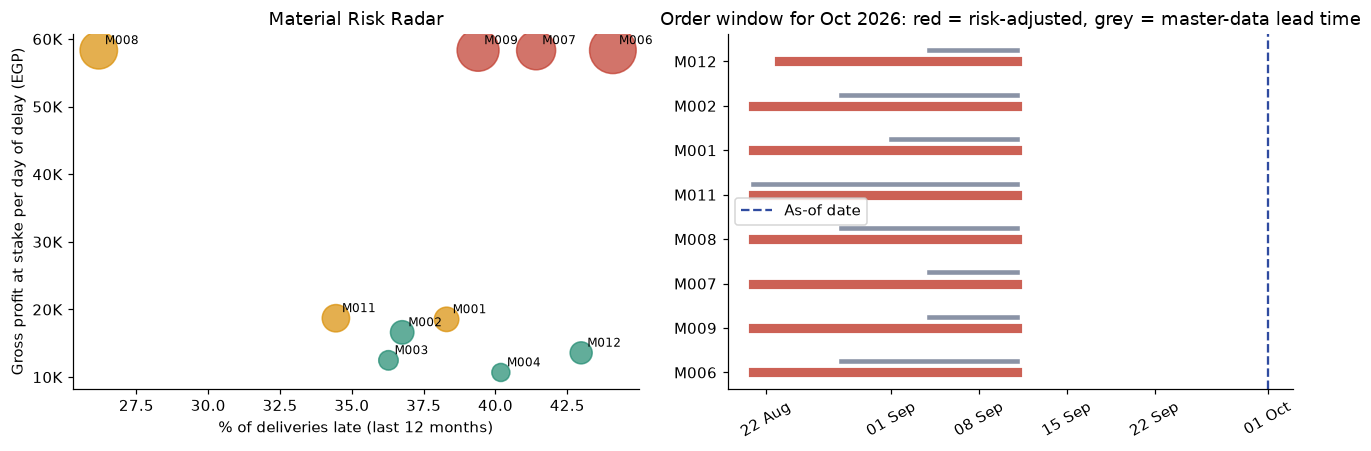

In [ ]:
# 6. The Radar picture
r_ = radar[radar.gp_per_day_at_stake > 0].copy()
colors = {'RED': RED, 'AMBER': AMBER, 'GREEN': GREEN}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(r_.late_rate * 100, r_.gp_per_day_at_stake, s=r_.expected_GP_at_risk_per_PO / r_.expected_GP_at_risk_per_PO.max() * 900 + 30, c=[colors[t] for t in r_.tier], alpha=.7)
for m, row in r_.iterrows(): ax[0].annotate(m, (row.late_rate * 100, row.gp_per_day_at_stake), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax[0].set_xlabel('% of deliveries late (last 12 months)'); ax[0].set_ylabel('Gross profit at stake per day of delay (EGP)'); ax[0].set_title('Material Risk Radar'); ax[0].yaxis.set_major_formatter(mill)
top8 = cal[cal.for_month == mat_req.columns[0]].merge(radar.expected_GP_at_risk_per_PO.reset_index(), on='Material_ID').sort_values('expected_GP_at_risk_per_PO', ascending=False).head(8)
for i, r in enumerate(top8.itertuples()):
    ax[1].plot([pd.Timestamp(r.order_by_risk_adjusted_p90), pd.Timestamp(r.need_on_site_by)], [i, i], color=RED, lw=6, alpha=.8)
    ax[1].plot([pd.Timestamp(r.order_by_master_data_lead), pd.Timestamp(r.need_on_site_by)], [i + .25, i + .25], color=GREY, lw=3)
ax[1].set_yticks(range(len(top8))); ax[1].set_yticklabels(top8.Material_ID); ax[1].axvline(AS_OF, color=BLUE, ls='--', label='As-of date'); ax[1].legend()
ax[1].set_title(f'Order window for {mat_req.columns[0]}: red = risk-adjusted, grey = master-data lead time'); ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b')); plt.setp(ax[1].get_xticklabels(), rotation=30)
plt.tight_layout(); plt.show()

**Test design:** learn each supplier-material pair's lateness and 90th-percentile lead time from purchase orders placed **before Oct 2025**, then check them against purchase orders placed **from Oct 2025 onward**. And compare against the status quo (master-data lead time).

Train POs: 2,405 | test POs (never seen): 1,195
Share of NEW purchase orders that arrive within the planned lead time: master data 51% | Radar p50 53% | Radar p90 93% (the p90 target is about 90%).
Rank correlation of lateness, train vs test: supplier-material pairs +0.34 (n=141), suppliers +0.29 (n=12). Two worst suppliers in train: ['SUP09', 'SUP04'] | in test: ['SUP09', 'SUP04'].


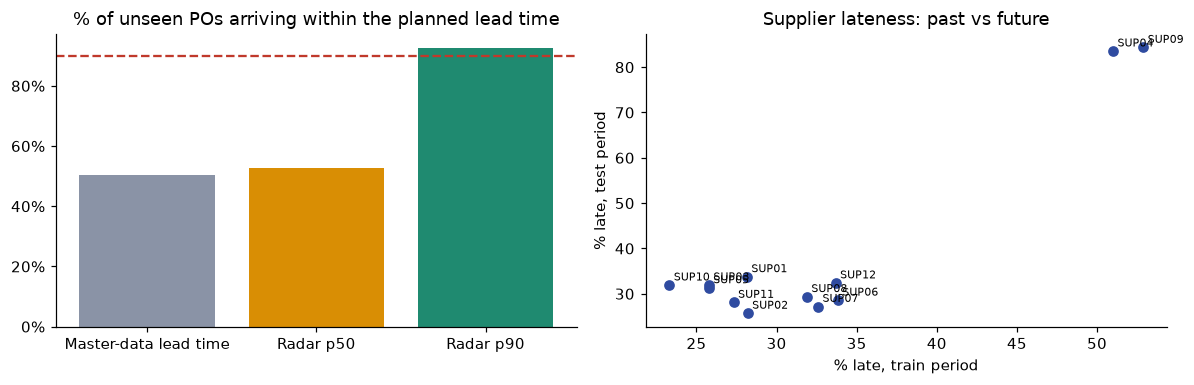

In [ ]:
# 7.1. Out-of-sample proof
CUT = pd.Timestamp('2025-10-01')
tr, te = po[po.Order_Date < CUT], po[po.Order_Date >= CUT]
std_lt = te.Material_ID.map(mat.Standard_Lead_Time_Days)
p90_mat = tr.groupby('Material_ID').lead_actual.quantile(.9); p50_mat = tr.groupby('Material_ID').lead_actual.median()
cov_std = (te.lead_actual <= std_lt).mean()                                           # share of new POs that arrive within the master-data lead time
cov_p90 = (te.lead_actual <= te.Material_ID.map(p90_mat)).mean()                      # share that arrive within the Radar's p90 lead time
cov_p50 = (te.lead_actual <= te.Material_ID.map(p50_mat)).mean()
print(f'Train POs: {len(tr):,} | test POs (never seen): {len(te):,}')
print(f'Share of NEW purchase orders that arrive within the planned lead time: master data {cov_std:.0%} | Radar p50 {cov_p50:.0%} | Radar p90 {cov_p90:.0%} (the p90 target is about 90%).')
# supplier-material pairs: does last period's lateness rank predict next period's?
a = tr.groupby(['Material_ID', 'Supplier_ID']).agg(n_tr=('PO_ID', 'count'), late_tr=('on_time', lambda x: 1 - x.mean()))
b = te.groupby(['Material_ID', 'Supplier_ID']).agg(n_te=('PO_ID', 'count'), late_te=('on_time', lambda x: 1 - x.mean()))
pp_ = a.join(b, how='inner'); pp_ = pp_[(pp_.n_tr >= 5) & (pp_.n_te >= 3)]
sp = pp_.late_tr.rank().corr(pp_.late_te.rank())            # Spearman = Pearson on ranks (no scipy needed)
sup_tr = tr.groupby('Supplier_ID').on_time.apply(lambda x: 1 - x.mean()); sup_te = te.groupby('Supplier_ID').on_time.apply(lambda x: 1 - x.mean())
sp_s = sup_tr.rank().corr(sup_te.reindex(sup_tr.index).rank()); worst_tr = sup_tr.sort_values(ascending=False).head(2).index.tolist(); worst_te = sup_te.sort_values(ascending=False).head(2).index.tolist()
print(f'Rank correlation of lateness, train vs test: supplier-material pairs {sp:+.2f} (n={len(pp_)}), suppliers {sp_s:+.2f} (n={len(sup_tr)}). Two worst suppliers in train: {worst_tr} | in test: {worst_te}.')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(['Master-data lead time', 'Radar p50', 'Radar p90'], [cov_std * 100, cov_p50 * 100, cov_p90 * 100], color=[GREY, AMBER, GREEN]); ax[0].axhline(90, color=RED, ls='--'); ax[0].set_title('% of unseen POs arriving within the planned lead time'); ax[0].yaxis.set_major_formatter(pct_fmt)
ax[1].scatter(sup_tr * 100, sup_te.reindex(sup_tr.index) * 100, color=BLUE)
for sid in sup_tr.index: ax[1].annotate(sid, (sup_tr[sid] * 100, sup_te[sid] * 100), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax[1].set_xlabel('% late, train period'); ax[1].set_ylabel('% late, test period'); ax[1].set_title('Supplier lateness: past vs future'); plt.tight_layout(); plt.show()

In [ ]:
# 7.2. Compare reliable suppliers with the two outliers 
rel_tr, rel_te = tr[~tr.Supplier_ID.isin(bad_s)], te[~te.Supplier_ID.isin(bad_s)]; out_te = te[te.Supplier_ID.isin(bad_s)]
p90_rel = rel_tr.groupby('Material_ID').lead_actual.quantile(.9)
within = lambda d: (d.lead_actual <= d.Material_ID.map(mat.Standard_Lead_Time_Days)).mean()
print(f'Average p90 lead time per material (train): all suppliers {p90_mat.mean():.1f} days | reliable suppliers only {p90_rel.mean():.1f} days.')
print(f'Share of unseen POs arriving within the master-data lead time: reliable suppliers {within(rel_te):.0%} | outlier suppliers {within(out_te):.0%}.')
print(f'Reading: moving volume to reliable suppliers lifts the share of POs that meet the planned lead time ({within(rel_te):.0%} vs {within(out_te):.0%}), but it does NOT shorten the 90th-percentile lead time ({p90_rel.mean():.1f} vs {p90_mat.mean():.1f} days). The long tail is a property of the whole supply base, so the earlier order dates in the Radar are needed whichever supplier is chosen; supplier reallocation reduces the frequency of late deliveries, not the planning lead time.')

Average p90 lead time per material (train): all suppliers 21.1 days | reliable suppliers only 21.0 days.
Share of unseen POs arriving within the master-data lead time: reliable suppliers 54% | outlier suppliers 31%.
Reading: moving volume to reliable suppliers lifts the share of POs that meet the planned lead time (54% vs 31%), but it does NOT shorten the 90th-percentile lead time (21.0 vs 21.1 days). The long tail is a property of the whole supply base, so the earlier order dates in the Radar are needed whichever supplier is chosen; supplier reallocation reduces the frequency of late deliveries, not the planning lead time.


### PITCH: the value story, with the numbers computed from the Radar

In [110]:
# 8. Value of the Radar and the pitch script
red = radar[radar.tier == 'RED']
cap90 = fc_prod.sum().sum() * unit_econ.gp_per_unit.mean()                                 # sanity cap: total 90-day forecast gross profit
exposure_red = min(red.worst_case_GP_at_risk.sum(), cap90)
days_early = cal[cal.for_month == mat_req.columns[0]].days_earlier_than_master_data
now_n = int((cal.status == 'ORDER NOW / EXPEDITE').sum())
fwd = cal[cal.for_month == mat_req.columns[0]]
print('=== 5-SLIDE PITCH ===')
print(f'1. THE PROBLEM    : Purchasing plans with master-data lead times, but only {cov_std:.0%} of new purchase orders actually arrive within them; {1 - po.OTIF.mean():.0%} of POs fail on time-in-full.')
print(f'2. THE HIDDEN LINK: nobody joins forecast -> BOM -> supplier behaviour. The Radar does, for {int((mat_req.total_90d > 0).sum())} materials and {len(bom.Product_ID.unique())} products.')
print(f'3. WHAT IT SAYS   : {len(red)} RED materials ({", ".join(red.index)}) put up to {EG(exposure_red)} of the next 90 days of gross profit at stake if deliveries run as late as their p90; {now_n} order lines for the next 3 months are already inside their lead time and must be expedited today.')
same_worst = set(worst_tr) == set(worst_te)
print(f'4. PROOF          : on 12 months of purchase orders it never saw, the risk-adjusted lead time is met {cov_p90:.0%} of the time vs {cov_std:.0%} for master data; {"the same two suppliers (" + ", ".join(worst_tr) + ") are the worst in both periods" if same_worst else "the worst suppliers change between periods"} (supplier rank correlation {sp_s:+.2f}).')
print(f'5. THE ASK        : (a) load the Radar calendar into purchasing, ordering about {days_early.mean():.1f} days earlier on average than master data; (b) move volume off {", ".join(bad_s)} (they cause {late_bad/(~po.on_time).sum():.0%} of late POs; only {within(out_te):.0%} of their new POs meet the planned lead time vs {within(rel_te):.0%} for the others); (c) correct the lead-time master data; (d) feed real raw-material stock into ON_HAND to turn the calendar into exact order quantities.')

=== 5-SLIDE PITCH ===
1. THE PROBLEM    : Purchasing plans with master-data lead times, but only 51% of new purchase orders actually arrive within them; 44% of POs fail on time-in-full.
2. THE HIDDEN LINK: nobody joins forecast -> BOM -> supplier behaviour. The Radar does, for 10 materials and 59 products.
3. WHAT IT SAYS   : 3 RED materials (M006, M007, M009) put up to 595,008 EGP of the next 90 days of gross profit at stake if deliveries run as late as their p90; 20 order lines for the next 3 months are already inside their lead time and must be expedited today.
4. PROOF          : on 12 months of purchase orders it never saw, the risk-adjusted lead time is met 93% of the time vs 51% for master data; the same two suppliers (SUP09, SUP04) are the worst in both periods (supplier rank correlation +0.29).
5. THE ASK        : (a) load the Radar calendar into purchasing, ordering about 9.7 days earlier on average than master data; (b) move volume off SUP09, SUP04 (they cause 29% of late PO

---
# CLOSING PACK

In [ ]:
# 1. Data coverage
use = {'Sales_Transactions': 'Cards 01, 02, 03, 04, 10', 'Customers': 'Card 02, 03', 'Product_Master': 'Cards 01, 05, 07', 'Inventory_History': 'Card 04', 'Locations': 'Cards 03, 04', 'Marketing': 'Card 05',
       'Web_Traffic_Daily': 'Cards 05, 10', 'Customer_Service': 'Card 10', 'Production_Orders': 'Cards 06, 07, 10', 'Printing_Batches': 'Cards 07, 08', 'Machine_Downtime': 'Cards 06, 08, 10',
       'Quality': 'Cards 07, 10', 'Purchase_Orders': 'Cards 09, 10, Radar', 'Suppliers': 'Card 09', 'Materials': 'Card 09, Radar', 'Product_BOM': 'Card 09, Radar', 'Group_Operations': 'Card 10',
       'Business_Units': 'Card 06 (public capacity)', 'Case_Briefs': 'Scope of all cards', 'Data_Dictionary': 'Phase 0'}
cov = pd.DataFrame({'used_in': pd.Series(use)}); cov['rows'] = pd.Series({k: len(v) for k, v in raw.items()}); cov['used'] = np.where(cov.used_in.notna(), 'yes', 'NO'); display(cov)

,used_in,rows,used
Sales_Transactions,"Cards 01, 02, 03, 04, 10",180000,yes
Customers,"Card 02, 03",30000,yes
Product_Master,"Cards 01, 05, 07",59,yes
Inventory_History,Card 04,6372,yes
Locations,"Cards 03, 04",5,yes
Marketing,Card 05,420,yes
Web_Traffic_Daily,"Cards 05, 10",1096,yes
Customer_Service,Card 10,6500,yes
Production_Orders,"Cards 06, 07, 10",2500,yes
Printing_Batches,"Cards 07, 08",1900,yes


In [ ]:
# 2. Final assumptions and data limitations register
final = pd.DataFrame([
 ['Data nature', 'Most tables are modelled / synthetic training data anchored to public products and prices. Findings show how to analyse the business; absolute EGP values are illustrative.'],
 ['Fiscal year', 'FY = October to September. The data covers exactly 3 FYs (FY24 to FY26).'],
 ['Gross profit', 'Net sales minus estimated COGS. No other costs exist in the data.'],
 ['Channel vs customer type', 'FY24 has 15.5M EGP of Wholesale-channel sales to Retail-type customers (none afterwards). Channel analysis keeps Channel as recorded; customer analysis uses Customer_Type.'],
 ['One line per invoice', 'Invoice_ID is unique per row, so AOV = net sales per invoice and basket = units per invoice.'],
 ['Refunds', 'Treated as an upper-bound exposure: assumes refunded goods cannot be resold.'],
 ['Marketing attribution', 'Attributed revenue exceeds direct sales several times over: ROAS values are upper bounds and need a holdout test. CAC = cost per attributed order (no new-customer flag).'],
 ['Production vs sales scale', 'Production orders cover ~3.8x the units in the sales data; production-based EGP values are scaled (SCALE_PROD) and the reject loss share is an explicit parameter (REJECT_LOSS_SHARE).'],
 ['Purchase-order scale', 'PO spend is ~2.5x total COGS: POs are used for supplier behaviour only, never for volumes.'],
 ['Forecast', 'Four models back-tested on rolling origins; the best is used. No external drivers (price, promotions, weather).'],
 ['No raw-material stock / open POs', 'The Radar computes requirements and order-by dates; ON_HAND lets you plug in real stock.'],
 ['Thresholds', 'Lapse 180 days; XYZ CV 0.5/0.7; overstock 120 days of cover; in-full 97%; supplier Poor rule in Card 09; RFM quintiles.'],
 ['Capacity', 'Public capacity (5,000 pieces/day) is a stated figure; modelled output exceeds it, so the figure is either conservative or the factory runs beyond rating.'],
 ['Statistical links', 'Month-to-month correlations between stages are weak in this dataset; the integrated story relies on structural links and EGP quantification.'],
], columns=['Topic', 'Assumption / limitation'])
display(final)

,Topic,Assumption / limitation
0,Data nature,Most tables are modelled / synthetic training data anchored to public products and prices. Findings show how to anal...
1,Fiscal year,FY = October to September. The data covers exactly 3 FYs (FY24 to FY26).
2,Gross profit,Net sales minus estimated COGS. No other costs exist in the data.
3,Channel vs customer type,FY24 has 15.5M EGP of Wholesale-channel sales to Retail-type customers (none afterwards). Channel analysis keeps Cha...
4,One line per invoice,"Invoice_ID is unique per row, so AOV = net sales per invoice and basket = units per invoice."
5,Refunds,Treated as an upper-bound exposure: assumes refunded goods cannot be resold.
6,Marketing attribution,Attributed revenue exceeds direct sales several times over: ROAS values are upper bounds and need a holdout test. CA...
7,Production vs sales scale,Production orders cover ~3.8x the units in the sales data; production-based EGP values are scaled (SCALE_PROD) and t...
8,Purchase-order scale,"PO spend is ~2.5x total COGS: POs are used for supplier behaviour only, never for volumes."
9,Forecast,"Four models back-tested on rolling origins; the best is used. No external drivers (price, promotions, weather)."


In [113]:
# 3. Deliverables folder and how to use it
files = sorted(os.listdir(OUT_DIR)); print('deliverables/ contains:'); [print('  -', f) for f in files]
print()


deliverables/ contains:
  - management_action_plan.csv
  - po_calendar_next_90d.csv
  - quality_priority_products.csv
  - radar_material_risk.csv
  - replenishment_plan.csv
  - supplier_material_action_matrix.csv
  - wholesale_accounts_silent_60d.csv
  - winback_list_top500.csv

